### LOAD DATASET

In [1]:
import pandas as pd

df = pd.read_excel("NF-UNSW-NB15.xlsx")

In [2]:
import os

file_size = os.path.getsize("NF-UNSW-NB15.xlsx") / (1024**2)

print(f"Dataset size: {file_size:.2f} MB")

Dataset size: 70.36 MB


### inspect the Excel file safely

In [3]:

from openpyxl import load_workbook

wb = load_workbook("NF-UNSW-NB15.xlsx", read_only=True)

print("Sheets:", wb.sheetnames)

for sheet in wb.worksheets:
    print(sheet.title, "→", sheet.max_row, "rows,", sheet.max_column, "columns")

Sheets: ['NF-UNSW-NB15']
NF-UNSW-NB15 → 1048576 rows, 14 columns


### inspect just the first few rows

In [4]:


from openpyxl import load_workbook

wb = load_workbook("NF-UNSW-NB15.xlsx", read_only=True)
ws = wb["NF-UNSW-NB15"]

for row in ws.iter_rows(min_row=1, max_row=6, values_only=True):
    print(row)

('IPV4_SRC_ADDR', 'L4_SRC_PORT', 'IPV4_DST_ADDR', 'L4_DST_PORT', 'PROTOCOL', 'L7_PROTO', 'IN_BYTES', 'OUT_BYTES', 'IN_PKTS', 'OUT_PKTS', 'TCP_FLAGS', 'FLOW_DURATION_MILLISECONDS', 'Label', 'Attack')
('149.171.126.0', 62073, '59.166.0.5', 56082, 6, 0, 9672, 416, 11, 8, 25, 15, 0, 'Benign')
('149.171.126.2', 32284, '59.166.0.5', 1526, 6, 0, 1776, 104, 6, 2, 25, 0, 0, 'Benign')
('149.171.126.0', 21, '59.166.0.1', 21971, 6, 1, 1842, 1236, 26, 22, 25, 1111, 0, 'Benign')
('59.166.0.1', 23800, '149.171.126.0', 46893, 6, 0, 528, 8824, 10, 12, 27, 124, 0, 'Benign')
('59.166.0.5', 63062, '149.171.126.2', 21, 6, 1, 1786, 2340, 32, 34, 25, 1459, 0, 'Benign')


### Create a 200,000-row sample

In [5]:
import pandas as pd

df = pd.read_excel(
    "NF-UNSW-NB15.xlsx",
    nrows=200000
)

print("Shape:", df.shape)

Shape: (200000, 14)



### Inspect the dataset

#### 1. Column names
#### 2. Data types + missing values
#### 3. Attack distribution

In [6]:

print(df.columns.tolist())

['IPV4_SRC_ADDR', 'L4_SRC_PORT', 'IPV4_DST_ADDR', 'L4_DST_PORT', 'PROTOCOL', 'L7_PROTO', 'IN_BYTES', 'OUT_BYTES', 'IN_PKTS', 'OUT_PKTS', 'TCP_FLAGS', 'FLOW_DURATION_MILLISECONDS', 'Label', 'Attack']


In [7]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 14 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   IPV4_SRC_ADDR               200000 non-null  object 
 1   L4_SRC_PORT                 200000 non-null  int64  
 2   IPV4_DST_ADDR               200000 non-null  object 
 3   L4_DST_PORT                 200000 non-null  int64  
 4   PROTOCOL                    200000 non-null  int64  
 5   L7_PROTO                    200000 non-null  float64
 6   IN_BYTES                    200000 non-null  int64  
 7   OUT_BYTES                   200000 non-null  int64  
 8   IN_PKTS                     200000 non-null  int64  
 9   OUT_PKTS                    200000 non-null  int64  
 10  TCP_FLAGS                   200000 non-null  int64  
 11  FLOW_DURATION_MILLISECONDS  200000 non-null  int64  
 12  Label                       200000 non-null  int64  
 13  Attack        

In [8]:
print(df["Attack"].value_counts())

Attack
Benign            186734
Exploits            4765
Fuzzers             3248
Reconnaissance      2332
Generic             1009
DoS                  942
Backdoor             349
Analysis             334
Shellcode            258
Worms                 29
Name: count, dtype: int64


### Let's check the amount of bengin and attack

In [9]:
print(df["Label"].value_counts())

Label
0    186734
1     13266
Name: count, dtype: int64


#### in our 200,000-row sample:

#### 93.37% Benign
#### 6.63% Attack

### create X and y

In [10]:
features = [
    'L4_SRC_PORT',
    'L4_DST_PORT',
    'PROTOCOL',
    'L7_PROTO',
    'IN_BYTES',
    'OUT_BYTES',
    'IN_PKTS',
    'OUT_PKTS',
    'TCP_FLAGS',
    'FLOW_DURATION_MILLISECONDS'
]

X = df[features]
y = df['Label']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (200000, 10)
y shape: (200000,)




### Split the data

In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (160000, 10)
X_test : (40000, 10)
y_train: (160000,)
y_test : (40000,)


### Scale the features

In [12]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape :", X_test_scaled.shape)

X_train_scaled shape: (160000, 10)
X_test_scaled shape : (40000, 10)



### Random Forest

In [13]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [14]:
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("Predictions generated successfully.")

Predictions generated successfully.


In [15]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)

print("Random Forest Results")
print("---------------------")
print(f"Accuracy : {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall   : {recall_rf:.4f}")
print(f"F1 Score : {f1_rf:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Results
---------------------
Accuracy : 0.9839
Precision: 0.8369
Recall   : 0.9416
F1 Score : 0.8861

Confusion Matrix:
[[36860   487]
 [  155  2498]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      0.99     37347
           1       0.84      0.94      0.89      2653

    accuracy                           0.98     40000
   macro avg       0.92      0.96      0.94     40000
weighted avg       0.99      0.98      0.98     40000



In [16]:
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_rf).ravel()

fpr_rf = fp / (fp + tn)
fnr_rf = fn / (fn + tp)

print(f"False Positive Rate (FPR): {fpr_rf:.4f}")
print(f"False Negative Rate (FNR): {fnr_rf:.4f}")

False Positive Rate (FPR): 0.0130
False Negative Rate (FNR): 0.0584


#### Model performance comparison 

In [17]:
import pandas as pd

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "ANN",
        "Random Forest"
    ],
    "Accuracy": [
        0.940275,
        0.9602,
        0.98395
    ],
    "Precision": [
        0.75,
        0.6293,
        0.836851
    ],
    "Recall": [
        0.15,
        0.9732,
        0.941576
    ],
    "F1 Score": [
        0.25,
        0.7644,
        0.88613
    ],
    "FPR": [
        0.0035,
        0.0407,
        0.01304
    ],
    "FNR": [
        0.8500,
        0.0268,
        0.058424
    ]
})

model_comparison

,Model,Accuracy,Precision,Recall,F1 Score,FPR,FNR
0,Logistic Regression,0.940275,0.750000,0.150000,0.25000,0.00350,0.850000
1,ANN,0.960200,0.629300,0.973200,0.76440,0.04070,0.026800
2,Random Forest,0.983950,0.836851,0.941576,0.88613,0.01304,0.058424


### Baseline 1 — Normal Logistic Regression

### High accuracy, terrible attack detection:

### 94% accuracy → 15% attack recall

In [18]:


from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_scaled, y_train)

print("Logistic Regression training complete.")

Logistic Regression training complete.


In [19]:
y_pred_lr = lr_model.predict(X_test_scaled)

print("Predictions completed.")

Predictions completed.


In [20]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", accuracy_score(y_test, y_pred_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

Accuracy: 0.940275

Classification Report:
              precision    recall  f1-score   support

           0       0.94      1.00      0.97     37347
           1       0.75      0.15      0.25      2653

    accuracy                           0.94     40000
   macro avg       0.85      0.57      0.61     40000
weighted avg       0.93      0.94      0.92     40000



In [21]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_lr)

print(cm)

[[37216   131]
 [ 2258   395]]


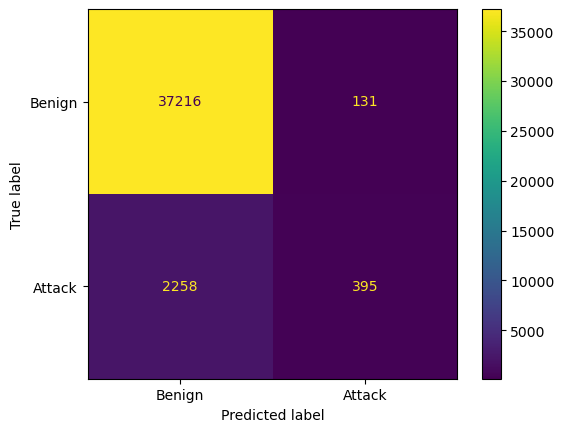

In [22]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Attack"]
)

disp.plot()
plt.show()

### Baseline 2 — Balanced Logistic Regression

### Much better attack detection:

### 70% accuracy → 89% attack recall

### Imporoved Logistic Regression

In [23]:
lr_balanced = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

lr_balanced.fit(X_train_scaled, y_train)

y_pred_balanced = lr_balanced.predict(X_test_scaled)

In [24]:
from sklearn.metrics import classification_report, confusion_matrix

print(classification_report(y_test, y_pred_balanced))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_balanced))


              precision    recall  f1-score   support

           0       0.99      0.69      0.81     37347
           1       0.17      0.89      0.28      2653

    accuracy                           0.70     40000
   macro avg       0.58      0.79      0.55     40000
weighted avg       0.93      0.70      0.77     40000

Confusion Matrix:
[[25598 11749]
 [  280  2373]]


## Build the ANN

> **Goal:** train an Artificial Neural Network that looks at **one network flow** (10 numeric features) and decides **Benign (0)** or **Attack (1)**.

This section walks through the ANN from the inside out:

| # | Topic | What you will see |
|---|-------|-------------------|
| 1 | Setup & hyper-parameters | one `CONFIG` dictionary controls everything |
| 2 | Architecture | layers, neurons, parameter count, network diagram |
| 3 | Neurons & activation functions | ReLU / Sigmoid / Tanh / Leaky-ReLU and their derivatives |
| 4 | Forward propagation | computed **by hand in NumPy** and checked against Keras |
| 5 | Loss & backpropagation | gradients derived **by hand** and checked against TensorFlow's autograd |
| 6 | Training | epochs, batch size, learning rate, class weights, callbacks |
| 7 | Loss / accuracy / recall / AUC curves | overfitting diagnosis |
| 8 | Evaluation | predictions, confusion matrix, NIDS metrics, ROC & PR curves |
| 9 | Predictions & error analysis | real flows, single-flow detector, most confident mistakes |
| 10 | Inside the network | weights, dead neurons, permutation feature importance |
| 11 | Hyper-parameter experiments | learning rate, batch size, activation, architecture |

> ⚠️ Run the notebook from the top (**Kernel → Restart & Run All**). This section re-uses `X_train`, `X_train_scaled`, `X_test_scaled`, `y_train`, `y_test`, `scaler` and `df` from the earlier cells.

### 📋 What changed compared with your original ANN section

**How to read the cells below:** every code cell starts with a `PURPOSE` line and a `STATUS` line.
`STATUS: NEW` = did not exist before · `STATUS: CHANGED` = replaces something you had · `STATUS: SAME` = same logic as before.
Comments inside the code explain what each important line does.

| Topic | Your original ANN | Now |
|-------|-------------------|-----|
| Model definition | `Dense(64, input_shape=(10,))` (caused a Keras warning) | `Input` layer + named layers, built by a reusable `build_ann()` |
| Architecture | 10 → 64 → 32 → 1 | **same** 10 → 64 → 32 → 1 (so results stay comparable) + diagram and parameter table |
| Hyper-parameters | typed inside the code | one `CONFIG` dictionary |
| Validation data | `validation_split=0.2` (last 20 %, not stratified) | stratified split, with class-weighted validation loss |
| Training | 20 fixed epochs | up to 30 epochs with `EarlyStopping` + `ReduceLROnPlateau` |
| Metrics tracked | accuracy | accuracy, **precision, recall, AUC** every epoch |
| Curves | 2 plots | 6-panel figure (+ best epoch, learning-rate schedule, overfitting check) |
| Evaluation | text report + text matrix | plotted confusion matrices, 10 metrics, ROC / PR curves, probability histogram |
| ANN vs Logistic Regression | hard-coded text | table computed live |
| Theory | – | activation functions, **forward propagation** and **backpropagation** done by hand and verified |
| Predictions | – | sample table, `predict_flow()` function, error analysis |
| Inside the network | – | weights, dead neurons, permutation feature importance |
| Experiments | – | learning rate, batch size, activation, architecture |
| Cleanup | 3 duplicate "TensorFlow version" cells, 2 empty cells | merged / removed |

**Names that were kept on purpose** (your later cells use them): `ann_model`, `history`, `y_prob_ann` (shape `(n, 1)`), `y_pred_ann` (shape `(n,)`), `class_weight_dict`, and the metric variables `accuracy, precision, recall, f1, fpr, fnr`.

### 1. Setup & hyper-parameters

Every important knob of the ANN lives in the single `CONFIG` dictionary below, so experiments are easy to repeat and the project is reproducible (fixed random seed).

In [25]:
# PURPOSE: import all libraries + fix the random seed.
# STATUS : CHANGED - your 3 repeated 'TensorFlow version' cells and the sys-version cell are merged into this one.
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# TensorFlow = the deep-learning engine; Keras (inside it) gives the simple layer-building API
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from IPython.display import display

# scikit-learn helpers already used in the ML part: data splitting, class weights, evaluation metrics
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay,
    roc_curve, roc_auc_score, precision_recall_curve, average_precision_score,
    matthews_corrcoef, balanced_accuracy_score,
)

# A fixed 'seed' makes random parts (weight initialisation, shuffling) repeat exactly,
# so you get the same results on every run
SEED = 42
keras.utils.set_random_seed(SEED)          # seeds Python, NumPy and TensorFlow together

print("TensorFlow version:", tf.__version__)
print("Keras version     :", keras.__version__)
# 0 GPUs is normal on Windows - this small network trains quickly on the CPU
print("GPUs available    :", len(tf.config.list_physical_devices("GPU")))

TensorFlow version: 2.21.0
Keras version     : 3.15.1
GPUs available    : 0


In [26]:
# PURPOSE: collect every hyper-parameter in one dictionary, then prepare train / validation data and class weights.
# STATUS : NEW (class weights existed in your old cell 50, but are now computed from the training part only).
# ---------------- ONE place to control the whole ANN ----------------
CONFIG = {
    "hidden_units"       : (64, 32),   # neurons per hidden layer
    "hidden_activation"  : "relu",     # activation of hidden layers
    "dropout"            : 0.0,        # 0 = no dropout (kept simple for the main model)
    "learning_rate"      : 1e-3,       # step size of the optimizer
    "batch_size"         : 256,        # samples per weight update
    "max_epochs"         : 30,         # upper limit - EarlyStopping may stop sooner
    "val_size"           : 0.20,       # part of the TRAIN set kept for validation
    "early_stop_patience": 5,          # epochs without improvement before stopping
    "threshold"          : 0.50,       # probability >= threshold  ->  "Attack"
}

# the 10 input column names - used for plots and for predict_flow()
FEATURE_NAMES = list(X_train.columns)
N_FEATURES    = len(FEATURE_NAMES)

# ---- Train / validation split (stratified so both keep the same attack ratio) ----
# The TEST set is never touched during training - it is only used for final evaluation.
# Split the TRAIN set again: 80% to learn from, 20% to monitor during training.
# stratify keeps the same attack % in both. Original code used validation_split (last 20%, unshuffled).
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_scaled, y_train.values,
    test_size=CONFIG["val_size"], stratify=y_train.values, random_state=SEED
)

# ---- Class weights: the data is ~93% benign, so attacks get a bigger voice in the loss ----
# 'balanced' gives rare attacks a large weight and common benign flows a small one
classes = np.unique(y_tr)
cw      = compute_class_weight(class_weight="balanced", classes=classes, y=y_tr)
# dict like {0: 0.54, 1: 7.5} - name kept from your original code
class_weight_dict = {int(c): float(w) for c, w in zip(classes, cw)}

# Same weights for the validation loss, so train-loss and val-loss are comparable on one plot
# Give validation samples the same weights, so validation loss is measured the same way as training loss
w_val = np.where(y_val == 1, class_weight_dict[1], class_weight_dict[0]).astype("float32")

# number of mini-batches (= weight updates) per epoch
steps_per_epoch = int(np.ceil(len(X_tr) / CONFIG["batch_size"]))

# show what we computed
print("Class weights :", {k: round(v, 3) for k, v in class_weight_dict.items()})
print(f"\n{'Set':<12}{'Rows':>10}{'Attack %':>12}")
# sanity check: all three sets should have ~the same attack %
for name, yy in [("Train", y_tr), ("Validation", y_val), ("Test", y_test.values)]:
    print(f"{name:<12}{len(yy):>10,}{yy.mean()*100:>11.2f}%")
print(f"\nBatch size {CONFIG['batch_size']}  ->  {steps_per_epoch} weight updates per epoch")

Class weights : {0: 0.536, 1: 7.538}

Set               Rows    Attack %
Train          128,000       6.63%
Validation      32,000       6.63%
Test            40,000       6.63%

Batch size 256  ->  500 weight updates per epoch


**📖 What this output shows**

* **Class weights** – benign ≈ 0.54, attack ≈ 7.5: one missed attack hurts the loss about 13 times more than one false alarm. Without this the network would just predict "Benign" almost always.
* **The three sets** – *Train* is used to learn, *Validation* to watch for overfitting and to trigger the callbacks, *Test* only at the very end. The attack % should be almost identical in all three (that is what `stratify` guarantees).
* **Updates per epoch** – training rows ÷ batch size. With 128,000 training rows and batch size 256 this is 500, which is the `500/500` you saw in your old training log.

### 2. Architecture

```
 Input layer          Hidden layer 1        Hidden layer 2        Output layer
 10 features   ──►    64 neurons (ReLU) ──► 32 neurons (ReLU) ──► 1 neuron (Sigmoid)  ──►  P(attack)
```

| Layer | Neurons | Activation | Role |
|-------|:------:|:----------:|------|
| Input | 10 | – | the 10 standardised flow features (ports, protocol, bytes, packets, flags, duration) |
| Hidden 1 | 64 | ReLU | learns many simple patterns / combinations of features |
| Hidden 2 | 32 | ReLU | combines those patterns into higher-level "attack-like" behaviour |
| Output | 1 | Sigmoid | squashes the result into a **probability between 0 and 1** |

The network narrows towards the output (64 → 32 → 1), a typical *funnel* design that compresses information into a single decision.

**Counting parameters** – every connection has a *weight*, every neuron has a *bias*:

$$\text{params} = (\text{inputs} \times \text{neurons}) + \text{neurons}$$

* Hidden 1: $10 \times 64 + 64 = 704$
* Hidden 2: $64 \times 32 + 32 = 2{,}080$
* Output: $32 \times 1 + 1 = 33$
* **Total = 2,817 trainable parameters**

> 💡 The inputs must be **standardised** (done earlier with `StandardScaler`). Raw `IN_BYTES` can be in the millions while `PROTOCOL` is 6 or 17 – without scaling, the big numbers would dominate the weight updates.

In [27]:
# PURPOSE: a function that builds + compiles the ANN. The same function is used for the main model and for the experiments in section 11.
# STATUS : CHANGED - same 64-32-1 architecture as your original, but with an Input layer (no more Keras warning),
#          named layers, and extra metrics (precision, recall, AUC). Plus a NEW parameter table.
def build_ann(hidden_units=CONFIG["hidden_units"],
              activation=CONFIG["hidden_activation"],
              dropout=CONFIG["dropout"],
              learning_rate=CONFIG["learning_rate"],
              n_features=N_FEATURES,
              name="nids_ann"):
    """Builds and compiles the ANN. Used for the main model AND the experiments."""
    keras.utils.set_random_seed(SEED)                       # same initial weights every time
    # Sequential = layers stacked one after another
    model = keras.Sequential(name=name)
    # Input layer: 10 numbers per flow (replaces the old input_shape=(10,) argument that caused the warning)
    model.add(layers.Input(shape=(n_features,), name="flow_features"))
    # add one fully-connected (Dense) hidden layer per entry in hidden_units
    for i, units in enumerate(hidden_units, start=1):
        model.add(layers.Dense(units, activation=activation, name=f"hidden_{i}"))
        # Dropout randomly switches off neurons while training to fight overfitting (0.0 = off for the main model)
        if dropout > 0:
            model.add(layers.Dropout(dropout, name=f"dropout_{i}"))
    # output layer: 1 neuron + sigmoid = probability that the flow is an attack
    model.add(layers.Dense(1, activation="sigmoid", name="output"))

    # compile = choose the loss, the optimizer and the metrics to track
    model.compile(
        # Adam = gradient descent with an adaptive step size per weight
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        # binary cross-entropy = standard loss for 2-class problems
        loss="binary_crossentropy",
        # tracked each epoch, so we can plot recall / precision / AUC and not only accuracy
        metrics=[
            "accuracy",
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
            keras.metrics.AUC(name="auc"),
        ],
    )
    return model


# build the main model using the CONFIG values (same variable name as your original code)
ann_model = build_ann()
# Keras' own table: layers, output shapes, parameters
ann_model.summary()

# Parameter breakdown - verify the hand calculation above
# our own table, to double-check the parameter maths written in the markdown above
rows = []
for layer in ann_model.layers:
    if layer.get_weights():
        W, b = layer.get_weights()
        rows.append({
            "Layer": layer.name,
            "Activation": layer.activation.__name__,
            "Neurons": W.shape[1],
            "Weight matrix": f"{W.shape[0]} x {W.shape[1]}",
            "Weights": W.size,
            "Biases": b.size,
            "Parameters": W.size + b.size,
        })
param_table = pd.DataFrame(rows)
# add a TOTAL row
param_table.loc[len(param_table)] = ["TOTAL", "", "", "", param_table["Weights"].sum(),
                                      param_table["Biases"].sum(), param_table["Parameters"].sum()]
param_table

Model: "nids_ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                     │ (None, 64)                  │             704 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ hidden_2 (Dense)                     │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ output (Dense)                       │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,817 (11.00 KB)

 Trainable params: 2,817 (11.00 KB)

 Non-trainable params: 0 (0.00 B)

,Layer,Activation,Neurons,Weight matrix,Weights,Biases,Parameters
0,hidden_1,relu,64,10 x 64,640,64,704
1,hidden_2,relu,32,64 x 32,2048,32,2080
2,output,sigmoid,1,32 x 1,32,1,33
3,TOTAL,,,,2720,97,2817


**📖 Reading the summary and the table**

* `Output Shape (None, 64)` – `None` is the batch size (any number of flows at once); `64` is the number of neurons.
* The *Parameters* column must match the hand calculation above: **704 + 2,080 + 33 = 2,817**. "Trainable" means the optimizer can change them; there are no non-trainable parameters in this model.

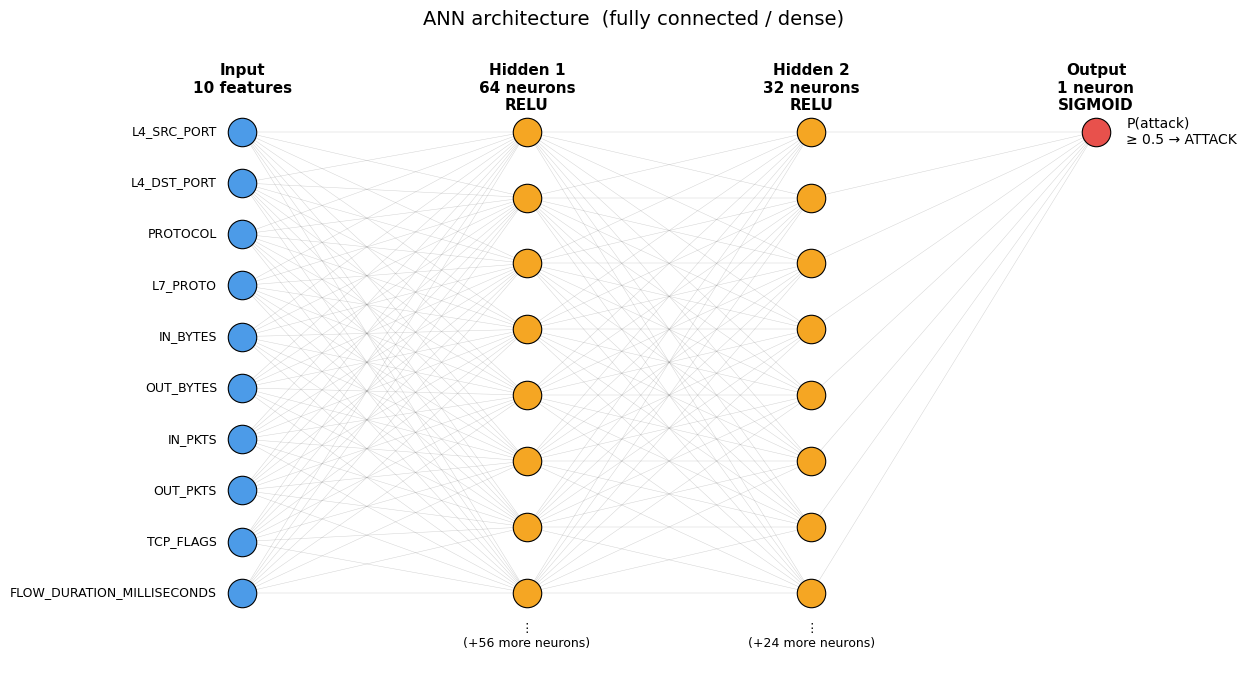

In [28]:
# PURPOSE: draw the network so you can SEE layers and neurons.
# STATUS : NEW
# ---------------- Draw the network ----------------
# plain matplotlib drawing; large layers show only 8 neurons + a '+N more' note
def draw_network(sizes, titles, input_labels, max_show=8):
    fig, ax = plt.subplots(figsize=(13, 7))
    # horizontal position of every layer
    xs = np.linspace(0.08, 0.92, len(sizes))
    layer_pos = []
    for n, x in zip(sizes, xs):
        shown = min(n, max_show if n != sizes[0] else n)
        layer_pos.append((x, np.linspace(0.88, 0.14, shown), n, shown))

    # connections
    for (x1, y1s, _, _), (x2, y2s, _, _) in zip(layer_pos[:-1], layer_pos[1:]):
        for ya in y1s:
            for yb in y2s:
                ax.plot([x1, x2], [ya, yb], color="gray", lw=0.35, alpha=0.35, zorder=1)

    # blue = input, orange = hidden, red = output
    colors = ["#4C9BE8", "#F5A623", "#F5A623", "#E8514C"]
    for li, (x, ys, n, shown) in enumerate(layer_pos):
        ax.scatter([x] * shown, ys, s=420, color=colors[min(li, len(colors) - 1)],
                   edgecolor="black", linewidth=0.8, zorder=2)
        ax.text(x, 0.99, titles[li], ha="center", va="top", fontsize=11, fontweight="bold")
        if n > shown:
            ax.text(x, 0.07, f"⋮\n(+{n - shown} more neurons)", ha="center", va="center", fontsize=9)
    for y, label in zip(layer_pos[0][1], input_labels):
        ax.text(layer_pos[0][0] - 0.025, y, label, ha="right", va="center", fontsize=9)

    ax.text(layer_pos[-1][0] + 0.03, layer_pos[-1][1][0], "P(attack)\n≥ 0.5 → ATTACK", va="center", fontsize=10)
    ax.set_xlim(-0.12, 1.05); ax.set_ylim(0, 1.02); ax.axis("off")
    ax.set_title("ANN architecture  (fully connected / dense)", fontsize=14, pad=14)
    plt.tight_layout(); plt.show()


# the diagram is generated FROM the CONFIG, so it updates automatically if you change the architecture
hidden = CONFIG["hidden_units"]
draw_network(
    sizes  = [N_FEATURES, *hidden, 1],
    titles = [f"Input\n{N_FEATURES} features"]
             + [f"Hidden {i+1}\n{u} neurons\n{CONFIG['hidden_activation'].upper()}" for i, u in enumerate(hidden)]
             + ["Output\n1 neuron\nSIGMOID"],
    input_labels = FEATURE_NAMES,
)

### 3. Neurons & activation functions

**One neuron** does just two things:

1. a **weighted sum** of its inputs plus a bias: $\;z = w_1x_1 + w_2x_2 + \dots + w_nx_n + b = \mathbf{w}\cdot\mathbf{x} + b$
2. an **activation function**: $\;a = f(z)$

Without activation functions, stacking layers would still collapse into one big *linear* model (just like Logistic Regression). The non-linearity is what lets the ANN learn curved, complicated decision boundaries.

| Function | Formula | Output range | Used here for |
|----------|---------|:-----------:|---------------|
| **ReLU** | $\max(0, z)$ | $[0, \infty)$ | hidden layers – fast, no vanishing gradient for $z>0$ |
| **Sigmoid** | $\dfrac{1}{1+e^{-z}}$ | $(0, 1)$ | output layer – gives a probability |
| Tanh | $\dfrac{e^z-e^{-z}}{e^z+e^{-z}}$ | $(-1, 1)$ | compared in the experiments at the end |
| Leaky ReLU | $\max(0.1z,\, z)$ | $(-\infty, \infty)$ | fixes "dead" ReLU neurons |

The **derivative** (right plot) matters for backpropagation: where it is ≈ 0 (flat parts of Sigmoid/Tanh), learning becomes very slow – the *vanishing gradient* problem. ReLU keeps a gradient of exactly 1 for positive inputs.

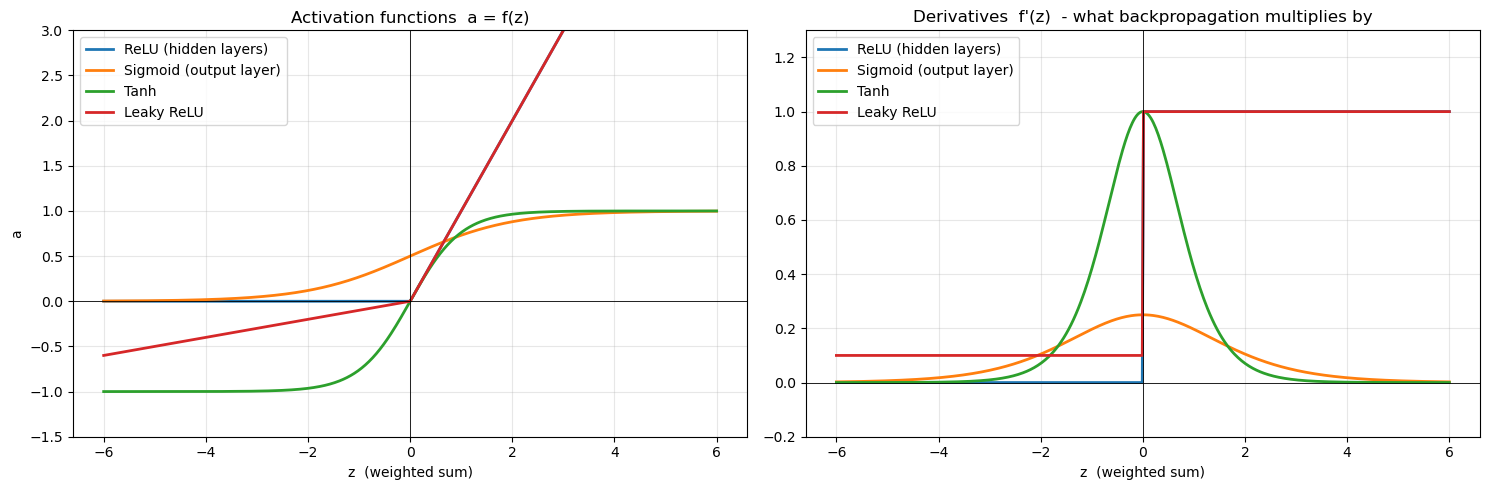

In [29]:
# PURPOSE: plot the activation functions and their derivatives.
# STATUS : NEW (relu() and sigmoid() are re-used below by the manual forward pass).
# ---------------- Activation functions & their derivatives ----------------
# each activation f(z) is followed by its derivative f'(z), needed in backpropagation
def relu(z):       return np.maximum(0, z)
def d_relu(z):     return (z > 0).astype(float)
def sigmoid(z):    return 1 / (1 + np.exp(-z))
def d_sigmoid(z):  s = sigmoid(z); return s * (1 - s)
def tanh(z):       return np.tanh(z)
def d_tanh(z):     return 1 - np.tanh(z) ** 2
def leaky_relu(z, a=0.1):   return np.where(z > 0, z, a * z)
def d_leaky_relu(z, a=0.1): return np.where(z > 0, 1.0, a)

# range of possible weighted sums z = w.x + b
z = np.linspace(-6, 6, 500)
# name -> (function, derivative)
acts = {
    "ReLU (hidden layers)":      (relu, d_relu),
    "Sigmoid (output layer)":    (sigmoid, d_sigmoid),
    "Tanh":                      (tanh, d_tanh),
    "Leaky ReLU":                (leaky_relu, d_leaky_relu),
}

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
# left plot = the function, right plot = its slope
for name, (f, df_) in acts.items():
    axes[0].plot(z, f(z), lw=2, label=name)
    axes[1].plot(z, df_(z), lw=2, label=name)

axes[0].set_title("Activation functions  a = f(z)")
axes[1].set_title("Derivatives  f'(z)  - what backpropagation multiplies by")
for ax in axes:
    ax.axhline(0, color="black", lw=0.6); ax.axvline(0, color="black", lw=0.6)
    ax.set_xlabel("z  (weighted sum)"); ax.set_ylim(-1.5, 3); ax.grid(alpha=0.3); ax.legend()
axes[0].set_ylabel("a")
axes[1].set_ylim(-0.2, 1.3)
plt.tight_layout(); plt.show()

### 4. Forward propagation

**Forward propagation** is how the network makes a prediction: the data flows from the input to the output, layer by layer.

$$
\begin{aligned}
\mathbf{z}^{[1]} &= \mathbf{x}\,W^{[1]} + \mathbf{b}^{[1]}, & \mathbf{a}^{[1]} &= \text{ReLU}(\mathbf{z}^{[1]}) \\
\mathbf{z}^{[2]} &= \mathbf{a}^{[1]}\,W^{[2]} + \mathbf{b}^{[2]}, & \mathbf{a}^{[2]} &= \text{ReLU}(\mathbf{z}^{[2]}) \\
z^{[3]} &= \mathbf{a}^{[2]}\,W^{[3]} + b^{[3]}, & \hat{y} &= \sigma(z^{[3]})
\end{aligned}
$$

Below, we compute this **ourselves with plain NumPy matrix multiplication** using the model's *current (still untrained, randomly initialised)* weights, and prove that it gives exactly the same answer as Keras.

In [30]:
# PURPOSE: forward propagation written by hand with NumPy, then compared with Keras.
# STATUS : NEW
# weights = [W1, b1, W2, b2, W3, b3] - exactly what Keras stores
def manual_forward(weights, x):
    """Forward propagation written out by hand (2 hidden ReLU layers + sigmoid output)."""
    W1, b1, W2, b2, W3, b3 = weights
    # z = weighted sum, a = after activation. '@' is matrix multiplication
    z1 = x  @ W1 + b1;  a1 = relu(z1)          # hidden layer 1
    z2 = a1 @ W2 + b2;  a2 = relu(z2)          # hidden layer 2
    z3 = a2 @ W3 + b3;  y_hat = sigmoid(z3)    # output layer
    return {"z1": z1, "a1": a1, "z2": z2, "a2": a2, "z3": z3, "y_hat": y_hat}


# get_weights() returns [W1,b1,W2,b2,W3,b3]; we keep COPIES of the untrained weights so we can compare after training
init_weights = [w.copy() for w in ann_model.get_weights()]   # keep a copy of the starting point
# ONE network flow, already scaled (shape 1 x 10)
x0  = X_tr[:1].astype("float32")                             # ONE network flow (already scaled)
# run the hand-written forward pass
fwd = manual_forward(init_weights, x0)

print("Input flow x (scaled):", np.round(x0[0], 3), "\n")
# (key, description) pairs just for printing
steps = [
    ("z1",    "Hidden 1  z1 = x.W1 + b1"),
    ("a1",    "Hidden 1  a1 = ReLU(z1)"),
    ("z2",    "Hidden 2  z2 = a1.W2 + b2"),
    ("a2",    "Hidden 2  a2 = ReLU(z2)"),
    ("z3",    "Output    z3 = a2.W3 + b3"),
    ("y_hat", "Output    y_hat = sigmoid(z3)"),
]
for key, desc in steps:
    print(f"{desc:<34} shape {str(fwd[key].shape):<9} first values: {np.round(fwd[key][0, :4], 4)}")

# ask Keras for the same prediction
keras_out = ann_model.predict(x0, verbose=0)
print(f"\nManual NumPy  P(attack) = {fwd['y_hat'][0, 0]:.6f}")
print(f"Keras         P(attack) = {keras_out[0, 0]:.6f}")
# True = our maths is exactly what Keras does
print("Identical?  ->", np.allclose(fwd["y_hat"], keras_out, atol=1e-5))
print(f"\n(Untrained network -> prediction is close to 0.5, it has learned nothing yet.)")
print(f"ReLU switched off {np.mean(fwd['z1'] <= 0):.0%} of hidden-1 neurons for this flow (z <= 0 -> output 0).")

Input flow x (scaled): [ 0.024  0.902 -0.296  0.893 -0.032 -0.143 -0.035 -0.093  0.679 -0.05 ] 

Hidden 1  z1 = x.W1 + b1           shape (1, 64)   first values: [-0.0721  0.3852  0.1049  0.3511]
Hidden 1  a1 = ReLU(z1)            shape (1, 64)   first values: [0.     0.3852 0.1049 0.3511]
Hidden 2  z2 = a1.W2 + b2          shape (1, 32)   first values: [ 0.039  -0.1623 -0.2911  0.1834]
Hidden 2  a2 = ReLU(z2)            shape (1, 32)   first values: [0.039  0.     0.     0.1834]
Output    z3 = a2.W3 + b3          shape (1, 1)    first values: [-0.1279]
Output    y_hat = sigmoid(z3)      shape (1, 1)    first values: [0.4681]

Manual NumPy  P(attack) = 0.468064
Keras         P(attack) = 0.468064
Identical?  -> True

(Untrained network -> prediction is close to 0.5, it has learned nothing yet.)
ReLU switched off 53% of hidden-1 neurons for this flow (z <= 0 -> output 0).


**📖 What this output shows**

* Each line is one stage of the forward pass; `shape (1, 64)` = one flow, 64 neuron values.
* In hidden layer 2, several values are exactly `0` – that is ReLU switching a neuron **off** because its weighted sum was negative.
* **Before training** the prediction is close to 0.5 ("don't know"), because the weights are random.
* `Identical? True` proves that the "black box" is just these six lines of matrix maths.

### 5. Loss function & backpropagation

**Loss** – how wrong is the prediction? For a yes/no problem we use **binary cross-entropy**:

$$L = -\frac{1}{N}\sum_{i=1}^{N}\Big[\,y_i\log\hat{y}_i + (1-y_i)\log(1-\hat{y}_i)\Big]$$

A confident wrong answer (say $\hat{y}=0.01$ for a real attack) is punished very heavily; a confident right answer costs almost nothing. Because attacks are rare, each sample is also multiplied by its **class weight** (benign ≈ 0.54, attack ≈ 7.5) so the model cannot "win" by predicting *Benign* for everything.

**Backpropagation** – how should every weight change to reduce the loss? Using the **chain rule**, the error is sent backwards through the network. With sigmoid + cross-entropy the output error is beautifully simple, and each earlier layer multiplies by the weights and by the activation derivative:

$$
\begin{aligned}
\delta^{[3]} &= \hat{y} - y & \nabla_{W^{[3]}} L &= (a^{[2]})^{\top}\delta^{[3]}\\
\delta^{[2]} &= \big(\delta^{[3]}(W^{[3]})^{\top}\big)\odot \text{ReLU}'(z^{[2]}) & \nabla_{W^{[2]}} L &= (a^{[1]})^{\top}\delta^{[2]}\\
\delta^{[1]} &= \big(\delta^{[2]}(W^{[2]})^{\top}\big)\odot \text{ReLU}'(z^{[1]}) & \nabla_{W^{[1]}} L &= \mathbf{x}^{\top}\delta^{[1]}
\end{aligned}
$$

(the bias gradients are the column sums of each $\delta$). Then **gradient descent** updates every weight a small step *against* its gradient:

$$W \leftarrow W - \eta\,\nabla_W L \qquad (\eta = \text{learning rate})$$

Below we derive all gradients by hand for one batch of 256 flows and compare them with what TensorFlow's automatic differentiation (`GradientTape`) computes. If our maths is right, the difference is ≈ 0.

Batch loss before the update: 0.6487   (Keras: 0.6487)



,Parameter,Shape,Mean |gradient|,Max |manual - autograd|,Match
0,W1,"(10, 64)",0.005724,5.587935e-09,True
1,b1,"(64,)",0.018895,7.450581e-09,True
2,W2,"(64, 32)",0.006084,3.725290e-09,True
3,b2,"(32,)",0.041007,7.450581e-09,True
4,W3,"(32, 1)",0.046272,5.960464e-08,True
5,b3,"(1,)",0.421358,5.960464e-08,True



One SGD step (learning rate 0.1):  loss 0.6487  ->  0.5882   (lower - the weights moved in the right direction)
(Adam, used for real training, is a smarter version of this: it keeps a separate adaptive step size per weight.)


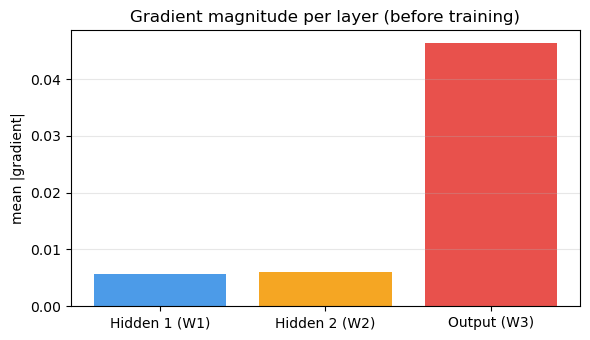

In [31]:
# PURPOSE: backpropagation by hand (chain rule), checked against TensorFlow's automatic gradients, plus one gradient-descent step.
# STATUS : NEW
# ---------- One mini-batch of 256 flows ----------
# one mini-batch of 256 flows (same size as the real training batches)
batch_x = X_tr[:256].astype("float32")
batch_y = y_tr[:256].reshape(-1, 1).astype("float32")
# N = batch size; gradients are averaged over N
N = len(batch_x)
# untrained weights
W1, b1, W2, b2, W3, b3 = init_weights

# binary cross-entropy written out by hand (eps avoids log(0))
def bce(y, p, eps=1e-7):
    p = np.clip(p, eps, 1 - eps)
    return float(np.mean(-(y * np.log(p) + (1 - y) * np.log(1 - p))))

# ---------- Forward pass ----------
# forward pass first - backprop needs the stored z and a values
fwd = manual_forward(init_weights, batch_x)
# loss of this batch BEFORE any update
loss_before = bce(batch_y, fwd["y_hat"])

# ---------- Backward pass (chain rule, by hand) ----------
# error at the output: (prediction - truth) / N
d3  = (fwd["y_hat"] - batch_y) / N                 # error at the output
gW3 = fwd["a2"].T @ d3;           gb3 = d3.sum(axis=0)

# send the error back through W3, then multiply by ReLU'(z2) (1 if z2 > 0 else 0)
d2  = (d3 @ W3.T) * (fwd["z2"] > 0)                # send error back through W3, then ReLU'
gW2 = fwd["a1"].T @ d2;           gb2 = d2.sum(axis=0)

# same again one layer further back
d1  = (d2 @ W2.T) * (fwd["z1"] > 0)                # send error back through W2, then ReLU'
gW1 = batch_x.T @ d1;             gb1 = d1.sum(axis=0)

# gradients of the 6 parameter arrays, in the same order as Keras' weights
manual_grads = [gW1, gb1, gW2, gb2, gW3, gb3]
names        = ["W1", "b1", "W2", "b2", "W3", "b3"]

# ---------- Same gradients from TensorFlow autograd ----------
# TensorFlow records the forward pass, then differentiates it automatically = ground truth
with tf.GradientTape() as tape:
    preds = ann_model(batch_x, training=False)
    loss  = tf.reduce_mean(keras.losses.binary_crossentropy(batch_y, preds))
# gradients from TensorFlow
tape_grads = [g.numpy() for g in tape.gradient(loss, ann_model.trainable_variables)]

# if Match is True for every row, our hand-derived backprop is correct
check = pd.DataFrame({
    "Parameter": names,
    "Shape": [str(g.shape) for g in manual_grads],
    "Mean |gradient|": [np.abs(g).mean() for g in manual_grads],
    "Max |manual - autograd|": [np.abs(m - t).max() for m, t in zip(manual_grads, tape_grads)],
    "Match": [np.allclose(m, t, atol=1e-6) for m, t in zip(manual_grads, tape_grads)],
})
print(f"Batch loss before the update: {loss_before:.4f}   (Keras: {float(loss):.4f})\n")
display(check)

# ---------- One gradient-descent step, written by hand ----------
# learning rate for this demo only (plain gradient descent, not Adam)
lr_demo = 0.1
# gradient descent: new weight = old weight - learning_rate * gradient
new_weights = [w - lr_demo * g for w, g in zip(init_weights, manual_grads)]
loss_after  = bce(batch_y, manual_forward(new_weights, batch_x)["y_hat"])
print(f"\nOne SGD step (learning rate {lr_demo}):  loss {loss_before:.4f}  ->  {loss_after:.4f}   "
      f"({'lower - the weights moved in the right direction' if loss_after < loss_before else 'higher'})")
print("(Adam, used for real training, is a smarter version of this: it keeps a separate adaptive step size per weight.)")

# ---------- Gradient size per layer (are the early layers still learning?) ----------
# average gradient size per layer - tiny gradients in early layers would mean 'vanishing gradients'
plt.figure(figsize=(6, 3.5))
plt.bar(["Hidden 1 (W1)", "Hidden 2 (W2)", "Output (W3)"],
        [np.abs(gW1).mean(), np.abs(gW2).mean(), np.abs(gW3).mean()],
        color=["#4C9BE8", "#F5A623", "#E8514C"])
plt.ylabel("mean |gradient|"); plt.title("Gradient magnitude per layer (before training)")
plt.grid(axis="y", alpha=0.3); plt.tight_layout(); plt.show()

**📖 What this output shows**

* The *Match* column should be `True` for all six rows and the difference around `1e-8` (floating-point rounding only): our hand-derived chain rule gives the same gradients as TensorFlow.
* **Mean |gradient|** tells you how strongly each parameter would change. It is normal for the output layer to have the biggest gradients; if the first layer were ~1000× smaller, learning there would be very slow (vanishing gradients).
* The **one SGD step** lowers the loss on this batch – that is all training is: *repeat this thousands of times* (here 500 updates × epochs), with Adam choosing smarter step sizes.

### 6. Training

| Term | Meaning | Our value |
|------|---------|-----------|
| **Epoch** | one full pass over the whole training set | up to `max_epochs` = 30 (EarlyStopping decides) |
| **Batch size** | flows processed before one weight update | 256 |
| **Iteration / step** | one weight update (= one batch) | 500 per epoch |
| **Learning rate** | size of each update step | 0.001 (halved automatically when progress stalls) |
| **Optimizer** | the rule that applies the gradients | Adam |
| **Class weights** | make rare attacks count more in the loss | ≈ 0.54 benign / 7.5 attack |

Two **callbacks** make training smarter:

* `EarlyStopping` – stops when the validation loss has not improved for 5 epochs and **restores the best weights** (protects against overfitting).
* `ReduceLROnPlateau` – halves the learning rate when validation loss stalls (big steps first, fine steps later).

> **Small batch size** → noisy but frequent updates · **Large batch size** → smooth but fewer updates.
> **High learning rate** → fast but may overshoot / diverge · **Low learning rate** → stable but slow.
> Section 11 tests exactly this.

In [32]:
# PURPOSE: TRAIN the ANN (the actual learning).
# STATUS : CHANGED - your old fit(): 20 fixed epochs, validation_split=0.2.
#          New: up to 30 epochs with EarlyStopping + ReduceLROnPlateau, stratified weighted validation data, verbose=2 (one line per epoch).
# callbacks = helpers that watch training and act automatically
callbacks = [
    # stop when val_loss has not improved for 5 epochs and go back to the best weights
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=CONFIG["early_stop_patience"],
        restore_best_weights=True, verbose=1),
    # when val_loss stalls for 2 epochs, halve the learning rate (min 0.00001)
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5, verbose=1),
]

# start the stopwatch
t0 = time.time()
# fit() = repeat: forward pass -> loss -> backprop -> weight update, for every batch of every epoch.
# 'history' keeps the per-epoch numbers for the plots (same variable name as your original code)
history = ann_model.fit(
    X_tr, y_tr,
    # data used only to MONITOR (X, y, sample weights) - never to update weights
    validation_data=(X_val, y_val, w_val),       # weighted like the training loss
    # maximum number of passes over the training set
    epochs=CONFIG["max_epochs"],
    # samples per weight update
    batch_size=CONFIG["batch_size"],
    # rare attacks count ~13x more in the loss
    class_weight=class_weight_dict,
    # switch on the two helpers defined above
    callbacks=callbacks,
    verbose=2,                                   # one clean line per epoch
)
train_time = time.time() - t0

# epoch with the lowest validation loss (+1 because Python counts from 0)
best_epoch = int(np.argmin(history.history["val_loss"])) + 1
print(f"\nTrained for {len(history.history['loss'])} epochs in {train_time:.1f}s "
      f"| best epoch = {best_epoch} (weights restored from there)")

Epoch 1/30
500/500 - 4s - 9ms/step - accuracy: 0.8118 - auc: 0.8982 - loss: 0.4199 - precision: 0.2336 - recall: 0.8060 - val_accuracy: 0.8741 - val_auc: 0.9383 - val_loss: 0.3252 - val_precision: 0.3293 - val_recall: 0.8667 - learning_rate: 0.0010
Epoch 2/30
500/500 - 2s - 3ms/step - accuracy: 0.8829 - auc: 0.9487 - loss: 0.3016 - precision: 0.3450 - recall: 0.8522 - val_accuracy: 0.8775 - val_auc: 0.9540 - val_loss: 0.2843 - val_precision: 0.3372 - val_recall: 0.8766 - learning_rate: 0.0010
Epoch 3/30
500/500 - 2s - 4ms/step - accuracy: 0.8757 - auc: 0.9589 - loss: 0.2655 - precision: 0.3353 - recall: 0.8893 - val_accuracy: 0.8675 - val_auc: 0.9604 - val_loss: 0.2491 - val_precision: 0.3286 - val_recall: 0.9553 - learning_rate: 0.0010
Epoch 4/30
500/500 - 2s - 3ms/step - accuracy: 0.8670 - auc: 0.9645 - loss: 0.2349 - precision: 0.3259 - recall: 0.9405 - val_accuracy: 0.8655 - val_auc: 0.9666 - val_loss: 0.2231 - val_precision: 0.3292 - val_recall: 0.9901 - learning_rate: 0.0010
Epoc

**📖 How to read the training log**

Each epoch prints one line:

`accuracy / auc / loss / precision / recall` → measured on the **training** data · `val_...` → measured on the **validation** data · `learning_rate` → step size used.

* Training `loss` is higher than a normal cross-entropy because attacks are multiplied by their class weight.
* `ReduceLROnPlateau reducing learning rate to ...` → progress stalled, so the step size was halved.
* `Restoring model weights from the end of the best epoch` → `EarlyStopping` went back to the best weights. If training ran all 30 epochs without stopping, the model was still improving slightly.

### 7. Learning curves – loss, accuracy, recall, precision, AUC & learning rate

How to read them:

* **Both losses falling and staying close** → the model is learning and generalising.
* **Training loss keeps falling but validation loss rises** → **overfitting** (memorising the training data). The dashed line marks the epoch we keep.
* **Both losses high and flat** → underfitting (model too small / learning rate too low).
* For a NIDS, watch **recall** (how many attacks we catch) and **precision** (how many alarms are real) – accuracy alone is misleading with 93 % benign traffic.

> ℹ️ *Loss* is class-weighted (training and validation use the same weights, so they are comparable). *Accuracy, precision, recall and AUC* are the normal, unweighted metrics.

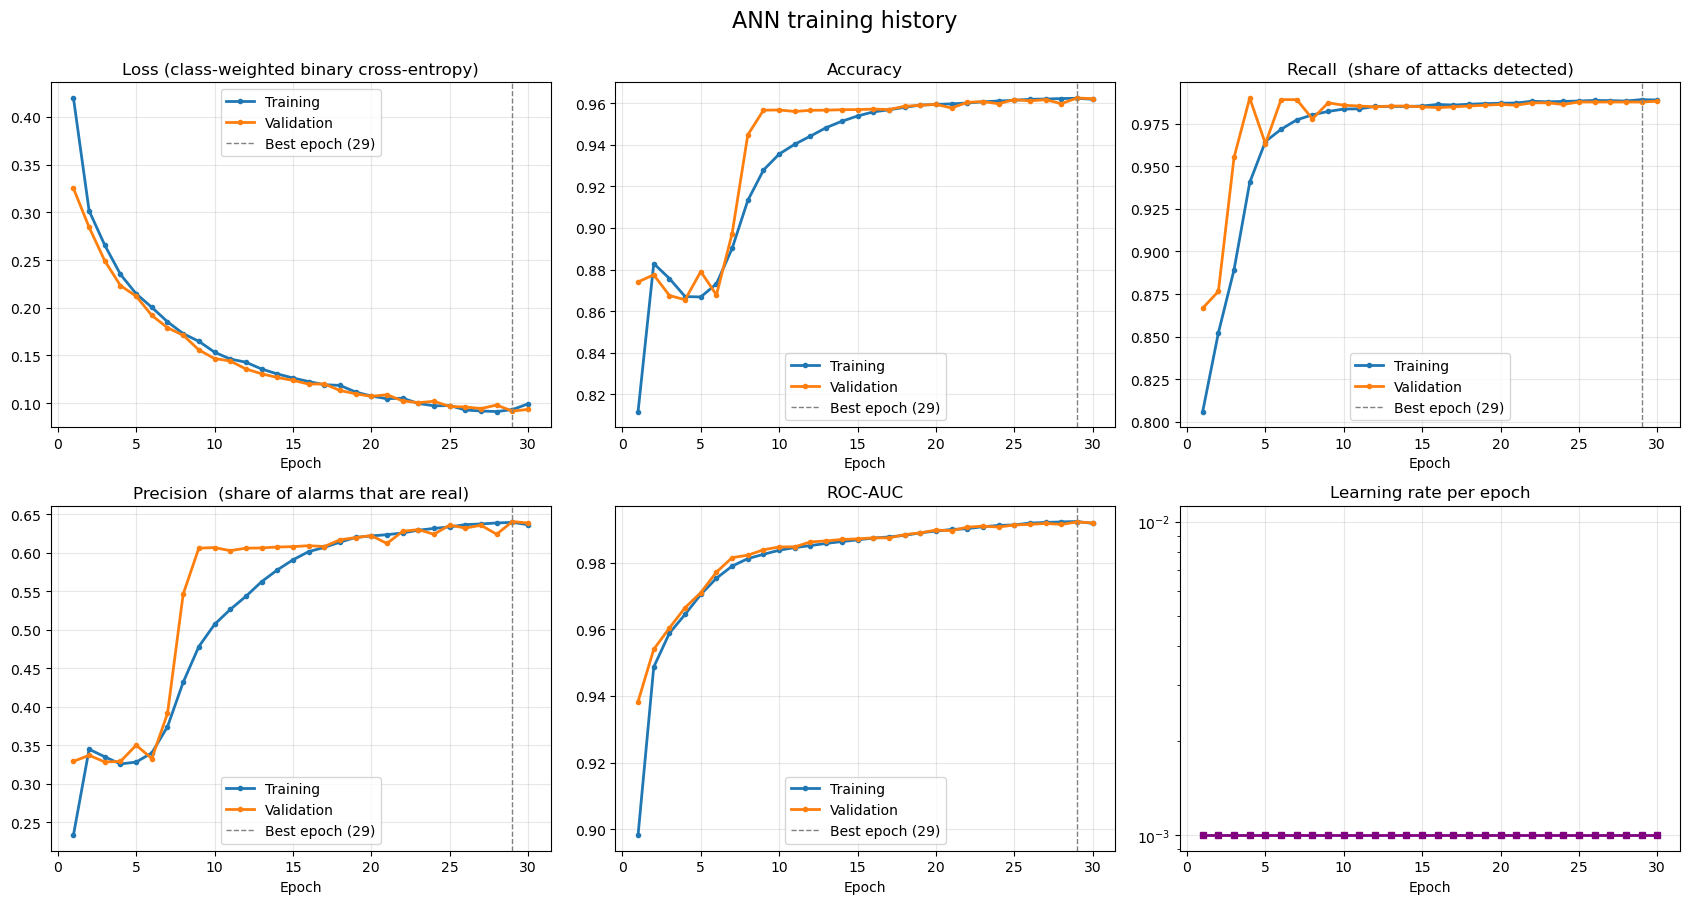

,loss,accuracy,precision,recall,auc
Training,0.0931,0.9623,0.6398,0.9892,0.9924
Validation,0.0915,0.9625,0.6409,0.9878,0.9923


Validation loss - training loss at best epoch = -0.0016  -> small gap, no serious overfitting.


In [33]:
# PURPOSE: plot the learning curves (loss, accuracy, recall, precision, AUC, learning rate).
# STATUS : CHANGED - replaces your two separate accuracy / loss plots with one 6-panel figure.
# dictionary: metric name -> list with one value per epoch
h = history.history
# epoch numbers 1, 2, 3 ...
ep = np.arange(1, len(h["loss"]) + 1)

# (history key, plot title) - 'val_' + key gives the validation curve
panels = [
    ("loss",      "Loss (class-weighted binary cross-entropy)"),
    ("accuracy",  "Accuracy"),
    ("recall",    "Recall  (share of attacks detected)"),
    ("precision", "Precision  (share of alarms that are real)"),
    ("auc",       "ROC-AUC"),
]

# 2 x 3 grid of small plots
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
axes = axes.ravel()
# blue = training, orange = validation, dashed line = epoch whose weights we keep
for ax, (key, title) in zip(axes, panels):
    ax.plot(ep, h[key],          marker="o", ms=3, lw=2, label="Training")
    ax.plot(ep, h["val_" + key], marker="o", ms=3, lw=2, label="Validation")
    ax.axvline(best_epoch, color="gray", ls="--", lw=1, label=f"Best epoch ({best_epoch})")
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.grid(alpha=0.3); ax.legend()

# learning-rate schedule
# ReduceLROnPlateau writes the learning rate into the history
lr_hist = h.get("learning_rate", [CONFIG["learning_rate"]] * len(ep))
axes[5].plot(ep, lr_hist, marker="s", ms=4, lw=2, color="purple")
axes[5].set_yscale("log"); axes[5].set_title("Learning rate per epoch")
axes[5].set_xlabel("Epoch"); axes[5].grid(alpha=0.3)

plt.suptitle("ANN training history", fontsize=16, y=1.0)
plt.tight_layout(); plt.show()

# ---- numbers at the epoch we keep ----
keys = ["loss", "accuracy", "precision", "recall", "auc"]
# table of the numbers at the kept epoch
curve_summary = pd.DataFrame(
    {k: [h[k][best_epoch - 1], h["val_" + k][best_epoch - 1]] for k in keys},
    index=["Training", "Validation"]).round(4)
display(curve_summary)

# validation loss - training loss: a big positive number = overfitting
gap = h["val_loss"][best_epoch - 1] - h["loss"][best_epoch - 1]
print(f"Validation loss - training loss at best epoch = {gap:+.4f}  ->",
      "small gap, no serious overfitting." if abs(gap) < 0.05 else
      "noticeable gap: consider more dropout / fewer epochs / a smaller network.")

**📖 Checklist for the curves**

| What you see | What it means |
|--------------|---------------|
| training and validation loss both fall and stay close | good fit |
| training loss keeps falling, validation loss turns up | overfitting → fewer epochs, more dropout, smaller network |
| both losses stay high | underfitting → bigger network, higher learning rate |
| validation curves much noisier than training | normal: validation has fewer attacks, so recall jumps in steps |
| learning-rate curve steps down | `ReduceLROnPlateau` fired because validation loss stalled |

### 8. Testing the ANN – predictions on unseen data

The test set (40,000 flows) was never used for training or validation. The sigmoid output is a **probability**; we turn it into a decision with a **threshold** (default 0.5):

$$\hat{y}_{\text{class}} = \begin{cases}\text{Attack (1)} & P(\text{attack}) \ge 0.5\\ \text{Benign (0)} & \text{otherwise}\end{cases}$$

(The threshold itself is analysed later in the notebook.)

In [34]:
# PURPOSE: predictions on the unseen TEST set.
# STATUS : SAME logic as your old cell 55 (same variable names), threshold now read from CONFIG.
# probabilities between 0 and 1, shape (n, 1) - later cells (threshold analysis) rely on this exact shape
y_prob_ann = ann_model.predict(X_test_scaled, batch_size=1024, verbose=0)    # shape (n, 1) - probabilities
# turn probabilities into hard 0 / 1 decisions with the threshold, shape (n,)
y_pred_ann = (y_prob_ann >= CONFIG["threshold"]).astype(int).ravel()        # shape (n,)   - 0 / 1 decisions

print("Predictions completed.")
print("Probability matrix shape :", y_prob_ann.shape)
print(f"Flows flagged as ATTACK  : {y_pred_ann.sum():,} of {len(y_pred_ann):,}  "
      f"({y_pred_ann.mean():.2%})   |   true attack share: {y_test.mean():.2%}")

Predictions completed.
Probability matrix shape : (40000, 1)
Flows flagged as ATTACK  : 4,117 of 40,000  (10.29%)   |   true attack share: 6.63%


**📖 Probability vs. decision** – the ANN really outputs a *probability* (`y_prob_ann`, shape `(n, 1)`). Only the threshold turns it into a class (`y_pred_ann`, shape `(n,)`). Keeping both is what makes ROC curves and the threshold analysis later in the notebook possible.

ANN Classification Report
-------------------------
              precision    recall  f1-score   support

      Benign     0.9995    0.9603    0.9795     37347
      Attack     0.6398    0.9928    0.7781      2653

    accuracy                         0.9625     40000
   macro avg     0.8196    0.9766    0.8788     40000
weighted avg     0.9756    0.9625    0.9661     40000



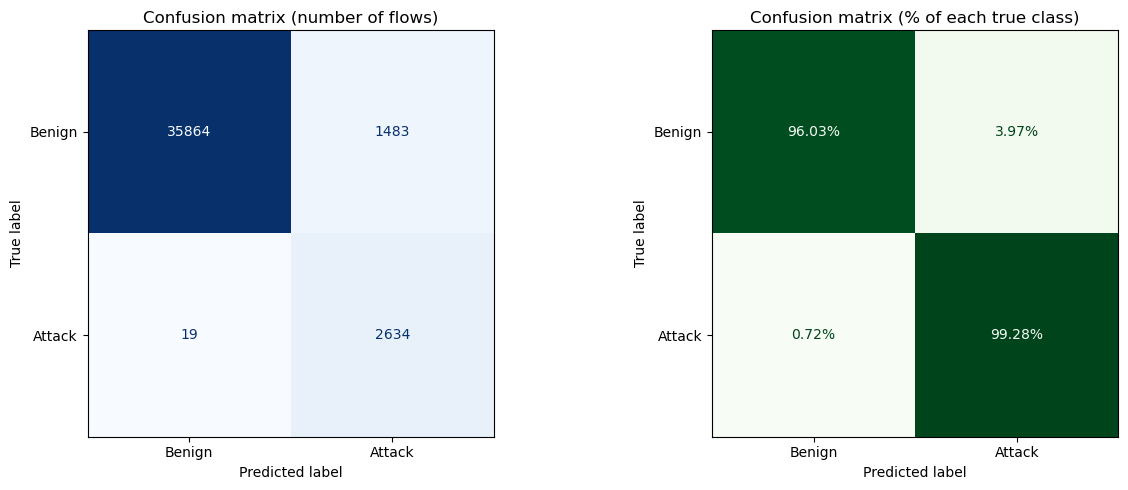

What each cell means for a NIDS:
  True Negatives  (TN) = 35,864  benign flows correctly allowed
  False Positives (FP) =  1,483  benign flows wrongly flagged  -> false alarms for the analyst
  False Negatives (FN) =     19  attacks that slipped through  -> the dangerous mistake
  True Positives  (TP) =  2,634  attacks correctly detected


In [35]:
# PURPOSE: classification report + confusion matrix (numbers and plots).
# STATUS : CHANGED - your old cell 56 printed the matrix as text; now it is a labelled plot, also normalised.
print("ANN Classification Report")
print("-------------------------")
print(classification_report(y_test, y_pred_ann, target_names=["Benign", "Attack"], digits=4))

# rows = true class, columns = predicted class
cm_ann = confusion_matrix(y_test, y_pred_ann)
# unpack the 4 cells (these names are re-assigned by later cells, that is fine)
tn, fp, fn, tp = cm_ann.ravel()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
# left: raw counts
ConfusionMatrixDisplay(cm_ann, display_labels=["Benign", "Attack"]).plot(
    ax=axes[0], cmap="Blues", values_format="d", colorbar=False)
axes[0].set_title("Confusion matrix (number of flows)")

# right: each ROW divided by its total, so you read it as recall per class
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_ann, normalize="true"),
                       display_labels=["Benign", "Attack"]).plot(
    ax=axes[1], cmap="Greens", values_format=".2%", colorbar=False)
axes[1].set_title("Confusion matrix (% of each true class)")
# no grid lines on top of the heat-map
for ax in axes: ax.grid(False)
plt.tight_layout(); plt.show()

print("What each cell means for a NIDS:")
print(f"  True Negatives  (TN) = {tn:>6,}  benign flows correctly allowed")
print(f"  False Positives (FP) = {fp:>6,}  benign flows wrongly flagged  -> false alarms for the analyst")
print(f"  False Negatives (FN) = {fn:>6,}  attacks that slipped through  -> the dangerous mistake")
print(f"  True Positives  (TP) = {tp:>6,}  attacks correctly detected")

**📖 Reading the confusion matrix**

```
                 Predicted Benign   Predicted Attack
Actual Benign        TN                 FP  ← false alarms (annoy the analyst)
Actual Attack        FN  ← missed       TP
```
* **Right plot, bottom-right cell = recall**, bottom-left = miss rate (FNR); top-right = false-alarm rate (FPR).
* In a NIDS **FN is the costly error** (an intrusion goes unnoticed), but too many FP makes analysts ignore the alerts. The threshold decides the trade-off.

In [36]:
# PURPOSE: NIDS metrics in one table.
# STATUS : CHANGED - your old cell 63 + MCC, balanced accuracy, ROC-AUC, PR-AUC. Variable names accuracy / precision / recall / f1 / fpr / fnr are unchanged.
# ---------------- NIDS metrics ----------------
# the first six names match your original cell 63
accuracy  = accuracy_score(y_test, y_pred_ann)
precision = precision_score(y_test, y_pred_ann)
recall    = recall_score(y_test, y_pred_ann)
f1        = f1_score(y_test, y_pred_ann)
# false-alarm rate = FP / (FP + TN)
fpr       = fp / (fp + tn)
fnr       = fn / (fn + tp)

# flatten (n,1) -> (n,) because the sklearn functions below want a 1-D array
prob_flat    = y_prob_ann.ravel()
# AUC uses the probabilities (not the 0/1 decisions): 1.0 = perfect ranking, 0.5 = guessing
roc_auc_ann  = roc_auc_score(y_test, prob_flat)
pr_auc_ann   = average_precision_score(y_test, prob_flat)
# MCC is a single balanced score, useful when classes are very uneven
mcc_ann      = matthews_corrcoef(y_test, y_pred_ann)
bal_acc_ann  = balanced_accuracy_score(y_test, y_pred_ann)

# table with a plain-English meaning of every metric
nids_metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall (TPR / detection rate)", "F1 Score",
               "False Positive Rate (FPR)", "False Negative Rate (FNR)",
               "Balanced Accuracy", "Matthews Corr. Coef. (MCC)", "ROC-AUC", "PR-AUC (Average Precision)"],
    "Value":  [accuracy, precision, recall, f1, fpr, fnr, bal_acc_ann, mcc_ann, roc_auc_ann, pr_auc_ann],
    "Meaning": [
        "overall share of correct decisions (misleading on imbalanced data)",
        "of all alarms raised, how many were real attacks",
        "of all real attacks, how many we caught",
        "balance between precision and recall",
        "share of benign traffic wrongly flagged (false-alarm rate)",
        "share of attacks missed (= 1 - recall)",
        "average of recall on both classes",
        "single score, robust to class imbalance (-1 ... +1)",
        "ranking quality of the probabilities, threshold-free",
        "like ROC-AUC but focused on the rare attack class",
    ],
})
nids_metrics["Value"] = nids_metrics["Value"].round(4)
nids_metrics

,Metric,Value,Meaning
0,Accuracy,0.9624,overall share of correct decisions (misleading...
1,Precision,0.6398,"of all alarms raised, how many were real attacks"
2,Recall (TPR / detection rate),0.9928,"of all real attacks, how many we caught"
3,F1 Score,0.7781,balance between precision and recall
4,False Positive Rate (FPR),0.0397,share of benign traffic wrongly flagged (false...
5,False Negative Rate (FNR),0.0072,share of attacks missed (= 1 - recall)
6,Balanced Accuracy,0.9766,average of recall on both classes
7,Matthews Corr. Coef. (MCC),0.7806,"single score, robust to class imbalance (-1 ....."
8,ROC-AUC,0.9933,"ranking quality of the probabilities, threshol..."
9,PR-AUC (Average Precision),0.9113,like ROC-AUC but focused on the rare attack class


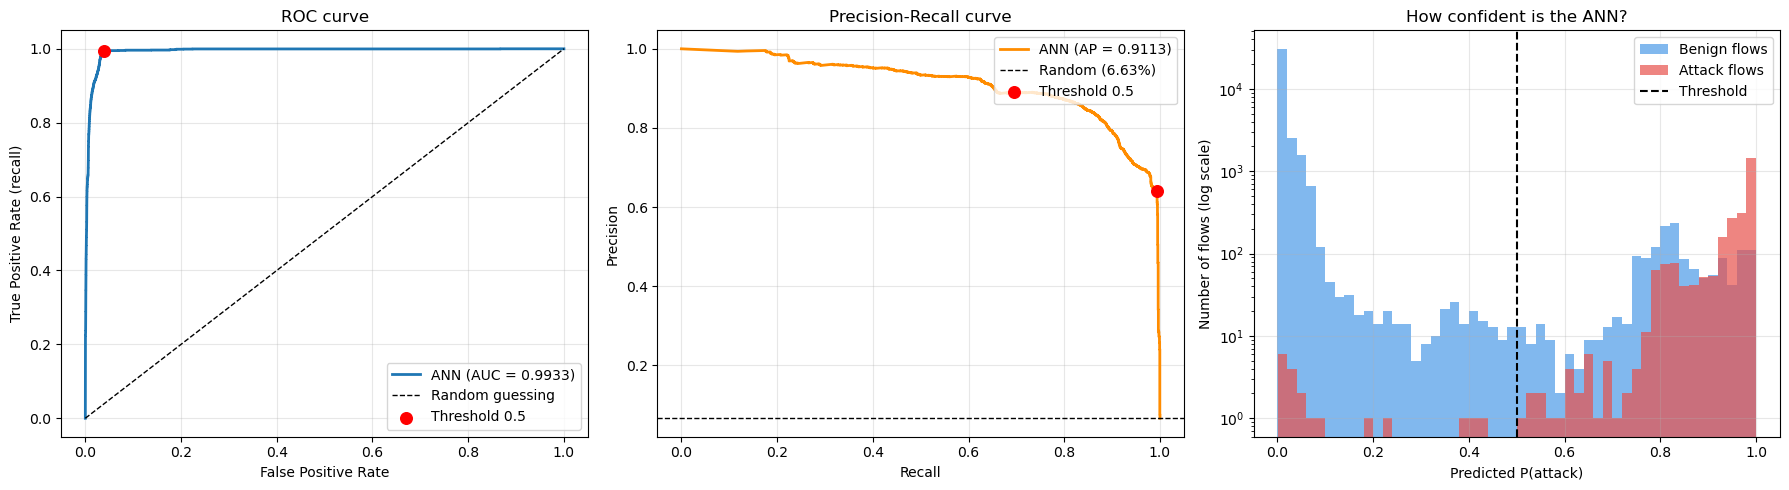

In [37]:
# PURPOSE: ROC curve, Precision-Recall curve and the distribution of predicted probabilities.
# STATUS : NEW
# ---------------- ROC curve, Precision-Recall curve, score distribution ----------------
# ROC curve points for every possible threshold
fpr_curve, tpr_curve, _ = roc_curve(y_test, prob_flat)
# Precision-Recall curve points
prec_curve, rec_curve, _ = precision_recall_curve(y_test, prob_flat)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# ROC: closer to the top-left corner = better
axes[0].plot(fpr_curve, tpr_curve, lw=2, label=f"ANN (AUC = {roc_auc_ann:.4f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Random guessing")
# red dot = where our chosen threshold sits on the curve
axes[0].scatter([fpr], [recall], color="red", zorder=5, s=70, label=f"Threshold {CONFIG['threshold']}")
axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate (recall)")
axes[0].set_title("ROC curve"); axes[0].legend(loc="lower right")

# PR curve: more informative than ROC when attacks are rare
axes[1].plot(rec_curve, prec_curve, lw=2, color="darkorange", label=f"ANN (AP = {pr_auc_ann:.4f})")
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label=f"Random ({y_test.mean():.2%})")
axes[1].scatter([recall], [precision], color="red", zorder=5, s=70, label=f"Threshold {CONFIG['threshold']}")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall curve"); axes[1].legend(loc="upper right")

# ideal: benign flows pile up at 0, attack flows pile up at 1 (log scale so the small bars are visible)
axes[2].hist(prob_flat[y_test.values == 0], bins=50, alpha=0.7, color="#4C9BE8", label="Benign flows", log=True)
axes[2].hist(prob_flat[y_test.values == 1], bins=50, alpha=0.7, color="#E8514C", label="Attack flows", log=True)
axes[2].axvline(CONFIG["threshold"], color="black", ls="--", label="Threshold")
axes[2].set_xlabel("Predicted P(attack)"); axes[2].set_ylabel("Number of flows (log scale)")
axes[2].set_title("How confident is the ANN?"); axes[2].legend()

for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**📖 Reading these three plots**

* **ROC curve** – the closer to the top-left corner, the better; the diagonal is random guessing. The red dot is our operating point.
* **Precision-Recall curve** – more honest with rare attacks. The dashed line is what a random classifier would score (= the attack share, ~6-7 %). A curve near the top-right is excellent.
* **Probability histogram** – a confident model has two tall bars, benign at 0 and attacks at 1. Bars in the middle are uncertain flows; they decide how many errors move when you change the threshold.

### The important comparison – ANN vs. Logistic Regression

A plain Logistic Regression reaches a high *accuracy* but almost never detects an attack, because predicting "Benign" for everything is already ~93 % correct. The ANN – with a non-linear model and class weights – is far better at what actually matters for a NIDS: **catching attacks**. The numbers below are computed live from the models in this notebook.

In [38]:
# PURPOSE: ANN vs Logistic Regression, computed live.
# STATUS : CHANGED - replaces your hard-coded markdown cell 57 ('96% accuracy / 97% recall'), which would go stale after re-training.
print(f"{'Model':<32}{'Accuracy':>10}{'Attack recall':>16}{'Attack precision':>18}")
print("-" * 76)
# y_pred_lr and y_pred_balanced come from the earlier ML cells
for name, pred in [("Logistic Regression", y_pred_lr),
                   ("Balanced Logistic Regression", y_pred_balanced),
                   ("ANN (this section)", y_pred_ann)]:
    print(f"{name:<32}{accuracy_score(y_test, pred):>10.2%}"
          f"{recall_score(y_test, pred):>16.2%}{precision_score(y_test, pred):>18.2%}")

Model                             Accuracy   Attack recall  Attack precision
----------------------------------------------------------------------------
Logistic Regression                 94.03%          14.89%            75.10%
Balanced Logistic Regression        69.93%          89.45%            16.80%
ANN (this section)                  96.25%          99.28%            63.98%


### 9. Predictions in practice

First a look at real flows from the test set (6 attacks + 6 benign, picked at random) with the probability the ANN assigned. Then a small `predict_flow()` function – the way the model would be used inside a real NIDS: *raw flow in → scale → ANN → alert or not*.

In [39]:
# PURPOSE: show real test flows with the probability the ANN gave.
# STATUS : NEW
# random generator with a fixed seed -> the same 12 flows every run
rng = np.random.default_rng(SEED)
# pick 6 true attacks at random
attack_idx = rng.choice(np.where(y_test.values == 1)[0], 6, replace=False)
# pick 6 true benign flows at random
benign_idx = rng.choice(np.where(y_test.values == 0)[0], 6, replace=False)
idx = np.concatenate([attack_idx, benign_idx])

# take the ORIGINAL (unscaled) values so they are readable
sample = X_test.iloc[idx].copy()
# add readable columns: actual label and attack type
sample.insert(0, "Actual", np.where(y_test.values[idx] == 1, "Attack", "Benign"))
sample.insert(1, "Attack_Type", df.loc[sample.index, "Attack"].values)
sample["P(attack)"] = y_prob_ann[idx].ravel().round(4)
sample["Predicted"] = np.where(y_pred_ann[idx] == 1, "Attack", "Benign")
# tick / cross for each prediction
sample["Correct?"]  = np.where(sample["Actual"] == sample["Predicted"], "✅", "❌")
sample.reset_index(drop=True)

,Actual,Attack_Type,L4_SRC_PORT,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,OUT_BYTES,IN_PKTS,OUT_PKTS,TCP_FLAGS,FLOW_DURATION_MILLISECONDS,P(attack),Predicted,Correct?
0,Attack,Fuzzers,64596,520,17,0.0,104,0,2,0,0,0,0.8375,Attack,✅
1,Attack,Fuzzers,22815,445,6,41.0,100034,736,82,18,19,1396,0.9994,Attack,✅
2,Attack,Exploits,59700,80,6,7.0,834,2984,10,8,27,571,0.9763,Attack,✅
3,Attack,Exploits,32822,25,6,3.0,128974,2492,116,36,27,1376,0.9998,Attack,✅
4,Attack,Reconnaissance,31017,80,6,7.0,1210,336,10,8,19,953,0.9964,Attack,✅
5,Attack,Exploits,3459,25,6,3.0,2880,1852,22,20,27,791,0.9950,Attack,✅
6,Benign,Benign,20422,80,6,7.0,1580,10168,12,18,27,1059,0.0615,Benign,✅
7,Benign,Benign,23248,111,17,11.0,568,304,4,4,0,4,0.0364,Benign,✅
8,Benign,Benign,61489,179,6,13.0,522,336,10,8,19,1478,0.8629,Attack,❌
9,Benign,Benign,12491,53,17,5.0,130,162,2,2,0,1,0.0106,Benign,✅


**📖 Reading the table** – `P(attack)` close to 1 = the ANN is sure it is an attack, close to 0 = sure it is benign, near 0.5 = unsure. The *Attack_Type* column shows which attack category the flow really belongs to (it is the label from the dataset, **not** something the ANN predicts – the ANN only decides attack / benign).

In [40]:
# PURPOSE: a function that classifies ONE new flow - how the model would be used in a real NIDS.
# STATUS : NEW
# flow = dict of the 10 raw feature values
def predict_flow(flow, threshold=CONFIG["threshold"], verbose=True):
    """flow = dict with the 10 raw (unscaled) feature values -> returns P(attack)."""
    # one-row table with the same column names the scaler saw during fit
    row  = pd.DataFrame([flow], columns=FEATURE_NAMES)
    # scale the raw values with the SAME scaler as in training, then predict (never skip the scaling!)
    prob = float(ann_model.predict(scaler.transform(row), verbose=0)[0, 0])
    is_attack = prob >= threshold
    if verbose:
        print(("🚨 ATTACK" if is_attack else "✅ Benign"),
              f"| P(attack) = {prob:.4f} | confidence = {prob if is_attack else 1 - prob:.2%}")
    return prob

# demo with real rows from the test set - replace with your own dict to try other flows
print("A real ATTACK flow from the test set:")
attack_flow = X_test[y_test == 1].iloc[0].to_dict()
print(attack_flow)
# '_ =' just hides the returned number
_ = predict_flow(attack_flow)

print("\nA real BENIGN flow from the test set:")
benign_flow = X_test[y_test == 0].iloc[0].to_dict()
print(benign_flow)
_ = predict_flow(benign_flow)

A real ATTACK flow from the test set:
{'L4_SRC_PORT': 52430.0, 'L4_DST_PORT': 3306.0, 'PROTOCOL': 6.0, 'L7_PROTO': 20.0, 'IN_BYTES': 596.0, 'OUT_BYTES': 634.0, 'IN_PKTS': 10.0, 'OUT_PKTS': 10.0, 'TCP_FLAGS': 19.0, 'FLOW_DURATION_MILLISECONDS': 837.0}
🚨 ATTACK | P(attack) = 0.9034 | confidence = 90.34%

A real BENIGN flow from the test set:
{'L4_SRC_PORT': 59380.0, 'L4_DST_PORT': 22381.0, 'PROTOCOL': 6.0, 'L7_PROTO': 11.0, 'IN_BYTES': 4616.0, 'OUT_BYTES': 3080.0, 'IN_PKTS': 28.0, 'OUT_PKTS': 30.0, 'TCP_FLAGS': 27.0, 'FLOW_DURATION_MILLISECONDS': 834.0}
✅ Benign | P(attack) = 0.0000 | confidence = 100.00%


In [41]:
# PURPOSE: error analysis - which flows does the ANN get wrong, and why might that be?
# STATUS : NEW
# ---------------- Where does the ANN go wrong? ----------------
# one table holding features + truth + prediction for every test flow
errors = X_test.copy()
errors["Actual"]      = y_test.values
errors["P(attack)"]   = prob_flat
errors["Predicted"]   = y_pred_ann
errors["Attack_Type"] = df.loc[errors.index, "Attack"].values

# benign flows flagged as attacks = false alarms
false_pos = errors[(errors.Actual == 0) & (errors.Predicted == 1)]
# attacks that slipped through = the dangerous mistakes
false_neg = errors[(errors.Actual == 1) & (errors.Predicted == 0)]

print(f"False positives: {len(false_pos):,}   |   False negatives: {len(false_neg):,}\n")

# sorted by how sure the ANN was - the most confident mistakes are the most informative
print("Top 5 most CONFIDENT false alarms (benign flows the ANN was sure were attacks):")
display(false_pos.sort_values("P(attack)", ascending=False).head(5).round(4))

print("Top 5 most CONFIDENT misses (attacks the ANN was sure were benign):")
display(false_neg.sort_values("P(attack)").head(5).round(4))

if len(false_pos):
    print("Destination ports that cause the most false alarms:")
    display(false_pos["L4_DST_PORT"].value_counts().head(5).rename("false alarms").to_frame())
if len(false_neg):
    print("Attack types that are missed most often:")
    display(false_neg["Attack_Type"].value_counts().rename("missed").to_frame())

False positives: 1,483   |   False negatives: 19

Top 5 most CONFIDENT false alarms (benign flows the ANN was sure were attacks):


,L4_SRC_PORT,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,OUT_BYTES,IN_PKTS,OUT_PKTS,TCP_FLAGS,FLOW_DURATION_MILLISECONDS,Actual,P(attack),Predicted,Attack_Type
76663,0,0,89,85.0,512,0,8,0,0,2684821,0,1.0000,1,Benign
81349,25,20591,6,3.0,15200,3372636,380,2494,17,17055,0,1.0000,1,Benign
84960,1043,53,17,5.0,12408,0,94,0,0,118200,0,0.9998,1,Benign
90413,1043,53,17,5.0,9504,0,72,0,0,118089,0,0.9998,1,Benign
29800,20218,21,6,1.0,68204,990,64,20,19,1567,0,0.9997,1,Benign


Top 5 most CONFIDENT misses (attacks the ANN was sure were benign):


,L4_SRC_PORT,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,OUT_BYTES,IN_PKTS,OUT_PKTS,TCP_FLAGS,FLOW_DURATION_MILLISECONDS,Actual,P(attack),Predicted,Attack_Type
31450,63351,389,6,112.0,7163672,32256,5416,806,19,43776,1,0.0000,0,Exploits
176104,10135,53,17,5.0,114,236,2,2,0,9,1,0.0110,0,DoS
39914,60542,6661,6,0.0,3224,676,12,12,27,1231,1,0.0116,0,Exploits
156837,54610,53,17,5.0,126,306,2,2,0,506,1,0.0160,0,Exploits
140447,63997,53,17,5.0,118,0,2,0,0,0,1,0.0162,0,Generic


Destination ports that cause the most false alarms:


,false alarms
L4_DST_PORT,
179,459
80,431
520,223
514,59
1723,53


Attack types that are missed most often:


,missed
Attack_Type,
Exploits,7
Generic,5
DoS,5
Fuzzers,1
Backdoor,1


**📖 Why error analysis?** Metrics tell you *how many* mistakes there are, this tells you *which*. Look for patterns: do false alarms cluster on one destination port (e.g. a legitimate service that looks unusual)? Are missed attacks concentrated in one attack type? Those patterns are your ideas for improvement (extra features, more samples of that attack type, a higher or lower threshold). Attack-wise recall for all attack types is also computed further below in your original cells.

### 10. Looking inside the network – weights, neurons & feature importance

* **Weight heat-map** – each column is one neuron of Hidden layer 1, each row an input feature. Red = the feature pushes the neuron up, blue = pushes it down.
* **Weight distribution** – training moves the weights away from their small random starting values.
* **Neuron activity** – a ReLU neuron that is *never* active (always $z \le 0$) is a **dead neuron**: it contributes nothing and receives no gradient.
* **Permutation importance** – shuffle one feature at a time and measure how much the ROC-AUC drops. A big drop means the ANN relies strongly on that feature. This is compared with the Random Forest's feature importance.

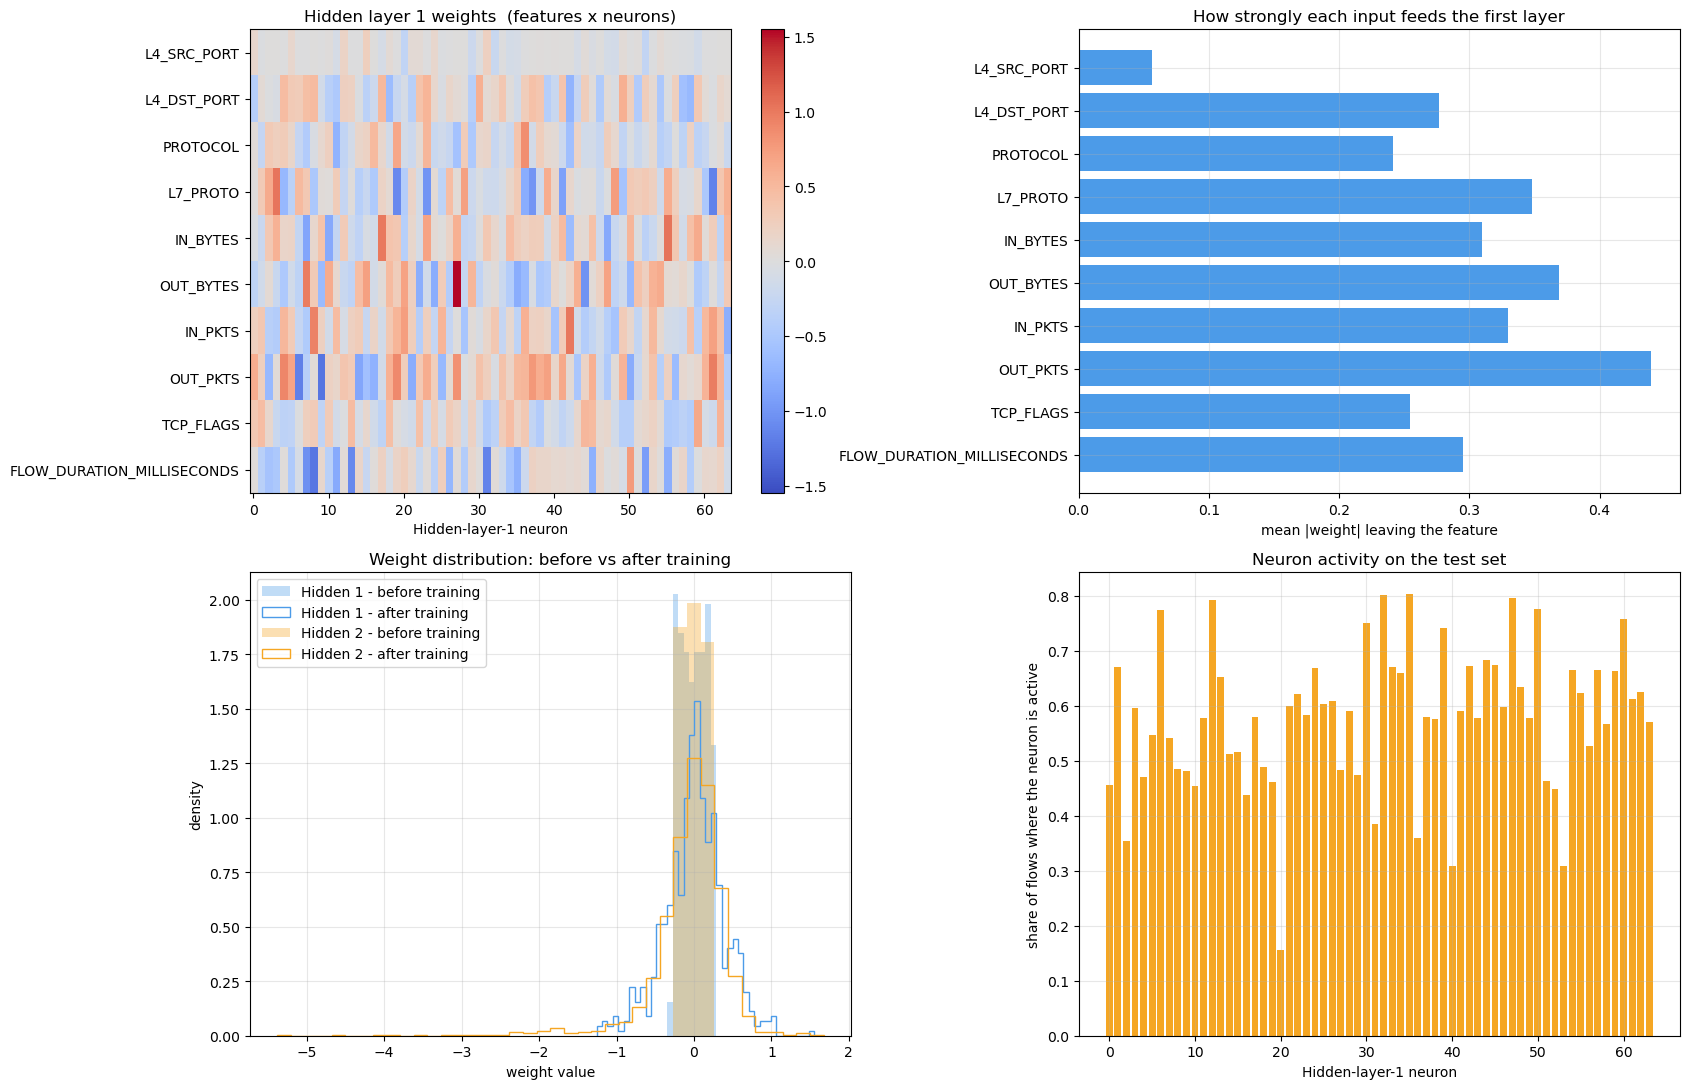

Dead neurons  - Hidden 1: 0 of 64   |   Hidden 2: 2 of 32


In [42]:
# PURPOSE: look inside the trained network: weights, weight changes, neuron activity.
# STATUS : NEW
# trained weights of the first and second hidden layer
W1_t, b1_t = ann_model.get_layer("hidden_1").get_weights()
W2_t, b2_t = ann_model.get_layer("hidden_2").get_weights()

fig, axes = plt.subplots(2, 2, figsize=(17, 11))

# (a) heat-map of first-layer weights
vmax = np.abs(W1_t).max()
im = axes[0, 0].imshow(W1_t, aspect="auto", cmap="coolwarm", vmin=-vmax, vmax=vmax)
axes[0, 0].set_yticks(range(N_FEATURES)); axes[0, 0].set_yticklabels(FEATURE_NAMES)
axes[0, 0].set_xlabel("Hidden-layer-1 neuron"); axes[0, 0].set_title("Hidden layer 1 weights  (features x neurons)")
axes[0, 0].grid(False); plt.colorbar(im, ax=axes[0, 0])

# (b) average absolute weight per input feature
axes[0, 1].barh(FEATURE_NAMES, np.abs(W1_t).mean(axis=1), color="#4C9BE8")
axes[0, 1].invert_yaxis(); axes[0, 1].set_xlabel("mean |weight| leaving the feature")
axes[0, 1].set_title("How strongly each input feeds the first layer"); axes[0, 1].grid(alpha=0.3)

# (c) weights before vs after training
for w_init, w_new, name, col in [(init_weights[0], W1_t, "Hidden 1", "#4C9BE8"),
                                 (init_weights[2], W2_t, "Hidden 2", "#F5A623")]:
    bins = np.linspace(min(w_init.min(), w_new.min()), max(w_init.max(), w_new.max()), 41)   # same bins for both
    axes[1, 0].hist(w_init.ravel(), bins=bins, alpha=0.35, color=col, density=True, label=f"{name} - before training")
    axes[1, 0].hist(w_new.ravel(),  bins=bins, histtype="step", lw=2, color=col, density=True, label=f"{name} - after training")
axes[1, 0].set_title("Weight distribution: before vs after training")
axes[1, 0].set_xlabel("weight value"); axes[1, 0].set_ylabel("density"); axes[1, 0].legend(); axes[1, 0].grid(alpha=0.3)

# (d) how often does each hidden-1 neuron fire on the test set?
# activations of every hidden neuron for every test flow (same maths as the manual forward pass)
a1_test = relu(X_test_scaled @ W1_t + b1_t)
a2_test = relu(a1_test @ W2_t + b2_t)
# fraction of flows for which each neuron is 'on' (activation > 0)
fire1 = (a1_test > 0).mean(axis=0)
axes[1, 1].bar(range(len(fire1)), fire1, color="#F5A623")
axes[1, 1].set_xlabel("Hidden-layer-1 neuron"); axes[1, 1].set_ylabel("share of flows where the neuron is active")
axes[1, 1].set_title("Neuron activity on the test set"); axes[1, 1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

print(f"Dead neurons  - Hidden 1: {int((a1_test.max(axis=0) == 0).sum())} of {W1_t.shape[1]}"
      f"   |   Hidden 2: {int((a2_test.max(axis=0) == 0).sum())} of {W2_t.shape[1]}")

**📖 What to take from these four plots**

1. **Heat-map** – no single clean pattern is normal: neurons are *mixtures* of features, which is why a neural network is hard to interpret directly.
2. **Mean |weight| per feature** – a rough hint of which inputs the first layer pays attention to (permutation importance below is more reliable).
3. **Before vs. after** – the narrow, uniform starting distribution has spread out: the weights have learned something.
4. **Neuron activity** – neurons that fire for almost all or almost no flows are less useful. *Dead neurons* (never active) can be fixed with a smaller learning rate or Leaky-ReLU.

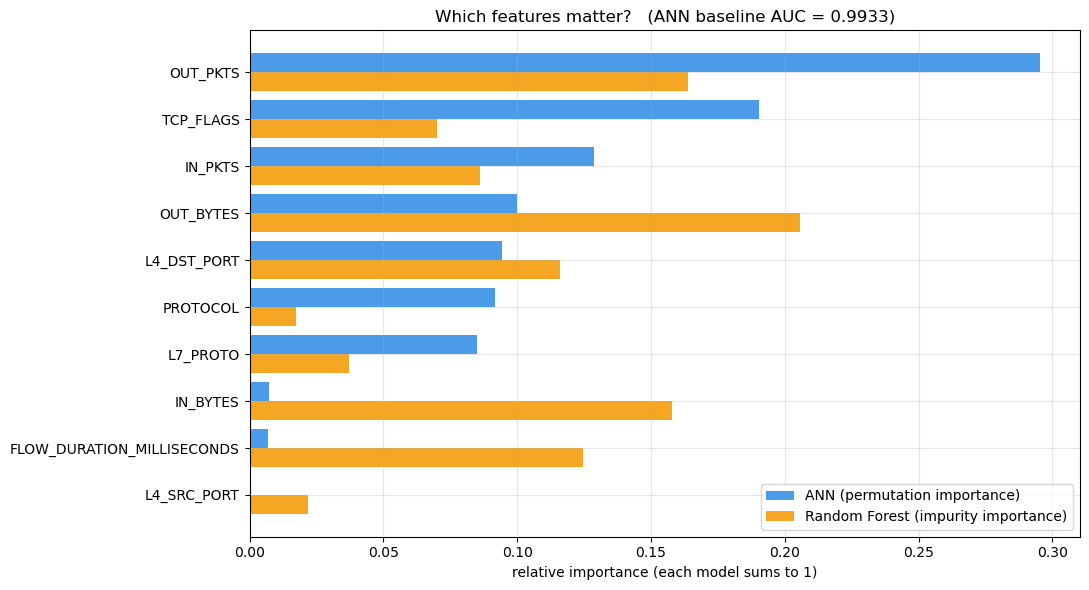

,Feature,ANN (AUC drop),ANN (normalised),Random Forest
0,OUT_PKTS,0.2748,0.2955,0.1639
1,TCP_FLAGS,0.1768,0.1902,0.0700
2,IN_PKTS,0.1197,0.1287,0.0859
3,OUT_BYTES,0.0929,0.0999,0.2056
4,L4_DST_PORT,0.0877,0.0943,0.1159
5,PROTOCOL,0.0853,0.0918,0.0173
6,L7_PROTO,0.0791,0.0850,0.0370
7,IN_BYTES,0.0067,0.0073,0.1578
8,FLOW_DURATION_MILLISECONDS,0.0064,0.0068,0.1246
9,L4_SRC_PORT,0.0005,0.0005,0.0219


In [43]:
# PURPOSE: which input features does the ANN depend on most?
# STATUS : NEW
# ---------------- Permutation importance (drop in ROC-AUC when a feature is shuffled) ----------------
# idea: shuffle ONE feature -> if the AUC drops a lot, the ANN needed that feature
def permutation_importance_auc(model, X, y, n_repeats=3, seed=SEED):
    rng = np.random.default_rng(seed)
    # AUC with all features intact
    base_auc = roc_auc_score(y, model.predict(X, batch_size=4096, verbose=0).ravel())
    result = []
    for j in range(X.shape[1]):
        drops = []
        for _ in range(n_repeats):
            Xp = X.copy()
            # destroy the information in feature j by shuffling its column
            Xp[:, j] = rng.permutation(Xp[:, j])
            drops.append(base_auc - roc_auc_score(y, model.predict(Xp, batch_size=4096, verbose=0).ravel()))
        result.append(np.mean(drops))
    return base_auc, np.array(result)

base_auc, perm_drop = permutation_importance_auc(ann_model, X_test_scaled, y_test.values)
# the drop in AUC per feature
imp = pd.DataFrame({"Feature": FEATURE_NAMES, "ANN (AUC drop)": perm_drop})
imp["ANN (normalised)"] = imp["ANN (AUC drop)"].clip(lower=0) / imp["ANN (AUC drop)"].clip(lower=0).sum()

# add the Random Forest importance from the ML section for comparison
if "rf_model" in globals():                    # compare with the Random Forest from the ML section
    imp["Random Forest"] = rf_model.feature_importances_
imp = imp.sort_values("ANN (AUC drop)", ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(11, 6))
yy = np.arange(len(imp)); bar_h = 0.4
ax.barh(yy - bar_h / 2, imp["ANN (normalised)"], bar_h, label="ANN (permutation importance)", color="#4C9BE8")
if "Random Forest" in imp:
    ax.barh(yy + bar_h / 2, imp["Random Forest"], bar_h, label="Random Forest (impurity importance)", color="#F5A623")
ax.set_yticks(yy); ax.set_yticklabels(imp["Feature"]); ax.invert_yaxis()
ax.set_xlabel("relative importance (each model sums to 1)")
ax.set_title(f"Which features matter?   (ANN baseline AUC = {base_auc:.4f})")
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

imp.round(4)

**📖 Reading the importance chart** – a *large* AUC drop means the ANN relies on that feature; ~0 means it ignores it (negative values are just noise). If the ANN and the Random Forest agree on the top features, you can trust them more. Differences are normal: the two models use features in very different ways, and impurity importance (Random Forest) is also known to favour features with many distinct values (like port numbers).

### 11. Hyper-parameter experiments

Which settings make the ANN better? Here every setting is changed **one at a time** and compared on the **validation set** (never on the test set – otherwise we would be tuning on the data we use for the final grade).

| Group | What changes | What to look for |
|-------|--------------|------------------|
| Learning rate | 0.0001 / 0.001 / 0.01 | too low = slow, too high = unstable |
| Batch size | 64 / 256 / 1024 | small = noisy but many updates, large = smooth but slow to converge |
| Activation | ReLU / Tanh / Sigmoid / ELU | sigmoid in hidden layers learns slowly (vanishing gradients) |
| Architecture | 16 / 64-32 / 128-64-32 / + Dropout | more capacity ≠ always better |

Each run trains for only 8 epochs without callbacks (so it is a fair, quick comparison) – expect a few minutes in total. Set `RUN_EXPERIMENTS = False` to skip.

In [44]:
# PURPOSE: train several variants, changing ONE hyper-parameter at a time.
# STATUS : NEW
# set to False to skip this slow section
RUN_EXPERIMENTS = True
# short runs - enough to compare, much quicker than 30 epochs
EXP_EPOCHS      = 8

# baseline settings = our main model
BASE = dict(hidden_units=CONFIG["hidden_units"], activation=CONFIG["hidden_activation"],
            dropout=CONFIG["dropout"], learning_rate=CONFIG["learning_rate"])
# remembers finished runs so the baseline is trained only once
_cache = {}

# build -> train -> measure on the VALIDATION set (never the test set)
def run_experiment(group, label, batch_size=CONFIG["batch_size"], **override):
    kw  = {**BASE, **override}
    key = (batch_size, tuple(sorted((k, str(v)) for k, v in kw.items())))
    if key not in _cache:
        model = build_ann(**kw)
        t0 = time.time()
        hist = model.fit(X_tr, y_tr, validation_data=(X_val, y_val, w_val),
                         epochs=EXP_EPOCHS, batch_size=batch_size,
                         class_weight=class_weight_dict, verbose=0)
        elapsed = time.time() - t0
        # direct call instead of predict(): avoids a TensorFlow 'retracing' warning in loops
        p    = model(X_val.astype("float32"), training=False).numpy().ravel()   # direct call: no retracing warnings
        pred = (p >= 0.5).astype(int)
        _cache[key] = {
            "val_loss": hist.history["val_loss"][-1],
            "val_precision": precision_score(y_val, pred, zero_division=0),
            "val_recall": recall_score(y_val, pred),
            "val_f1": f1_score(y_val, pred, zero_division=0),
            "val_auc": roc_auc_score(y_val, p),
            "params": model.count_params(),
            "time_s": elapsed,
            "curve": hist.history["val_loss"],
        }
    return {"group": group, "setting": label, **_cache[key]}

# (group, label, settings that differ from the baseline, batch size)
experiments = [
    ("Learning rate", "0.0001",            {"learning_rate": 1e-4}, 256),
    ("Learning rate", "0.001 (baseline)",  {},                      256),
    ("Learning rate", "0.01",              {"learning_rate": 1e-2}, 256),
    ("Batch size",    "64",                {},                       64),
    ("Batch size",    "256 (baseline)",    {},                      256),
    ("Batch size",    "1024",              {},                     1024),
    ("Activation",    "relu (baseline)",   {},                      256),
    ("Activation",    "tanh",              {"activation": "tanh"},  256),
    ("Activation",    "sigmoid",           {"activation": "sigmoid"}, 256),
    ("Activation",    "elu",               {"activation": "elu"},   256),
    ("Architecture",  "16 (shallow)",          {"hidden_units": (16,)},                    256),
    ("Architecture",  "64-32 (baseline)",      {},                                         256),
    ("Architecture",  "128-64-32 (deeper)",    {"hidden_units": (128, 64, 32)},            256),
    ("Architecture",  "128-64-32 + Dropout 0.2", {"hidden_units": (128, 64, 32), "dropout": 0.2}, 256),
]

# run every experiment and print one line per run
if RUN_EXPERIMENTS:
    results = []
    for group, label, override, bs in experiments:
        print(f"running  {group:<14} {label:<26}", end=" ... ")
        r = run_experiment(group, label, batch_size=bs, **override)
        print(f"val AUC {r['val_auc']:.4f} | recall {r['val_recall']:.4f} | {r['time_s']:.0f}s")
        results.append(r)
    exp_df = pd.DataFrame(results)
else:
    print("Experiments skipped (RUN_EXPERIMENTS = False).")

running  Learning rate  0.0001                     ... val AUC 0.9387 | recall 0.8479 | 15s
val AUC 0.9825 | recall 0.9779 | 15sine)           ... 
val AUC 0.9926 | recall 0.9849 | 15s               ... 
val AUC 0.9881 | recall 0.9802 | 47s               ... 
running  Batch size     256 (baseline)             ... val AUC 0.9825 | recall 0.9779 | 15s
val AUC 0.9673 | recall 0.9911 | 6s                ... 
running  Activation     relu (baseline)            ... val AUC 0.9825 | recall 0.9779 | 15s
val AUC 0.9833 | recall 0.9835 | 14s               ... 
val AUC 0.9385 | recall 0.8450 | 15s               ... 
val AUC 0.9651 | recall 0.9746 | 14s               ... 
val AUC 0.9479 | recall 0.8606 | 13s               ... 
running  Architecture   64-32 (baseline)           ... val AUC 0.9825 | recall 0.9779 | 15s
val AUC 0.9901 | recall 0.9774 | 17seeper)         ... 
val AUC 0.9904 | recall 0.9859 | 22sDropout 0.2    ... 


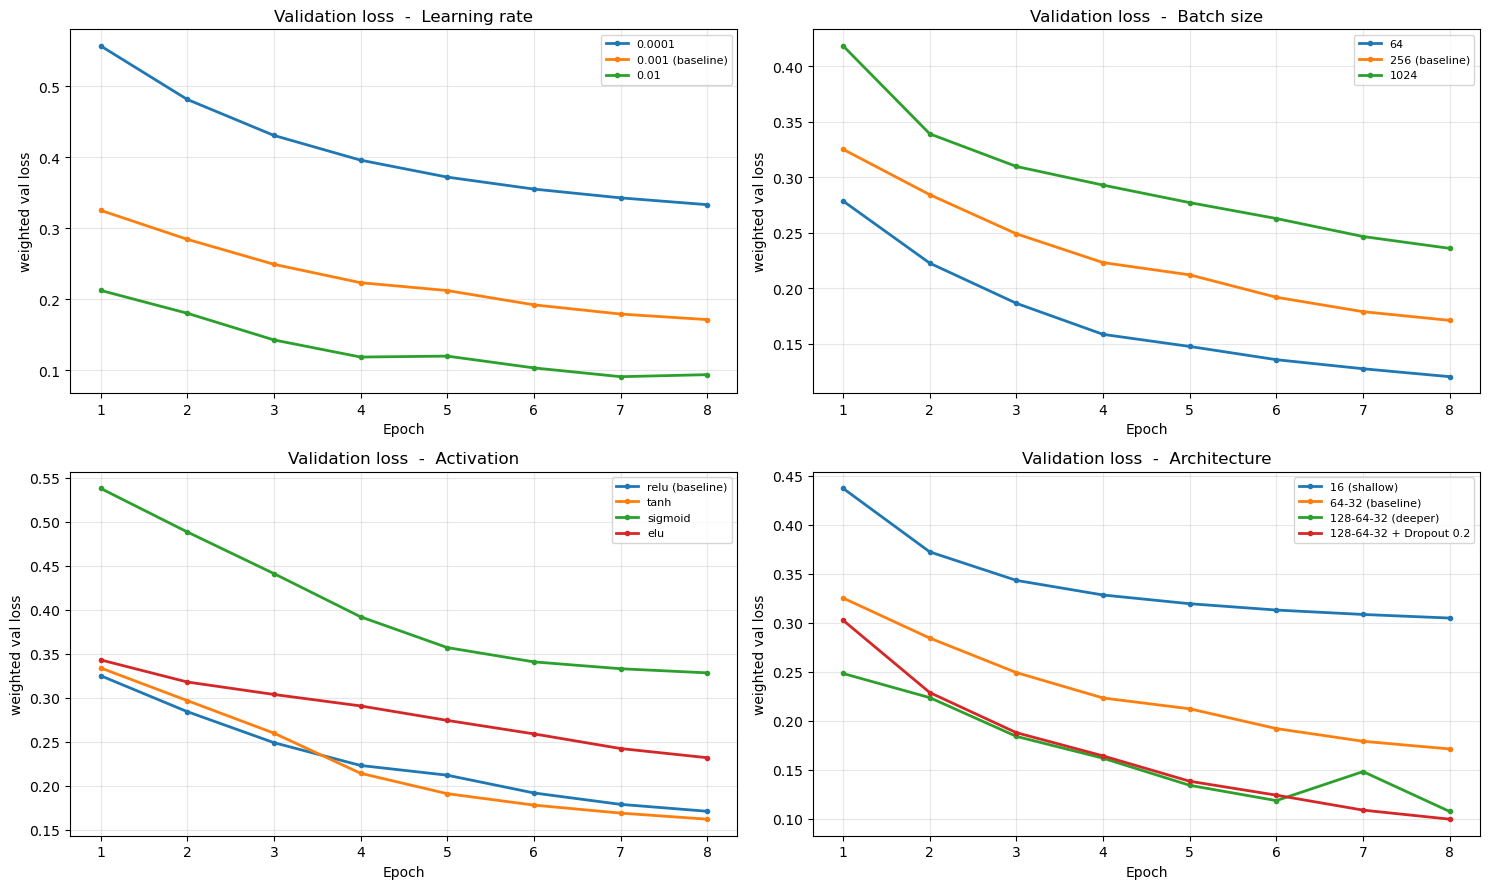

,Group,Setting,Precision,Recall,F1,ROC-AUC,Val loss,Params,Time (s)
0,Learning rate,0.0001,0.3299,0.8479,0.4749,0.9387,0.3331,2817,15.2391
1,Learning rate,0.001 (baseline),0.5466,0.9779,0.7012,0.9825,0.1711,2817,15.1248
2,Learning rate,0.01,0.6561,0.9849,0.7876,0.9926,0.0935,2817,15.0455
3,Batch size,64,0.6179,0.9802,0.7580,0.9881,0.1204,2817,47.2929
4,Batch size,256 (baseline),0.5466,0.9779,0.7012,0.9825,0.1711,2817,15.1248
5,Batch size,1024,0.3077,0.9911,0.4696,0.9673,0.2360,2817,5.7239
6,Activation,relu (baseline),0.5466,0.9779,0.7012,0.9825,0.1711,2817,15.1248
7,Activation,tanh,0.5598,0.9835,0.7135,0.9833,0.1621,2817,14.0199
8,Activation,sigmoid,0.3131,0.8450,0.4570,0.9385,0.3284,2817,14.5309
9,Activation,elu,0.3534,0.9746,0.5187,0.9651,0.2320,2817,14.2833


Best ROC-AUC on validation : Learning rate -> 0.01  (0.9926)
Best F1 on validation      : Learning rate -> 0.01  (0.7876)


In [45]:
# PURPOSE: plot and tabulate the experiment results.
# STATUS : NEW
if RUN_EXPERIMENTS:
    # one subplot per hyper-parameter
    groups = ["Learning rate", "Batch size", "Activation", "Architecture"]
    fig, axes = plt.subplots(2, 2, figsize=(15, 9))
    for ax, g in zip(axes.ravel(), groups):
        for r in results:
            if r["group"] == g:
                ax.plot(range(1, EXP_EPOCHS + 1), r["curve"], marker="o", ms=3, lw=2, label=r["setting"])
        ax.set_title(f"Validation loss  -  {g}"); ax.set_xlabel("Epoch"); ax.set_ylabel("weighted val loss")
        ax.grid(alpha=0.3); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

    # all metrics side by side
    table = exp_df[["group", "setting", "val_precision", "val_recall", "val_f1", "val_auc",
                    "val_loss", "params", "time_s"]].copy()
    table.columns = ["Group", "Setting", "Precision", "Recall", "F1", "ROC-AUC", "Val loss", "Params", "Time (s)"]
    display(table.round(4).reset_index(drop=True))

    # winners by ROC-AUC and by F1
    best = exp_df.loc[exp_df["val_auc"].idxmax()]
    print(f"Best ROC-AUC on validation : {best['group']} -> {best['setting']}  ({best['val_auc']:.4f})")
    best_f1 = exp_df.loc[exp_df["val_f1"].idxmax()]
    print(f"Best F1 on validation      : {best_f1['group']} -> {best_f1['setting']}  ({best_f1['val_f1']:.4f})")

**📖 Reading the experiments**

* **Learning rate** – too small → loss falls very slowly; too large → loss bounces or is worse at the end.
* **Batch size** – small batches reach a low loss in fewer epochs (more updates) but each epoch is slower; huge batches are fast per epoch but need more epochs.
* **Activation** – ReLU / ELU usually learn fastest; Sigmoid in hidden layers is slow because of vanishing gradients.
* **Architecture** – a bigger network is not automatically better; compare it to the baseline, and see whether Dropout helps.

⚠️ Each setting was trained **once** with one random seed, so differences in the third decimal are noise. Only clear gaps (like the slow learning-rate curve) are meaningful. If you change the main `CONFIG` because of this, always report the final result on the **test** set.

### ANN summary

In [46]:
# PURPOSE: one-screen summary of the whole ANN - handy for your report / viva.
# STATUS : NEW
print("=" * 62)
print(" ANN - FINAL SUMMARY")
print("=" * 62)
print(f" Architecture     : {N_FEATURES} -> " + " -> ".join(str(u) for u in CONFIG["hidden_units"]) + " -> 1")
print(f" Activations      : {CONFIG['hidden_activation'].upper()} (hidden), SIGMOID (output)")
print(f" Parameters       : {ann_model.count_params():,}")
print(f" Loss / optimizer : binary cross-entropy (class-weighted) / Adam, lr = {CONFIG['learning_rate']}")
print(f" Batch size       : {CONFIG['batch_size']}   ({steps_per_epoch} updates per epoch)")
print(f" Epochs run       : {len(history.history['loss'])} of max {CONFIG['max_epochs']}   (best epoch {best_epoch})")
print(f" Training time    : {train_time:.1f} s")
print("-" * 62)
print(f" Test accuracy    : {accuracy:.4f}")
print(f" Precision        : {precision:.4f}")
print(f" Recall           : {recall:.4f}    <- attacks detected")
print(f" F1 score         : {f1:.4f}")
print(f" FPR / FNR        : {fpr:.4f} / {fnr:.4f}")
print(f" ROC-AUC / PR-AUC : {roc_auc_ann:.4f} / {pr_auc_ann:.4f}")
print(f" MCC              : {mcc_ann:.4f}")
print("=" * 62)

 ANN - FINAL SUMMARY
 Architecture     : 10 -> 64 -> 32 -> 1
 Activations      : RELU (hidden), SIGMOID (output)
 Parameters       : 2,817
 Loss / optimizer : binary cross-entropy (class-weighted) / Adam, lr = 0.001
 Batch size       : 256   (500 updates per epoch)
 Epochs run       : 30 of max 30   (best epoch 29)
 Training time    : 56.0 s
--------------------------------------------------------------
 Test accuracy    : 0.9625
 Precision        : 0.6398
 Recall           : 0.9928    <- attacks detected
 F1 score         : 0.7781
 FPR / FNR        : 0.0397 / 0.0072
 ROC-AUC / PR-AUC : 0.9933 / 0.9113
 MCC              : 0.7806


#### Take-aways

* The ANN's non-linear layers and **class weights** turn a model that ignores attacks (Logistic Regression) into one that detects almost all of them.
* The price of high recall is a number of **false alarms** (precision < 1) – the decision **threshold** analysis below shows how to trade recall against false alarms.
* Recall, FPR/FNR, PR-AUC and MCC tell the real story; plain accuracy hides the imbalance.
* Forward propagation and backpropagation were verified by hand against Keras/TensorFlow, so the "black box" is fully explained.

### Compare all three models

In [47]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Balanced Logistic Regression",
        "ANN"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_balanced),
        accuracy_score(y_test, y_pred_ann)
    ],
    "Precision": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_balanced),
        precision_score(y_test, y_pred_ann)
    ],
    "Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_balanced),
        recall_score(y_test, y_pred_ann)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_balanced),
        f1_score(y_test, y_pred_ann)
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.940275,0.750951,0.148888,0.248506
1,Balanced Logistic Regression,0.699275,0.168036,0.894459,0.282921
2,ANN,0.962450,0.639786,0.992838,0.778139


### Attach the actual attack type to our test predictions

In [48]:
test_results = pd.DataFrame({
    "Actual_Label": y_test,
    "Predicted_Label": y_pred_ann
}, index=y_test.index)

test_results["Attack_Type"] = df.loc[
    y_test.index, "Attack"
]

test_results.head()

,Actual_Label,Predicted_Label,Attack_Type
17050,0,0,Benign
126030,0,0,Benign
176031,0,0,Benign
53215,1,1,Exploits
199861,0,0,Benign


### Check how many attacks of each type are in the test set


In [49]:
test_results[test_results["Actual_Label"] == 1]["Attack_Type"].value_counts()

Attack_Type
Exploits          924
Fuzzers           704
Reconnaissance    464
DoS               196
Generic           188
Analysis           62
Backdoor           59
Shellcode          49
Worms               7
Name: count, dtype: int64

### Now attack wise detection rate:-

In [50]:
attack_results = test_results[
    test_results["Actual_Label"] == 1
].copy()

attack_results["Correct"] = (
    attack_results["Actual_Label"] ==
    attack_results["Predicted_Label"]
)

attack_recall = (
    attack_results
    .groupby("Attack_Type")["Correct"]
    .agg(["sum", "count"])
)

attack_recall["Recall"] = (
    attack_recall["sum"] /
    attack_recall["count"]
)

attack_recall = attack_recall.sort_values(
    "Recall",
    ascending=False
)

attack_recall

,sum,count,Recall
Attack_Type,,,
Analysis,62,62,1.000000
Shellcode,49,49,1.000000
Worms,7,7,1.000000
Reconnaissance,464,464,1.000000
Fuzzers,703,704,0.998580
Exploits,917,924,0.992424
Backdoor,58,59,0.983051
DoS,191,196,0.974490
Generic,183,188,0.973404


### Threshold analysis

In [51]:
y_pred_ann = (y_prob_ann >= 0.5)

#### Test different thresholds:-

In [52]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.30, 0.40, 0.50, 0.60, 0.70]

for threshold in thresholds:
    predictions = (y_prob_ann >= threshold).astype(int).ravel()

    precision = precision_score(y_test, predictions)
    recall = recall_score(y_test, predictions)
    f1 = f1_score(y_test, predictions)

    tn, fp, fn, tp = confusion_matrix(y_test, predictions).ravel()
    fpr = fp / (fp + tn)

    print(f"\nThreshold: {threshold}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1 Score:  {f1:.4f}")
    print(f"FPR:       {fpr:.4f}")


Threshold: 0.3
Precision: 0.6177
Recall:    0.9940
F1 Score:  0.7619
FPR:       0.0437

Threshold: 0.4
Precision: 0.6293
Recall:    0.9936
F1 Score:  0.7705
FPR:       0.0416

Threshold: 0.5
Precision: 0.6398
Recall:    0.9928
F1 Score:  0.7781
FPR:       0.0397

Threshold: 0.6
Precision: 0.6464
Recall:    0.9902
F1 Score:  0.7822
FPR:       0.0385

Threshold: 0.7
Precision: 0.6514
Recall:    0.9834
F1 Score:  0.7837
FPR:       0.0374


In [53]:
final_threshold = 0.70

y_pred_final = (y_prob_ann >= final_threshold).astype(int).ravel()

print("Final ANN Classification Report:")
print(classification_report(y_test, y_pred_final))

print("Final Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_final))

Final ANN Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.96      0.98     37347
           1       0.65      0.98      0.78      2653

    accuracy                           0.96     40000
   macro avg       0.83      0.97      0.88     40000
weighted avg       0.98      0.96      0.97     40000

Final Confusion Matrix:
[[35951  1396]
 [   44  2609]]


In [54]:
tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_pred_final
).ravel()

final_accuracy = accuracy_score(y_test, y_pred_final)
final_precision = precision_score(y_test, y_pred_final)
final_recall = recall_score(y_test, y_pred_final)
final_f1 = f1_score(y_test, y_pred_final)

final_fpr = fp / (fp + tn)
final_fnr = fn / (fn + tp)

print("Accuracy :", final_accuracy)
print("Precision:", final_precision)
print("Recall   :", final_recall)
print("F1 Score :", final_f1)
print("FPR      :", final_fpr)
print("FNR      :", final_fnr)

Accuracy : 0.964
Precision: 0.6514357053682897
Recall   : 0.9834150018846589
F1 Score : 0.7837188344848303
FPR      : 0.037379173695343666
FNR      : 0.016584998115341122


### Final Model Comparison

In [55]:
final_threshold = 0.70

y_pred_final = (y_prob_ann >= final_threshold).astype(int).ravel()

tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_pred_final
).ravel()

final_accuracy = accuracy_score(y_test, y_pred_final)
final_precision = precision_score(y_test, y_pred_final)
final_recall = recall_score(y_test, y_pred_final)
final_f1 = f1_score(y_test, y_pred_final)

final_fpr = fp / (fp + tn)
final_fnr = fn / (fn + tp)

print("Final ANN Results")
print("-----------------")
print("Accuracy :", round(final_accuracy, 4))
print("Precision:", round(final_precision, 4))
print("Recall   :", round(final_recall, 4))
print("F1 Score :", round(final_f1, 4))
print("FPR      :", round(final_fpr, 4))
print("FNR      :", round(final_fnr, 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_final))

Final ANN Results
-----------------
Accuracy : 0.964
Precision: 0.6514
Recall   : 0.9834
F1 Score : 0.7837
FPR      : 0.0374
FNR      : 0.0166

Confusion Matrix:
[[35951  1396]
 [   44  2609]]


In [56]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Balanced Logistic Regression",
        "ANN",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_balanced),
        accuracy_score(y_test, y_pred_ann),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Precision": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_balanced),
        precision_score(y_test, y_pred_ann),
        precision_score(y_test, y_pred_rf)
    ],
    "Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_balanced),
        recall_score(y_test, y_pred_ann),
        recall_score(y_test, y_pred_rf)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_balanced),
        f1_score(y_test, y_pred_ann),
        f1_score(y_test, y_pred_rf)
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.940275,0.750951,0.148888,0.248506
1,Balanced Logistic Regression,0.699275,0.168036,0.894459,0.282921
2,ANN,0.962450,0.639786,0.992838,0.778139
3,Random Forest,0.983950,0.836851,0.941576,0.886130


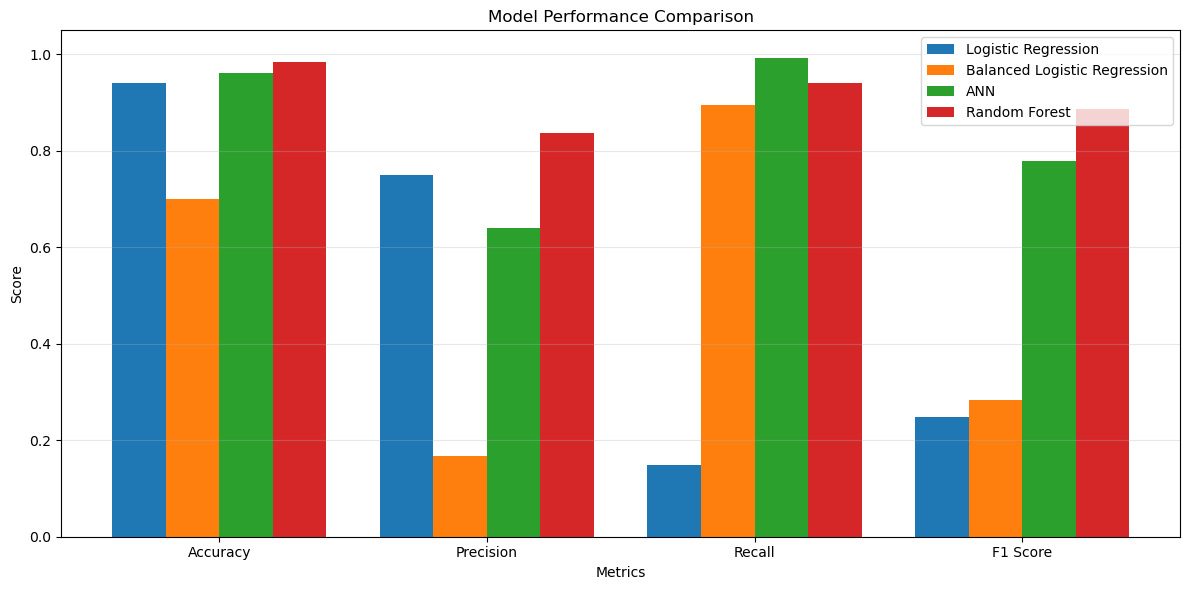

In [57]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

x = np.arange(len(metrics))
width = 0.2

plt.figure(figsize=(12, 6))

for i, (_, row) in enumerate(comparison.iterrows()):
    plt.bar(
        x + (i - 1.5) * width,
        [
            row["Accuracy"],
            row["Precision"],
            row["Recall"],
            row["F1 Score"]
        ],
        width,
        label=row["Model"]
    )

plt.xlabel("Metrics")
plt.ylabel("Score")
plt.title("Model Performance Comparison")
plt.xticks(x, metrics)
plt.ylim(0, 1.05)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [58]:
import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

                      Feature  Importance
5                   OUT_BYTES    0.205618
7                    OUT_PKTS    0.163926
4                    IN_BYTES    0.157849
9  FLOW_DURATION_MILLISECONDS    0.124572
1                 L4_DST_PORT    0.115878
6                     IN_PKTS    0.085945
8                   TCP_FLAGS    0.070038
3                    L7_PROTO    0.036989
0                 L4_SRC_PORT    0.021897
2                    PROTOCOL    0.017288


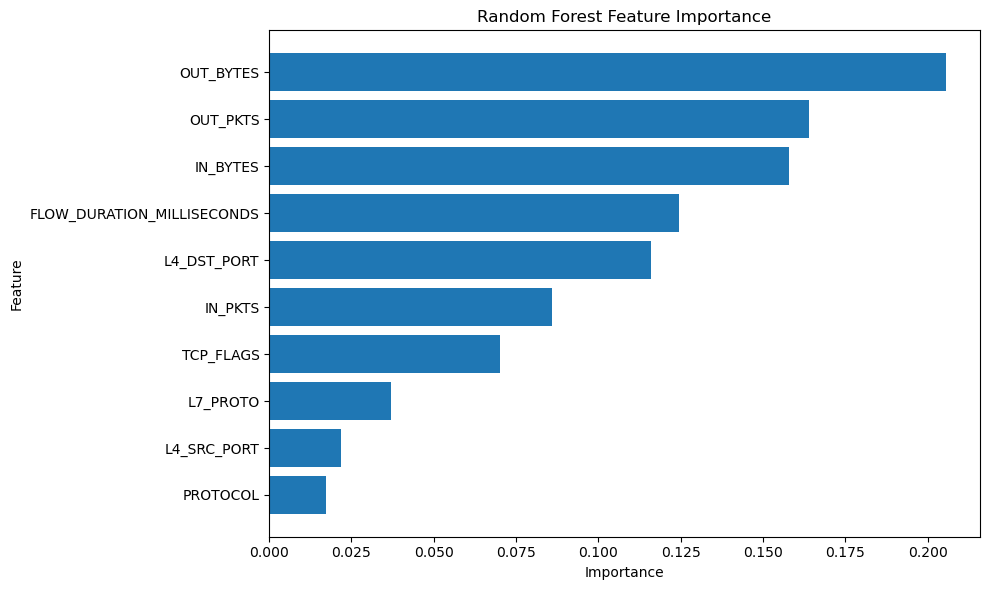

In [59]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### Saving all the models

In [60]:
import os
import joblib

model_dir = r"E:\GitHub\Network-Intrusion-Detection-System\models"
os.makedirs(model_dir, exist_ok=True)

# Logistic Regression
joblib.dump(
    lr_model,
    os.path.join(model_dir, "logistic_regression.pkl")
)

# Balanced Logistic Regression
joblib.dump(
    lr_balanced,
    os.path.join(model_dir, "balanced_logistic_regression.pkl")
)

# ANN
ann_model.save(
    os.path.join(model_dir, "ann_model.keras")
)

print("All models saved successfully!")
print("\nSaved models:")
print("- logistic_regression.pkl")
print("- balanced_logistic_regression.pkl")
print("- ann_model.keras")
print("- nids_random_forest.pkl")

All models saved successfully!

Saved models:
- logistic_regression.pkl
- balanced_logistic_regression.pkl
- ann_model.keras
- nids_random_forest.pkl


In [61]:
import os
import joblib

model_dir = r"E:\GitHub\Network-Intrusion-Detection-System\models"

os.makedirs(model_dir, exist_ok=True)

model_path = os.path.join(model_dir, "nids_random_forest.pkl")

joblib.dump(rf_model, model_path)

print("Random Forest model saved successfully.")
print("Saved at:", model_path)

Random Forest model saved successfully.
Saved at: E:\GitHub\Network-Intrusion-Detection-System\models\nids_random_forest.pkl


In [62]:
import joblib
import os

model_dir = r"E:\GitHub\Network-Intrusion-Detection-System\models"
os.makedirs(model_dir, exist_ok=True)

scaler_path = os.path.join(model_dir, "standard_scaler.pkl")

joblib.dump(scaler, scaler_path)

print("Scaler saved successfully!")
print("Saved at:", scaler_path)

Scaler saved successfully!
Saved at: E:\GitHub\Network-Intrusion-Detection-System\models\standard_scaler.pkl


In [63]:
import os, json, math, time, zipfile, datetime
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,
    roc_curve, roc_auc_score, precision_recall_curve, average_precision_score,
    matthews_corrcoef, balanced_accuracy_score, ConfusionMatrixDisplay,
)
 
# ----------------------------- settings you may change -----------------------------
EXPORT_DIR   = "nids_export"      # folder created next to your notebook
SAMPLE_BENIGN, SAMPLE_ATTACK = 2000, 1000   # rows in the demo CSV (attacks over-represented on purpose)
RF_MAX_MB    = 25                 # a Random Forest file bigger than this is NOT put in the zip (see message at the end)
CURVE_POINTS = 300                # max points per ROC / PR curve (keeps the JSON small)
SEED         = 42
# -----------------------------------------------------------------------------------
 
# ---------- 0. make sure everything we need exists ----------
required = ["df", "X_test", "y_test", "X_test_scaled", "scaler",
            "lr_model", "lr_balanced", "rf_model", "ann_model", "history", "y_prob_ann"]
missing = [v for v in required if v not in globals()]
if missing:
    raise NameError(f"Run the earlier cells first. Missing variables: {missing}")
 
t_start = time.time()
os.makedirs(os.path.join(EXPORT_DIR, "png"), exist_ok=True)
os.makedirs(os.path.join(EXPORT_DIR, "models"), exist_ok=True)
 
FEATURES = list(X_test.columns)
y_true   = np.asarray(y_test).astype(int)
 
# ---------- helper functions ----------
def clean(o):
    """Turn numpy / NaN values into plain JSON-safe Python values."""
    if isinstance(o, dict):                 return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):        return [clean(v) for v in o]
    if isinstance(o, np.ndarray):           return clean(o.tolist())
    if isinstance(o, np.bool_):             return bool(o)
    if isinstance(o, np.integer):           return int(o)
    if isinstance(o, (np.floating, float)):
        v = float(o)
        return None if (math.isnan(v) or math.isinf(v)) else round(v, 6)
    return o
 
def downsample(x, y, n=CURVE_POINTS):
    x, y = np.asarray(x), np.asarray(y)
    if len(x) <= n:
        return x, y
    idx = np.unique(np.linspace(0, len(x) - 1, n).astype(int))
    return x[idx], y[idx]
 
def full_metrics(prob, thr=0.5):
    pred = (prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "threshold": thr,
        "accuracy": accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "f1": f1_score(y_true, pred, zero_division=0),
        "specificity": tn / (tn + fp),
        "fpr": fp / (fp + tn),
        "fnr": fn / (fn + tp),
        "balanced_accuracy": balanced_accuracy_score(y_true, pred),
        "mcc": matthews_corrcoef(y_true, pred),
        "roc_auc": roc_auc_score(y_true, prob),
        "pr_auc": average_precision_score(y_true, prob),
        "tn": tn, "fp": fp, "fn": fn, "tp": tp,
        "flagged": int(pred.sum()),
    }
 
def save_png(fig, name):
    fig.savefig(os.path.join(EXPORT_DIR, "png", name), dpi=150, bbox_inches="tight")
    plt.close(fig)
 
# ---------- 1. probabilities of every model on the SAME test set ----------
p_lr  = lr_model.predict_proba(X_test_scaled)[:, 1]          # LR models were trained on SCALED data
p_lrb = lr_balanced.predict_proba(X_test_scaled)[:, 1]
p_ann = np.asarray(y_prob_ann).ravel()                       # ANN probabilities from the ANN section
p_rf  = rf_model.predict_proba(X_test)[:, 1]                 # Random Forest was trained on UNSCALED data
 
MODELS = {                                                   # key -> (display name, probabilities)
    "logistic_regression":          ("Logistic Regression",          p_lr),
    "logistic_regression_balanced": ("Balanced Logistic Regression", p_lrb),
    "ann":                          ("ANN",                          p_ann),
    "random_forest":                ("Random Forest",                p_rf),
}
COLORS = {"logistic_regression": "#9E9E9E", "logistic_regression_balanced": "#4C9BE8",
          "ann": "#E8514C", "random_forest": "#2E9E5B"}
tuned_thr = float(globals().get("final_threshold", 0.70))    # your tuned ANN threshold (0.70 in your notebook)
print(f"[1/8] probabilities collected for {len(MODELS)} models on {len(y_true):,} test flows")
 
# ---------- 2. metrics at the default threshold 0.5 (+ the tuned ANN) ----------
models_out = {}
for key, (name, prob) in MODELS.items():
    m = full_metrics(prob, 0.5)
    models_out[key] = {"name": name, "metrics": m,
                       "confusion_matrix": [[m["tn"], m["fp"]], [m["fn"], m["tp"]]]}
m = full_metrics(p_ann, tuned_thr)
models_out["ann_tuned"] = {"name": f"ANN (threshold {tuned_thr:.2f})", "metrics": m,
                           "confusion_matrix": [[m["tn"], m["fp"]], [m["fn"], m["tp"]]]}
print("[2/8] metrics computed")
 
# ---------- 3. curves: ROC, Precision-Recall, threshold sweep, probability histogram ----------
roc_out, pr_out, sweep_out = {}, {}, {}
thresholds = np.round(np.arange(0.05, 0.951, 0.05), 2)
for key, (name, prob) in MODELS.items():
    fpr_c, tpr_c, _ = roc_curve(y_true, prob)
    fpr_c, tpr_c = downsample(fpr_c, tpr_c)
    roc_out[key] = {"name": name, "fpr": fpr_c, "tpr": tpr_c, "auc": roc_auc_score(y_true, prob)}
 
    pr_c, rc_c, _ = precision_recall_curve(y_true, prob)
    rc_c, pr_c = downsample(rc_c, pr_c)
    pr_out[key] = {"name": name, "recall": rc_c, "precision": pr_c, "ap": average_precision_score(y_true, prob)}
 
    sweep_out[key] = []
    for thr in thresholds:
        mm = full_metrics(prob, float(thr))
        sweep_out[key].append({k: mm[k] for k in
                               ["threshold", "precision", "recall", "f1", "fpr", "fnr", "accuracy", "tp", "fp", "tn", "fn", "flagged"]})
 
bins = np.linspace(0, 1, 41)
prob_hist = {"bins": bins}
for key in ["ann", "random_forest"]:
    prob = MODELS[key][1]
    prob_hist[key] = {"benign": np.histogram(prob[y_true == 0], bins=bins)[0],
                      "attack": np.histogram(prob[y_true == 1], bins=bins)[0]}
print("[3/8] ROC / PR / threshold sweep / probability histograms done")
 
# ---------- 4. ANN training history ----------
hist = {k: [float(v) for v in vals] for k, vals in history.history.items()}
epochs_run = len(hist["loss"])
best_epoch = int(np.argmin(hist["val_loss"])) + 1
print(f"[4/8] ANN training history: {epochs_run} epochs, best epoch {best_epoch}")
 
# ---------- 5. ANN details: architecture, weights, importance, forward-pass example ----------
layers_info = []
for layer in ann_model.layers:
    if layer.get_weights():
        W, b = layer.get_weights()
        layers_info.append({"name": layer.name, "neurons": int(W.shape[1]), "inputs": int(W.shape[0]),
                            "activation": layer.activation.__name__, "parameters": int(W.size + b.size)})
architecture = {"input_features": FEATURES, "layers": layers_info,
                "total_parameters": int(ann_model.count_params())}
 
# permutation importance of the ANN (drop in ROC-AUC when one feature is shuffled)
rng = np.random.default_rng(SEED)
base_auc = roc_auc_score(y_true, p_ann)
perm_drop = []
for j in range(len(FEATURES)):
    drops = []
    for _ in range(3):
        Xp = np.array(X_test_scaled, copy=True)
        Xp[:, j] = rng.permutation(Xp[:, j])
        drops.append(base_auc - roc_auc_score(y_true, ann_model.predict(Xp, batch_size=4096, verbose=0).ravel()))
    perm_drop.append(float(np.mean(drops)))
perm_pos = np.clip(perm_drop, 0, None)
feature_importance = {
    "features": FEATURES,
    "ann_auc_drop": perm_drop,
    "ann_normalised": (perm_pos / perm_pos.sum()) if perm_pos.sum() > 0 else perm_pos,
    "random_forest": rf_model.feature_importances_,
}
 
# hand-computed forward pass of ONE real attack flow through the TRAINED ANN (for the animated explainer)
internals = {}
try:
    W1, b1, W2, b2, W3, b3 = ann_model.get_weights()          # works for the 2-hidden-layer ANN of your notebook
    i_att = int(np.where(y_true == 1)[0][0])
    x0 = np.asarray(X_test_scaled[i_att:i_att + 1], dtype="float32")
    z1 = x0 @ W1 + b1;  a1 = np.maximum(0, z1)
    z2 = a1 @ W2 + b2;  a2 = np.maximum(0, z2)
    z3 = a2 @ W3 + b3;  y_hat = 1 / (1 + np.exp(-z3))
    internals = {
        "first_layer_weights": W1,                            # shape: features x neurons (for the heat-map)
        "forward_demo": {
            "flow_raw": X_test.iloc[i_att].to_dict(), "flow_scaled": x0[0],
            "z1": z1[0], "a1": a1[0], "z2": z2[0], "a2": a2[0], "z3": float(z3[0, 0]), "p_attack": float(y_hat[0, 0]),
            "keras_p_attack": float(p_ann[i_att]),
        },
    }
except Exception as e:
    print("   (skipped forward-pass example:", e, ")")
print("[5/8] ANN architecture, feature importance and forward-pass example done")
 
# ---------- 6. recall per attack type for every model ----------
attack_type = df.loc[y_test.index, "Attack"].values
attack_recall = {}
for key, (name, prob) in MODELS.items():
    pred = (prob >= 0.5).astype(int)
    res = {}
    for at in sorted(set(attack_type) - {"Benign"}):
        mask = attack_type == at
        res[at] = {"count": int(mask.sum()), "detected": int(pred[mask].sum()),
                   "recall": float(pred[mask].mean())}
    attack_recall[key] = res
print("[6/8] attack-type recall done")
 
# ---------- 7. dataset summary ----------
class_counts  = df["Label"].value_counts().sort_index()
attack_counts = df["Attack"].value_counts()
dataset = {
    "name": "NF-UNSW-NB15 (NetFlow)",
    "rows_used": int(len(df)),
    "features": FEATURES,
    "label_counts": {"benign": int(class_counts.get(0, 0)), "attack": int(class_counts.get(1, 0))},
    "attack_type_counts": attack_counts.to_dict(),
    "test_rows": int(len(y_true)),
    "test_label_counts": {"benign": int((y_true == 0).sum()), "attack": int((y_true == 1).sum())},
}
meta = {
    "created": datetime.datetime.now().isoformat(timespec="seconds"),
    "default_threshold": 0.5, "tuned_ann_threshold": tuned_thr, "random_seed": SEED,
}
if "class_weight_dict" in globals():
    meta["class_weights"] = {str(k): float(v) for k, v in class_weight_dict.items()}
if "CONFIG" in globals():
    meta["ann_config"] = {k: (list(v) if isinstance(v, tuple) else v) for k, v in CONFIG.items()}
try:
    import tensorflow as tf; meta["tensorflow"] = tf.__version__
except Exception:
    pass
 
training_summary = {"epochs_run": epochs_run, "best_epoch": best_epoch,
                    "final_train_loss": hist["loss"][-1], "final_val_loss": hist["val_loss"][-1]}
 
metrics_json = {"meta": meta, "dataset": dataset, "architecture": architecture,
                "training_summary": training_summary, "models": models_out,
                "attack_type_recall": attack_recall, "feature_importance": feature_importance,
                "ann_internals": internals}
curves_json = {"roc": roc_out, "pr": pr_out, "training_history": hist,
               "threshold_sweep": sweep_out, "probability_histogram": prob_hist}
 
with open(os.path.join(EXPORT_DIR, "metrics.json"), "w", encoding="utf-8") as f:
    json.dump(clean(metrics_json), f, indent=1)
with open(os.path.join(EXPORT_DIR, "curves.json"), "w", encoding="utf-8") as f:
    json.dump(clean(curves_json), f)
print("[7/8] metrics.json and curves.json written")
 
# ---------- 8a. PNG backups of the main charts ----------
keys4 = list(MODELS.keys())
names4 = [MODELS[k][0] for k in keys4]
 
# 1) class balance
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].bar(["Benign", "Attack"], [dataset["label_counts"]["benign"], dataset["label_counts"]["attack"]], color=["#4C9BE8", "#E8514C"])
ax[0].set_title("Benign vs attack flows"); ax[0].set_ylabel("flows")
at_counts = attack_counts.drop("Benign", errors="ignore")
ax[1].barh(at_counts.index, at_counts.values, color="#E8514C"); ax[1].invert_yaxis(); ax[1].set_title("Attack types")
for a in ax: a.grid(alpha=0.3)
save_png(fig, "01_class_balance.png")
 
# 2) grouped comparison
metric_keys = [("accuracy", "Accuracy"), ("precision", "Precision"), ("recall", "Recall"), ("f1", "F1 score")]
fig, ax = plt.subplots(figsize=(12, 6)); w = 0.2; x = np.arange(len(metric_keys))
for i, k in enumerate(keys4):
    vals = [models_out[k]["metrics"][mk] for mk, _ in metric_keys]
    bars = ax.bar(x + (i - 1.5) * w, vals, w, label=MODELS[k][0], color=COLORS[k])
    for bar, v in zip(bars, vals): ax.text(bar.get_x() + bar.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels([n for _, n in metric_keys]); ax.set_ylim(0, 1.12)
ax.set_title("Model comparison on the test set (threshold 0.5)"); ax.legend(); ax.grid(axis="y", alpha=0.3)
save_png(fig, "02_model_comparison.png")
 
# 3) recall headline
fig, ax = plt.subplots(figsize=(9, 5))
vals = [models_out[k]["metrics"]["recall"] for k in keys4]
bars = ax.bar(names4, vals, color=[COLORS[k] for k in keys4])
for bar, v in zip(bars, vals): ax.text(bar.get_x() + bar.get_width() / 2, v + 0.01, f"{v:.1%}", ha="center", fontweight="bold")
ax.set_ylim(0, 1.1); ax.set_ylabel("Recall = share of real attacks detected"); ax.set_title("How many attacks does each model catch?")
plt.setp(ax.get_xticklabels(), rotation=12); ax.grid(axis="y", alpha=0.3)
save_png(fig, "03_attack_recall.png")
 
# 4) confusion matrices side by side
fig, axes = plt.subplots(1, 4, figsize=(20, 4.8))
for ax, k in zip(axes, keys4):
    ConfusionMatrixDisplay(np.array(models_out[k]["confusion_matrix"]), display_labels=["Benign", "Attack"]).plot(
        ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(f"{MODELS[k][0]}\nrecall {models_out[k]['metrics']['recall']:.1%}"); ax.grid(False)
save_png(fig, "04_confusion_matrices.png")
 
# 5) ROC overlay and 6) PR overlay
fig, ax = plt.subplots(figsize=(7.5, 6))
for k in keys4: ax.plot(roc_out[k]["fpr"], roc_out[k]["tpr"], lw=2, color=COLORS[k], label=f"{MODELS[k][0]} (AUC {roc_out[k]['auc']:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("ROC curves"); ax.legend(loc="lower right"); ax.grid(alpha=0.3)
save_png(fig, "05_roc_overlay.png")
 
fig, ax = plt.subplots(figsize=(7.5, 6))
for k in keys4: ax.plot(pr_out[k]["recall"], pr_out[k]["precision"], lw=2, color=COLORS[k], label=f"{MODELS[k][0]} (AP {pr_out[k]['ap']:.3f})")
ax.axhline(y_true.mean(), color="k", ls="--", lw=1, label="random"); ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.set_title("Precision-Recall curves"); ax.legend(loc="lower left"); ax.grid(alpha=0.3)
save_png(fig, "06_pr_overlay.png")
 
# 7) ANN training curves
ep = np.arange(1, epochs_run + 1)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, (k, title) in zip(axes, [("loss", "Loss"), ("accuracy", "Accuracy"), ("recall", "Recall")]):
    ax.plot(ep, hist[k], lw=2, label="Training"); ax.plot(ep, hist["val_" + k], lw=2, label="Validation")
    ax.axvline(best_epoch, color="gray", ls="--", lw=1); ax.set_title(f"ANN {title}"); ax.set_xlabel("Epoch"); ax.legend(); ax.grid(alpha=0.3)
save_png(fig, "07_ann_training_curves.png")
 
# 8) threshold sweep (ANN)
sw = pd.DataFrame(sweep_out["ann"])
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(sw["threshold"], sw["precision"], lw=2, marker="o", label="Precision")
ax.plot(sw["threshold"], sw["recall"], lw=2, marker="o", label="Recall")
ax.plot(sw["threshold"], sw["fpr"], lw=2, marker="o", label="False positive rate")
ax.axvline(0.5, color="gray", ls="--", lw=1); ax.axvline(tuned_thr, color="red", ls=":", lw=1.5, label=f"tuned = {tuned_thr:.2f}")
ax.set_xlabel("Decision threshold"); ax.set_title("ANN: sensitivity vs false alarms"); ax.legend(); ax.grid(alpha=0.3)
save_png(fig, "08_ann_threshold_sweep.png")
 
# 9) attack-type recall (ANN vs Random Forest)
ats = list(attack_recall["ann"].keys()); xx = np.arange(len(ats))
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.bar(xx - 0.2, [attack_recall["ann"][a]["recall"] for a in ats], 0.4, label="ANN", color=COLORS["ann"])
ax.bar(xx + 0.2, [attack_recall["random_forest"][a]["recall"] for a in ats], 0.4, label="Random Forest", color=COLORS["random_forest"])
ax.set_xticks(xx); ax.set_xticklabels(ats, rotation=30, ha="right"); ax.set_ylim(0, 1.1); ax.set_ylabel("Recall")
ax.set_title("Detection rate per attack type"); ax.legend(); ax.grid(axis="y", alpha=0.3)
save_png(fig, "09_attack_type_recall.png")
 
# 10) feature importance
order = np.argsort(feature_importance["ann_normalised"])[::-1]
fig, ax = plt.subplots(figsize=(10, 5.5)); yy = np.arange(len(FEATURES))
ax.barh(yy - 0.2, np.array(feature_importance["ann_normalised"])[order], 0.4, label="ANN (permutation)", color=COLORS["ann"])
ax.barh(yy + 0.2, np.array(feature_importance["random_forest"])[order], 0.4, label="Random Forest", color=COLORS["random_forest"])
ax.set_yticks(yy); ax.set_yticklabels(np.array(FEATURES)[order]); ax.invert_yaxis()
ax.set_title("Which features matter?"); ax.legend(); ax.grid(alpha=0.3)
save_png(fig, "10_feature_importance.png")
 
# 11) model battle: missed attacks and false alarms
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, (mk, title) in zip(axes, [("fn", "Attacks MISSED (lower is better)"), ("fp", "False ALARMS (lower is better)")]):
    vals = [models_out[k]["metrics"][mk] for k in keys4]
    bars = ax.bar(names4, vals, color=[COLORS[k] for k in keys4])
    for bar, v in zip(bars, vals): ax.text(bar.get_x() + bar.get_width() / 2, v, f"{int(v):,}", ha="center", va="bottom", fontweight="bold")
    ax.set_title(title); plt.setp(ax.get_xticklabels(), rotation=12); ax.grid(axis="y", alpha=0.3)
save_png(fig, "11_missed_vs_false_alarms.png")
print("[8/8] PNG charts saved")
 
# ---------- 9. demo CSV + template (flows from the TEST set, never used for training) ----------
rng = np.random.default_rng(SEED)
ben_idx = np.where(y_true == 0)[0]; att_idx = np.where(y_true == 1)[0]
pick = np.concatenate([rng.choice(ben_idx, min(SAMPLE_BENIGN, len(ben_idx)), replace=False),
                       rng.choice(att_idx, min(SAMPLE_ATTACK, len(att_idx)), replace=False)])
rng.shuffle(pick)
sample_index = y_test.index[pick]
id_cols = [c for c in ["IPV4_SRC_ADDR", "IPV4_DST_ADDR"] if c in df.columns]
sample = df.loc[sample_index, id_cols + FEATURES + ["Label", "Attack"]].reset_index(drop=True)
sample.to_csv(os.path.join(EXPORT_DIR, "sample_flows.csv"), index=False)
sample[FEATURES].head(5).to_csv(os.path.join(EXPORT_DIR, "sample_template.csv"), index=False)
 
# ---------- 10. models + scaler (so the web app can load them) ----------
mdir = os.path.join(EXPORT_DIR, "models")
ann_model.save(os.path.join(mdir, "ann_model.keras"))
joblib.dump(scaler,      os.path.join(mdir, "standard_scaler.pkl"))
joblib.dump(lr_model,    os.path.join(mdir, "logistic_regression.pkl"))
joblib.dump(lr_balanced, os.path.join(mdir, "balanced_logistic_regression.pkl"))
rf_path = os.path.join(mdir, "nids_random_forest.pkl")
joblib.dump(rf_model, rf_path, compress=3)
rf_mb = os.path.getsize(rf_path) / 1024 ** 2
 
# ---------- 11. zip everything for ONE easy upload ----------
zip_path = os.path.join(EXPORT_DIR, "nids_export.zip")
rf_in_zip = rf_mb <= RF_MAX_MB
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for root, _, files in os.walk(EXPORT_DIR):
        for fn in files:
            full = os.path.join(root, fn)
            if full == zip_path or (full == rf_path and not rf_in_zip):
                continue
            z.write(full, os.path.relpath(full, EXPORT_DIR))
 
# ---------- 12. summary ----------
print("\n" + "=" * 70)
print(f" EXPORT FINISHED in {time.time() - t_start:.0f}s  ->  {os.path.abspath(EXPORT_DIR)}")
print("=" * 70)
summary = pd.DataFrame({
    "Model": [models_out[k]["name"] for k in models_out],
    "Accuracy": [models_out[k]["metrics"]["accuracy"] for k in models_out],
    "Precision": [models_out[k]["metrics"]["precision"] for k in models_out],
    "Recall": [models_out[k]["metrics"]["recall"] for k in models_out],
    "F1": [models_out[k]["metrics"]["f1"] for k in models_out],
    "FPR": [models_out[k]["metrics"]["fpr"] for k in models_out],
    "Missed attacks": [models_out[k]["metrics"]["fn"] for k in models_out],
}).round(4)
display(summary)
 
print("\nFiles:")
for root, _, files in os.walk(EXPORT_DIR):
    for fn in sorted(files):
        full = os.path.join(root, fn)
        print(f"  {os.path.relpath(full, EXPORT_DIR):<45}{os.path.getsize(full) / 1024:>10,.0f} KB")
 
print("\n>>> UPLOAD THIS FILE:", os.path.abspath(zip_path))
if not rf_in_zip:
    print(f">>> The Random Forest file is {rf_mb:.0f} MB (limit {RF_MAX_MB} MB) so it was LEFT OUT of the zip.")
    print("    That is fine - I can rebuild a lighter forest inside the app. Just tell me.")

[1/8] probabilities collected for 4 models on 40,000 test flows
[2/8] metrics computed
[3/8] ROC / PR / threshold sweep / probability histograms done
[4/8] ANN training history: 30 epochs, best epoch 29
[5/8] ANN architecture, feature importance and forward-pass example done
[6/8] attack-type recall done
[7/8] metrics.json and curves.json written
[8/8] PNG charts saved

 EXPORT FINISHED in 12s  ->  E:\Udemy_ML\NIDS_Project.ipynb\nids_export


,Model,Accuracy,Precision,Recall,F1,FPR,Missed attacks
0,Logistic Regression,0.9403,0.7510,0.1489,0.2485,0.0035,2258
1,Balanced Logistic Regression,0.6993,0.1680,0.8945,0.2829,0.3146,280
2,ANN,0.9624,0.6398,0.9928,0.7781,0.0397,19
3,Random Forest,0.9840,0.8369,0.9416,0.8861,0.0130,155
4,ANN (threshold 0.70),0.9640,0.6514,0.9834,0.7837,0.0374,44



Files:
  curves.json                                          66 KB
  metrics.json                                         22 KB
  nids_export.zip                                   5,662 KB
  sample_flows.csv                                    217 KB
  sample_template.csv                                   0 KB
  models\ann_model.keras                               59 KB
  models\balanced_logistic_regression.pkl               1 KB
  models\logistic_regression.pkl                        1 KB
  models\nids_random_forest.pkl                     4,943 KB
  models\standard_scaler.pkl                            1 KB
  png\01_class_balance.png                             56 KB
  png\02_model_comparison.png                          57 KB
  png\03_attack_recall.png                             65 KB
  png\04_confusion_matrices.png                        68 KB
  png\05_roc_overlay.png                               86 KB
  png\06_pr_overlay.png                                88 KB
  png\07_ann_tra

1) Threshold-free comparison (same 40,000 test flows)



,Measure,ANN v1,Random Forest,ANN v1 - RF
0,ROC-AUC,0.9933,0.9979,-0.0046
1,PR-AUC (average precision),0.9113,0.9721,-0.0608
2,Recall at FPR = 0.5%,0.6521,0.8794,-0.2273
3,Recall at FPR = 1.0%,0.8364,0.9175,-0.0810
4,Recall at FPR = 2.0%,0.9137,0.9759,-0.0622
5,Recall at FPR = 5.0%,0.9947,1.0000,-0.0053
6,Precision at recall = 90%,0.7918,0.8964,-0.1046
7,Precision at recall = 95%,0.7056,0.8261,-0.1206
8,Precision at recall = 98%,0.6770,0.7659,-0.0889
9,Precision at recall = 99%,0.6466,0.7489,-0.1024



2) Verdict
   PR-AUC gap (ANN - RF)              : -0.0608
   False-alarm rate when both catch 94% of attacks:  ANN 2.63%  vs  RF 1.29%
   -> The ANN genuinely RANKS flows worse than the Random Forest even without a threshold.
      Something about its inputs or training limits it -> Step 2 (input representation) is the priority.

3) ANN v1 false alarms at threshold 0.5: 1,483
   with P(attack) >= 0.6 :  96.9% of them
   with P(attack) >= 0.8 :  71.8% of them
   with P(attack) >= 0.9 :  27.4% of them
   with P(attack) >= 0.99:   3.9% of them
   (high shares = confident mistakes the threshold cannot fix; low shares = borderline cases)

4) Training: 30 epochs run, best epoch 29
   val_loss over the last 5 epochs: 0.0958  0.0943  0.0979  0.0915  0.0933
   -> still improving at the end: a longer budget is justified (next cell).


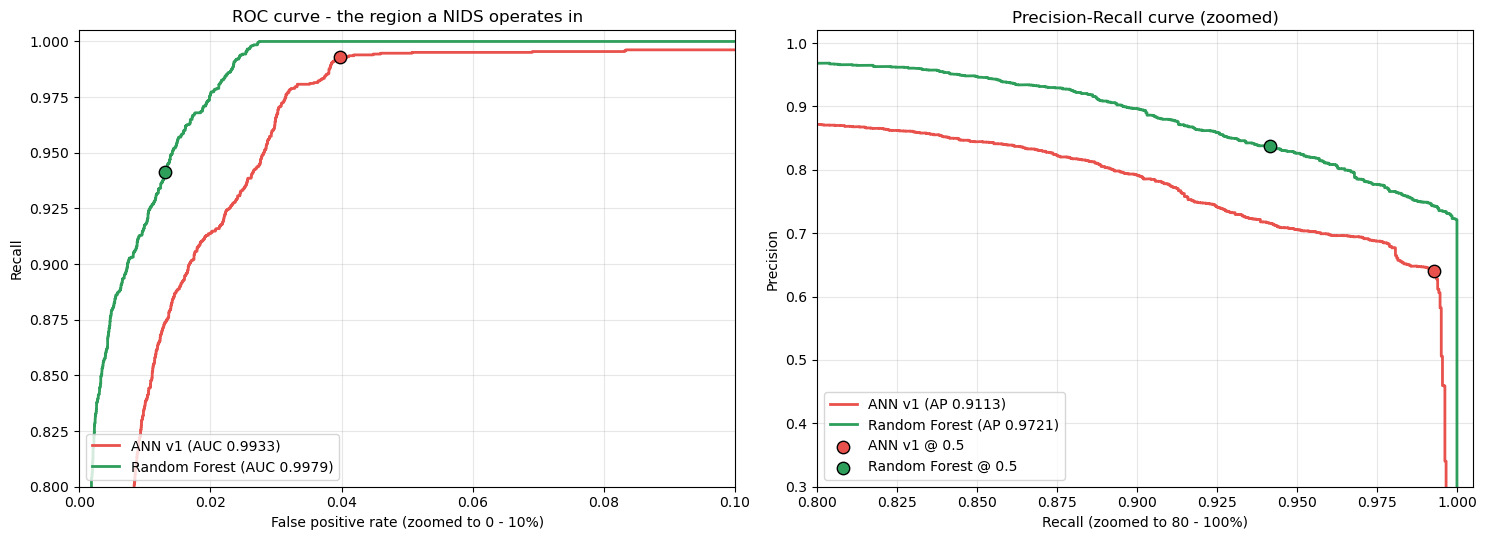

In [64]:
# =====================================================================
# ANN v2 - STEP 1 / CELL 1 : DIAGNOSIS (no training in this cell)
# PURPOSE: is ANN v1 worse at RANKING flows, or only at its threshold?
# STATUS : NEW. Reads ann_model's saved probabilities (y_prob_ann) and
#          rf_model - nothing is modified.
# NOTE   : the test set is used here only to DIAGNOSE the models you have
#          already evaluated. All tuning decisions later use validation data.
# =====================================================================
import numpy as np 
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, average_precision_score

y_t        = np.asarray(y_test).astype(int)
p_ann_v1   = np.asarray(y_prob_ann).ravel()                  # probabilities of your current ANN
p_rf_diag  = rf_model.predict_proba(X_test)[:, 1]            # Random Forest (trained on unscaled data)

# ---------- helpers that do not depend on any threshold ----------
def recall_at_fpr(y, p, target_fpr):
    fpr_, tpr_, _ = roc_curve(y, p)
    return float(np.interp(target_fpr, fpr_, tpr_))

def fpr_at_recall(y, p, target_recall):
    fpr_, tpr_, _ = roc_curve(y, p)
    return float(np.interp(target_recall, tpr_, fpr_))        # tpr_ is increasing, so interp is valid

def precision_at_recall(y, p, target_recall):
    prec_, rec_, _ = precision_recall_curve(y, p)
    ok = rec_ >= target_recall
    return float(prec_[ok].max()) if ok.any() else float("nan")

scores = {"ANN v1": p_ann_v1, "Random Forest": p_rf_diag}

# ---------- 1. ranking quality + quality at fixed operating points ----------
rows = []
rows.append(["ROC-AUC"] + [roc_auc_score(y_t, p) for p in scores.values()])
rows.append(["PR-AUC (average precision)"] + [average_precision_score(y_t, p) for p in scores.values()])
for f in (0.005, 0.01, 0.02, 0.05):
    rows.append([f"Recall at FPR = {f:.1%}"] + [recall_at_fpr(y_t, p, f) for p in scores.values()])
for r in (0.90, 0.95, 0.98, 0.99):
    rows.append([f"Precision at recall = {r:.0%}"] + [precision_at_recall(y_t, p, r) for p in scores.values()])
for r in (0.90, 0.94, 0.98):
    rows.append([f"False-alarm rate at recall = {r:.0%}"] + [fpr_at_recall(y_t, p, r) for p in scores.values()])

diag_table = pd.DataFrame(rows, columns=["Measure", *scores.keys()])
diag_table["ANN v1 - RF"] = diag_table["ANN v1"] - diag_table["Random Forest"]
print("1) Threshold-free comparison (same 40,000 test flows)\n")
display(diag_table.round(4))

# ---------- 2. verdict ----------
ap_gap  = average_precision_score(y_t, p_ann_v1) - average_precision_score(y_t, p_rf_diag)
fpr_ann = fpr_at_recall(y_t, p_ann_v1, 0.94)
fpr_rf  = fpr_at_recall(y_t, p_rf_diag, 0.94)
print("\n2) Verdict")
print(f"   PR-AUC gap (ANN - RF)              : {ap_gap:+.4f}")
print(f"   False-alarm rate when both catch 94% of attacks:  ANN {fpr_ann:.2%}  vs  RF {fpr_rf:.2%}")
if ap_gap > -0.01:
    print("   -> The ANN RANKS flows about as well as the Random Forest. The precision gap is mostly an\n"
          "      operating-point / class-weight effect (Step 1 later: imbalance strategies).")
else:
    print("   -> The ANN genuinely RANKS flows worse than the Random Forest even without a threshold.\n"
          "      Something about its inputs or training limits it -> Step 2 (input representation) is the priority.")

# ---------- 3. are the false alarms confident mistakes or borderline ones? ----------
fp_mask = (p_ann_v1 >= 0.5) & (y_t == 0)
fp_p    = p_ann_v1[fp_mask]
print(f"\n3) ANN v1 false alarms at threshold 0.5: {fp_mask.sum():,}")
for cut in (0.6, 0.8, 0.9, 0.99):
    print(f"   with P(attack) >= {cut:<4}: {(fp_p >= cut).mean():6.1%} of them")
print("   (high shares = confident mistakes the threshold cannot fix; low shares = borderline cases)")

# ---------- 4. was training still improving when it stopped? ----------
vl = history.history["val_loss"]
n_ep, best_ep = len(vl), int(np.argmin(vl)) + 1
last5 = vl[-5:]
print(f"\n4) Training: {n_ep} epochs run, best epoch {best_ep}")
print(f"   val_loss over the last {len(last5)} epochs: " + "  ".join(f"{v:.4f}" for v in last5))
print("   -> " + ("still improving at the end: a longer budget is justified (next cell)."
                  if best_ep >= n_ep - 2 else "plateaued: more epochs alone will not help."))

# ---------- 5. plots: zoom into the region that matters for a NIDS ----------
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
colors = {"ANN v1": "#E8514C", "Random Forest": "#2E9E5B"}
for name, p in scores.items():
    fpr_c, tpr_c, _ = roc_curve(y_t, p)
    axes[0].plot(fpr_c, tpr_c, lw=2, color=colors[name], label=f"{name} (AUC {roc_auc_score(y_t, p):.4f})")
    pr_c, rc_c, _ = precision_recall_curve(y_t, p)
    axes[1].plot(rc_c, pr_c, lw=2, color=colors[name], label=f"{name} (AP {average_precision_score(y_t, p):.4f})")
axes[0].set_xlim(0, 0.10); axes[0].set_ylim(0.8, 1.005)
axes[0].set_xlabel("False positive rate (zoomed to 0 - 10%)"); axes[0].set_ylabel("Recall")
axes[0].set_title("ROC curve - the region a NIDS operates in")
axes[1].set_xlim(0.8, 1.005); axes[1].set_ylim(0.3, 1.02)
axes[1].set_xlabel("Recall (zoomed to 80 - 100%)"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall curve (zoomed)")
# operating points at threshold 0.5
for name, p in scores.items():
    pr_ = ((p >= 0.5) & (y_t == 1)).sum() / (y_t == 1).sum()
    fp_ = ((p >= 0.5) & (y_t == 0)).sum() / (y_t == 0).sum()
    pp_ = ((p >= 0.5) & (y_t == 1)).sum() / max((p >= 0.5).sum(), 1)
    axes[0].scatter([fp_], [pr_], color=colors[name], edgecolor="black", s=80, zorder=5)
    axes[1].scatter([pr_], [pp_], color=colors[name], edgecolor="black", s=80, zorder=5, label=f"{name} @ 0.5")
for ax in axes: ax.grid(alpha=0.3); ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

diag_v1 = {"table": diag_table, "ap_gap": ap_gap, "fp_probs": fp_p}   # kept for later cells

In [65]:
required = [
    "X_test",
    "y_test",
    "y_prob_ann",
    "rf_model",
    "history"
]

for name in required:
    print(f"{name}: {'FOUND' if name in globals() else 'MISSING'}")

X_test: FOUND
y_test: FOUND
y_prob_ann: FOUND
rf_model: FOUND
history: FOUND


In [66]:
print("Kernel is alive")
print("Variables currently in memory:", len(globals()))

Kernel is alive
Variables currently in memory: 462


1) Raw feature statistics (training set, unscaled)



,distinct values,min,median,max,% zeros,skew,skew after log1p,top value,top value share %,single-feature AUC
feature,,,,,,,,,,
L4_SRC_PORT,58882,0.0,32728.5,65535.00,1.121,-0.005,-4.302,0.0,1.121,0.562
L4_DST_PORT,36116,0.0,668.0,65535.00,1.121,1.289,-0.002,53.0,17.674,0.670
PROTOCOL,255,0.0,6.0,255.00,0.004,10.805,1.938,6.0,71.176,0.530
L7_PROTO,158,0.0,7.0,248.36,14.625,2.432,-0.281,36.0,23.928,0.578
IN_BYTES,3362,56.0,1920.0,26854254.00,0.000,153.574,0.073,146.0,12.187,0.611
OUT_BYTES,2756,0.0,3172.0,14650242.00,3.126,10.829,-0.435,178.0,12.184,0.733
IN_PKTS,361,1.0,16.0,20038.00,0.000,68.967,0.171,2.0,20.338,0.656
OUT_PKTS,277,0.0,18.0,10856.00,3.126,10.128,0.202,2.0,17.966,0.714
TCP_FLAGS,12,0.0,27.0,30.00,28.825,-0.870,-0.921,27.0,65.984,0.663



2) Most common values of the CODED features and how often each one is an attack

--- PROTOCOL  (255 distinct values) ---


,flows,attack rate,share of all flows
value,,,
6,113882,0.0633,0.7118
17,44314,0.0406,0.2770
89,253,0.4783,0.0016
1,101,0.4356,0.0006
2,18,0.9444,0.0001
47,13,1.0000,0.0001
41,13,1.0000,0.0001
55,12,1.0000,0.0001



--- L7_PROTO  (158 distinct values) ---


,flows,attack rate,share of all flows
value,,,
36.0,38284,0.0000,0.2393
5.0,28277,0.0032,0.1767
0.0,23400,0.1056,0.1462
11.0,21212,0.0635,0.1326
7.0,17689,0.1550,0.1106
3.0,6945,0.1019,0.0434
37.0,6734,0.0000,0.0421
4.0,4099,0.0586,0.0256


... (4 outputs left out)


3) Ports grouped by range (well-known < 1024, registered 1024-49151, dynamic >= 49152)

--- L4_SRC_PORT ---


,flows,attack rate
g,,
well-known,1855,0.8863
registered,117443,0.0539
dynamic,40702,0.0647



--- L4_DST_PORT ---


,flows,attack rate
g,,
well-known,80029,0.1170
registered,64789,0.0161
dynamic,15182,0.0138


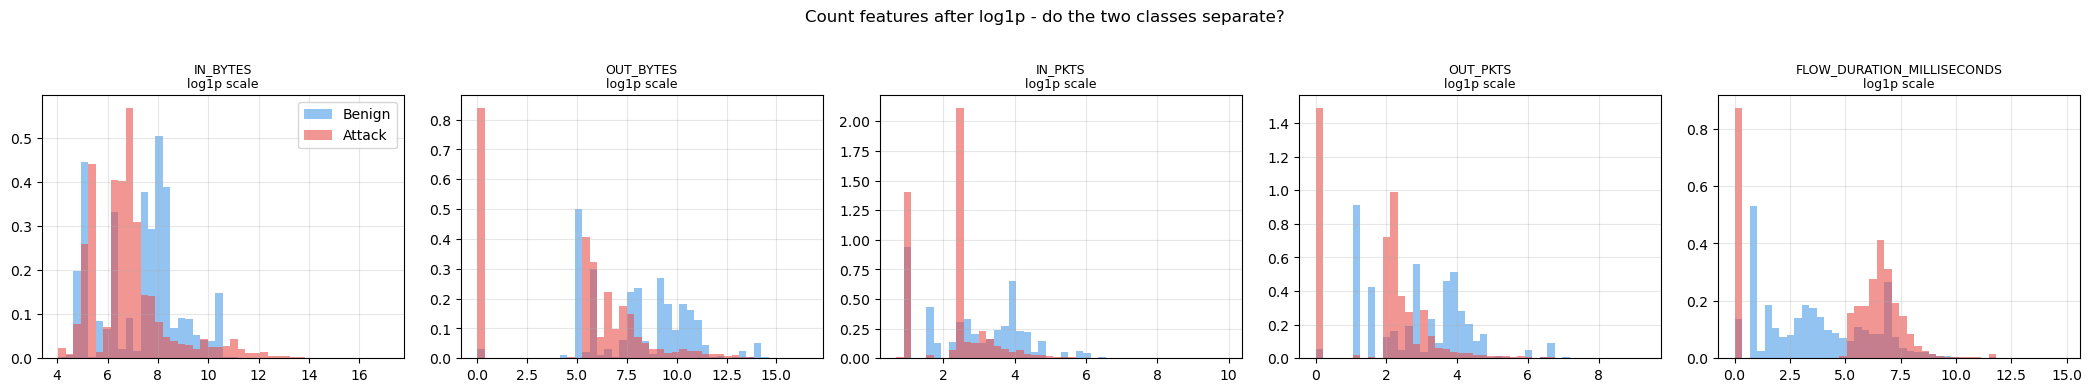

5) Evidence-based hints
   heavy-tailed (|skew| > 5): ['IN_BYTES', 'OUT_BYTES', 'IN_PKTS', 'OUT_PKTS', 'FLOW_DURATION_MILLISECONDS']
   skew before -> after log1p: {'IN_BYTES': '153.6 -> 0.1', 'OUT_BYTES': '10.8 -> -0.4', 'IN_PKTS': '69.0 -> 0.2', 'OUT_PKTS': '10.1 -> 0.2', 'FLOW_DURATION_MILLISECONDS': '170.8 -> 0.2'}
   TCP_FLAGS max = 30  ->  fits in 8 bits: it is a flag BITMASK (FIN, SYN, RST, PSH, ACK, URG, ECE, CWR);
     the number 27 means 'FIN+SYN+ACK+PSH', not 'a bit more than 25'. Bit decomposition is a natural fix.
   PROTOCOL: 255 distinct values -> one-hot encoding is cheap and meaningful
   L7_PROTO: 158 distinct values -> one-hot encoding is cheap and meaningful
   the 20 most common destination ports cover 60.1% of all flows -> top-K one-hot + 'other' is viable

(These are hints from the data. Cell 3 turns them into concrete candidate representations,
 and Cell 4 tests every candidate fairly on the validation set.)


In [67]:
# =====================================================================
# ANN v2 - STEP 2 / CELL 2 : FEATURE AUDIT (no training, nothing modified)
# PURPOSE: look at the 10 raw inputs and decide, WITH EVIDENCE, which ones
#          need a better representation for a neural network.
# STATUS : NEW. Uses X_train / y_train (unscaled) only - the test set is not touched.
# =====================================================================
from sklearn.metrics import roc_auc_score

Xa = X_train.copy()
ya = np.asarray(y_train).astype(int)

COUNT_FEATS = [c for c in ["IN_BYTES", "OUT_BYTES", "IN_PKTS", "OUT_PKTS", "FLOW_DURATION_MILLISECONDS"] if c in Xa.columns]
CODE_FEATS  = [c for c in ["PROTOCOL", "L7_PROTO", "TCP_FLAGS"] if c in Xa.columns]
PORT_FEATS  = [c for c in ["L4_SRC_PORT", "L4_DST_PORT"] if c in Xa.columns]

# ---------- 1. one row of statistics per feature ----------
rows = []
for c in Xa.columns:
    x  = Xa[c].astype(float)
    vc = x.value_counts()
    auc = roc_auc_score(ya, x)
    row = {
        "feature": c,
        "distinct values": int(x.nunique()),
        "min": x.min(), "median": x.median(), "max": x.max(),
        "% zeros": (x == 0).mean() * 100,
        "skew": x.skew(),
        "skew after log1p": np.log1p(x).skew() if x.min() >= 0 else np.nan,
        "top value": vc.index[0], "top value share %": vc.iloc[0] / len(x) * 100,
        "single-feature AUC": max(auc, 1 - auc),      # how well this ONE raw feature separates attack / benign
    }
    rows.append(row)
feat_audit = pd.DataFrame(rows).set_index("feature")
print("1) Raw feature statistics (training set, unscaled)\n")
display(feat_audit.round(3))

# ---------- 2. attack rate per value for the coded features ----------
def attack_rate_table(col, top=8):
    t = (pd.DataFrame({"value": Xa[col].values, "y": ya}).groupby("value")["y"]
           .agg(["size", "mean"]).sort_values("size", ascending=False).head(top))
    t.columns = ["flows", "attack rate"]
    t["share of all flows"] = t["flows"] / len(Xa)
    return t

print("\n2) Most common values of the CODED features and how often each one is an attack")
for c in CODE_FEATS + ["L4_DST_PORT"]:
    if c in Xa.columns:
        n_top = 12 if c == "L4_DST_PORT" else 8
        print(f"\n--- {c}  ({Xa[c].nunique()} distinct values) ---")
        display(attack_rate_table(c, n_top).round(4))

# ---------- 3. ports grouped by IANA range ----------
print("\n3) Ports grouped by range (well-known < 1024, registered 1024-49151, dynamic >= 49152)")
for c in PORT_FEATS:
    grp = pd.cut(Xa[c], bins=[-1, 1023, 49151, 65535], labels=["well-known", "registered", "dynamic"])
    t = pd.DataFrame({"g": grp.values, "y": ya}).groupby("g", observed=True)["y"].agg(["size", "mean"])
    t.columns = ["flows", "attack rate"]
    print(f"\n--- {c} ---"); display(t.round(4))

# ---------- 4. count features: raw vs log1p, split by class ----------
if COUNT_FEATS:
    fig, axes = plt.subplots(1, len(COUNT_FEATS), figsize=(4.2 * len(COUNT_FEATS), 3.8))
    for ax, c in zip(np.atleast_1d(axes), COUNT_FEATS):
        v = np.log1p(Xa[c].astype(float))
        bins = np.linspace(v.min(), v.max(), 45)
        ax.hist(v[ya == 0], bins=bins, alpha=0.6, density=True, color="#4C9BE8", label="Benign")
        ax.hist(v[ya == 1], bins=bins, alpha=0.6, density=True, color="#E8514C", label="Attack")
        ax.set_title(f"{c}\nlog1p scale", fontsize=9); ax.grid(alpha=0.3)
    np.atleast_1d(axes)[0].legend()
    plt.suptitle("Count features after log1p - do the two classes separate?", y=1.02)
    plt.tight_layout(); plt.show()

# ---------- 5. what the evidence suggests ----------
print("5) Evidence-based hints")
heavy = [c for c in COUNT_FEATS if abs(feat_audit.loc[c, "skew"]) > 5]
print(f"   heavy-tailed (|skew| > 5): {heavy if heavy else 'none'}")
if heavy:
    drop = feat_audit.loc[heavy, ["skew", "skew after log1p"]].round(1)
    print("   skew before -> after log1p:", {c: f"{r['skew']} -> {r['skew after log1p']}" for c, r in drop.iterrows()})
if "TCP_FLAGS" in Xa.columns:
    mx = Xa["TCP_FLAGS"].max()
    print(f"   TCP_FLAGS max = {mx:.0f}  ->  " + ("fits in 8 bits: it is a flag BITMASK (FIN, SYN, RST, PSH, ACK, URG, ECE, CWR);\n"
          "     the number 27 means 'FIN+SYN+ACK+PSH', not 'a bit more than 25'. Bit decomposition is a natural fix."
          if mx <= 255 else "larger than 255 - unexpected, check the data."))
for c in [c for c in ["PROTOCOL", "L7_PROTO"] if c in Xa.columns]:
    print(f"   {c}: {Xa[c].nunique()} distinct values -> one-hot encoding is cheap and meaningful")
if "L4_DST_PORT" in Xa.columns:
    top20 = Xa["L4_DST_PORT"].value_counts().head(20).sum() / len(Xa)
    print(f"   the 20 most common destination ports cover {top20:.1%} of all flows -> top-K one-hot + 'other' is viable")
print("\n(These are hints from the data. Cell 3 turns them into concrete candidate representations,\n"
      " and Cell 4 tests every candidate fairly on the validation set.)")

In [68]:
# =====================================================================
# ANN v2 - STEP 2 / CELL 3 : BUILD THE CANDIDATE INPUT REPRESENTATIONS (no training)
# PURPOSE: turn the 10 raw features into 5 progressively better input sets (R0 ... R4),
#          using exactly what the feature audit showed. Each step ADDS one idea,
#          so Cell 4 can measure what every idea is worth.
# STATUS : NEW. Your X_train_scaled / scaler / ann_model are NOT modified.
#          Everything is fitted on the TRAINING part only; validation and test are only transformed.
# =====================================================================
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# ---------- 1. raw (unscaled) copies of YOUR existing train / validation split ----------
# Same arguments as in the setup cell -> the same rows end up in the same sets.
X_tr_raw, X_val_raw, y_tr_chk, y_val_chk = train_test_split(
    X_train, y_train.values, test_size=CONFIG["val_size"], stratify=y_train.values, random_state=SEED)

split_ok = (np.allclose(scaler.transform(X_tr_raw), X_tr) and np.allclose(scaler.transform(X_val_raw), X_val)
            and np.array_equal(y_tr_chk, y_tr) and np.array_equal(y_val_chk, y_val))
print("Raw split is identical to your existing X_tr / X_val split:", split_ok)
assert split_ok, "The split does not match - check CONFIG['val_size'] and SEED."


# ---------- 2. the feature builder (one small class, easy to move into the web app later) ----------
class NIDSFeatureBuilder:
    COUNTS    = ["IN_BYTES", "OUT_BYTES", "IN_PKTS", "OUT_PKTS", "FLOW_DURATION_MILLISECONDS"]
    FLAG_BITS = {"FIN": 1, "SYN": 2, "RST": 4, "PSH": 8, "ACK": 16, "URG": 32, "ECE": 64, "CWR": 128}

    def __init__(self, log_counts=False, flag_bits=False, proto_onehot=False, port_features=False,
                 min_count=50, max_cats=40, top_ports=15):
        self.log_counts, self.flag_bits = log_counts, flag_bits
        self.proto_onehot, self.port_features = proto_onehot, port_features
        self.min_count, self.max_cats, self.top_ports = min_count, max_cats, top_ports

    # ---- learn everything from the TRAINING rows only ----
    def fit(self, X):
        cont = list(X.columns)
        if self.flag_bits:    cont.remove("TCP_FLAGS")                  # replaced by flag bits
        if self.proto_onehot: cont.remove("PROTOCOL"); cont.remove("L7_PROTO")   # replaced by one-hot columns
        self.cont_cols_ = cont
        self.scaler_ = StandardScaler().fit(self._cont(X))
        if self.flag_bits:                                              # keep only bits that actually occur
            f = X["TCP_FLAGS"].astype(int).values
            self.bits_ = [(n, b) for n, b in self.FLAG_BITS.items() if 0 < ((f & b) > 0).mean() < 1]
        if self.proto_onehot:                                           # frequent categories get their own column
            self.proto_vals_ = self._frequent(X["PROTOCOL"])
            self.l7_vals_    = self._frequent(X["L7_PROTO"])
        if self.port_features:
            self.top_ports_ = list(X["L4_DST_PORT"].value_counts().head(self.top_ports).index)
        self.feature_names_ = self._blocks(X.iloc[:5])[0]
        return self

    def transform(self, X):
        return self._blocks(X)[1]

    # ---- helpers ----
    def _frequent(self, s):
        vc = s.value_counts()
        return list(vc[vc >= self.min_count].head(self.max_cats).index)

    def _cont(self, X):
        C = X[self.cont_cols_].astype(float).copy()
        if self.log_counts:
            for c in self.COUNTS:
                C[c] = np.log1p(np.clip(C[c], 0, None))                 # log(1 + x): tames the huge tails, keeps 0 -> 0
        return C.values

    def _blocks(self, X):
        names, mats = [], []
        mats.append(self.scaler_.transform(self._cont(X)))              # block 1: continuous, standardised
        names += [f"log1p({c})" if (self.log_counts and c in self.COUNTS) else c for c in self.cont_cols_]

        if self.flag_bits:                                              # block 2: TCP flag bits (0/1)
            f = X["TCP_FLAGS"].astype(int).values
            for n, b in self.bits_:
                names.append(f"flag_{n}"); mats.append(((f & b) > 0).astype(float)[:, None])

        if self.proto_onehot:                                           # block 3: one-hot with an 'other' bucket
            for col, vals, tag in [("PROTOCOL", self.proto_vals_, "proto"), ("L7_PROTO", self.l7_vals_, "l7")]:
                x = X[col].values
                for v in vals:
                    names.append(f"{tag}={v:g}"); mats.append((x == v).astype(float)[:, None])
                names.append(f"{tag}=other"); mats.append((~np.isin(x, vals)).astype(float)[:, None])

        if self.port_features:                                          # block 4: port identity features
            for c, tag in [("L4_SRC_PORT", "src"), ("L4_DST_PORT", "dst")]:
                x = X[c].values
                names += [f"{tag}_port=0", f"{tag}_port_wellknown", f"{tag}_port_registered", f"{tag}_port_dynamic"]
                mats.append(np.column_stack([x == 0, (x >= 1) & (x <= 1023),
                                             (x >= 1024) & (x <= 49151), x >= 49152]).astype(float))
            xd = X["L4_DST_PORT"].values
            for p in self.top_ports_:
                names.append(f"dst_port={p:g}"); mats.append((xd == p).astype(float)[:, None])

        return names, np.hstack(mats).astype("float32")


# ---------- 3. the five candidates: each one adds ONE idea to the previous ----------
REP_LABELS = {
    "R0": "raw features, scaled            (= your ANN v1 input)",
    "R1": "R0 + log1p on the 5 count features",
    "R2": "R1 + TCP flags split into bits",
    "R3": "R2 + one-hot PROTOCOL and L7_PROTO",
    "R4": "R3 + port features (port=0, port range, top destination ports)",
}
REP_SPECS = {
    "R0": dict(),
    "R1": dict(log_counts=True),
    "R2": dict(log_counts=True, flag_bits=True),
    "R3": dict(log_counts=True, flag_bits=True, proto_onehot=True),
    "R4": dict(log_counts=True, flag_bits=True, proto_onehot=True, port_features=True),
}

REPS = {}
for key, kw in REP_SPECS.items():
    b = NIDSFeatureBuilder(**kw).fit(X_tr_raw)                           # fit on training rows only
    REPS[key] = {"builder": b, "kwargs": kw, "names": b.feature_names_,
                 "X_tr": b.transform(X_tr_raw), "X_val": b.transform(X_val_raw)}
# (the test set is deliberately NOT transformed yet - that happens once, at the very end)

# ---------- 4. sanity checks ----------
rows = []
for key, r in REPS.items():
    A = r["X_tr"]; n_cont = len(r["builder"].cont_cols_)
    rows.append({"Representation": key, "Inputs": A.shape[1], "NaN / inf": int((~np.isfinite(A)).sum()),
                 "continuous mean (train)": float(A[:, :n_cont].mean()),
                 "continuous std (train)":  float(A[:, :n_cont].std(axis=0).mean()),
                 "Description": REP_LABELS[key]})
print("\nCandidate input sets (training rows: %d, validation rows: %d)\n" % (len(X_tr_raw), len(X_val_raw)))
display(pd.DataFrame(rows).set_index("Representation").round(4))

diff = np.abs(REPS["R0"]["X_tr"] - X_tr)
print(f"R0 vs your existing X_tr: mean difference = {diff.mean():.5f}, max difference = {diff.max():.4f}")
print("   (expected to be small but not zero: the scaler is now fitted on the 80% training part instead of all of X_train;\n"
      "    the max is largest in heavy-tailed columns such as IN_BYTES, where a few huge flows shift the mean and std.)")

# ---------- 5. what was learned from the data (so you can see the choices) ----------
b4 = REPS["R4"]["builder"]
print("\nChoices made by fitting on the training rows:")
print("  TCP flag bits kept        :", [n for n, _ in b4.bits_])
print("  PROTOCOL categories       :", [f"{v:g}" for v in b4.proto_vals_], "+ other")
print(f"  L7_PROTO categories       : {len(b4.l7_vals_)} frequent values + other")
print("  top destination ports     :", [f"{p:g}" for p in b4.top_ports_])

names4 = REPS["R4"]["names"]
blocks = {"continuous": sum(1 for n in names4 if not n.startswith(("flag_", "proto=", "l7=", "src_port", "dst_port"))),
          "TCP flag bits": sum(n.startswith("flag_") for n in names4),
          "PROTOCOL one-hot": sum(n.startswith("proto=") for n in names4),
          "L7_PROTO one-hot": sum(n.startswith("l7=") for n in names4),
          "port features": sum(n.startswith(("src_port", "dst_port")) for n in names4)}
print("\nR4 input columns by block:", blocks, "-> total", sum(blocks.values()))

# ---------- 6. quick look: how often is each binary column 'on', and how often is it an attack? ----------
A, yy = REPS["R4"]["X_tr"], y_tr
bin_idx = [i for i, n in enumerate(names4) if n.startswith(("flag_", "proto=", "l7=", "src_port", "dst_port"))]
look = pd.DataFrame({"column": [names4[i] for i in bin_idx],
                     "share of flows %": [A[:, i].mean() * 100 for i in bin_idx],
                     "attack rate when ON %": [(yy[A[:, i] == 1].mean() * 100) if A[:, i].sum() else np.nan for i in bin_idx]})
print("\nBinary columns with the highest attack rate (at least 50 flows):")
display(look[look["share of flows %"] * len(A) / 100 >= 50].sort_values("attack rate when ON %", ascending=False).head(12).round(2).reset_index(drop=True))
print("Note: before this app can use ANN v2, NIDSFeatureBuilder must be saved with the model (we will do that at the end).")

Raw split is identical to your existing X_tr / X_val split: True

Candidate input sets (training rows: 128000, validation rows: 32000)



,Inputs,NaN / inf,continuous mean (train),continuous std (train),Description
Representation,,,,,
R0,10,0,0.0,1.0,"raw features, scaled (= your ANN v1..."
R1,10,0,0.0,1.0,R0 + log1p on the 5 count features
R2,14,0,-0.0,1.0,R1 + TCP flags split into bits
R3,41,0,-0.0,1.0,R2 + one-hot PROTOCOL and L7_PROTO
R4,64,0,-0.0,1.0,"R3 + port features (port=0, port range, top de..."


R0 vs your existing X_tr: mean difference = 0.00195, max difference = 18.4858
   (expected to be small but not zero: the scaler is now fitted on the 80% training part instead of all of X_train;
    the max is largest in heavy-tailed columns such as IN_BYTES, where a few huge flows shift the mean and std.)

Choices made by fitting on the training rows:
  TCP flag bits kept        : ['FIN', 'SYN', 'RST', 'PSH', 'ACK']
  PROTOCOL categories       : ['6', '17', '89', '1'] + other
  L7_PROTO categories       : 23 frequent values + other
  top destination ports     : ['53', '80', '5190', '111', '25', '6881', '143', '22', '21', '179', '0', '520', '445', '514', '1723']

R4 input columns by block: {'continuous': 7, 'TCP flag bits': 5, 'PROTOCOL one-hot': 5, 'L7_PROTO one-hot': 24, 'port features': 23} -> total 64

Binary columns with the highest attack rate (at least 50 flows):


,column,share of flows %,attack rate when ON %
0,l7=2.68,0.15,100.00
1,l7=100,0.06,100.00
2,l7=175,0.06,100.00
3,proto=other,0.91,99.23
4,l7=131.7,0.04,98.00
5,src_port=0,1.12,89.47
6,dst_port=0,1.12,89.47
7,dst_port=0,1.12,89.47
8,l7=41,0.10,83.85
9,dst_port=445,0.46,82.20


Note: before this app can use ANN v2, NIDSFeatureBuilder must be saved with the model (we will do that at the end).


In [69]:
# =====================================================================
# ANN v2 - STEP 2 / CELL 3 : BUILD THE CANDIDATE INPUT REPRESENTATIONS (no training)
# PURPOSE: turn the 10 raw features into 5 progressively better input sets (R0 ... R4),
#          using exactly what the feature audit showed. Each step ADDS one idea,
#          so Cell 4 can measure what every idea is worth.
# STATUS : NEW. Your X_train_scaled / scaler / ann_model are NOT modified.
#          Everything is fitted on the TRAINING part only; validation and test are only transformed.
# =====================================================================
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# ---------- 1. raw (unscaled) copies of YOUR existing train / validation split ----------
# Same arguments as in the setup cell -> the same rows end up in the same sets.
X_tr_raw, X_val_raw, y_tr_chk, y_val_chk = train_test_split(
    X_train, y_train.values, test_size=CONFIG["val_size"], stratify=y_train.values, random_state=SEED)

split_ok = (np.allclose(scaler.transform(X_tr_raw), X_tr) and np.allclose(scaler.transform(X_val_raw), X_val)
            and np.array_equal(y_tr_chk, y_tr) and np.array_equal(y_val_chk, y_val))
print("Raw split is identical to your existing X_tr / X_val split:", split_ok)
assert split_ok, "The split does not match - check CONFIG['val_size'] and SEED."


# ---------- 2. the feature builder (one small class, easy to move into the web app later) ----------
class NIDSFeatureBuilder:
    COUNTS    = ["IN_BYTES", "OUT_BYTES", "IN_PKTS", "OUT_PKTS", "FLOW_DURATION_MILLISECONDS"]
    FLAG_BITS = {"FIN": 1, "SYN": 2, "RST": 4, "PSH": 8, "ACK": 16, "URG": 32, "ECE": 64, "CWR": 128}

    def __init__(self, log_counts=False, flag_bits=False, proto_onehot=False, port_features=False,
                 min_count=50, max_cats=40, top_ports=15):
        self.log_counts, self.flag_bits = log_counts, flag_bits
        self.proto_onehot, self.port_features = proto_onehot, port_features
        self.min_count, self.max_cats, self.top_ports = min_count, max_cats, top_ports

    # ---- learn everything from the TRAINING rows only ----
    def fit(self, X):
        cont = list(X.columns)
        if self.flag_bits:    cont.remove("TCP_FLAGS")                  # replaced by flag bits
        if self.proto_onehot: cont.remove("PROTOCOL"); cont.remove("L7_PROTO")   # replaced by one-hot columns
        self.cont_cols_ = cont
        self.scaler_ = StandardScaler().fit(self._cont(X))
        if self.flag_bits:                                              # keep only bits that actually occur
            f = X["TCP_FLAGS"].astype(int).values
            self.bits_ = [(n, b) for n, b in self.FLAG_BITS.items() if 0 < ((f & b) > 0).mean() < 1]
        if self.proto_onehot:                                           # frequent categories get their own column
            self.proto_vals_ = self._frequent(X["PROTOCOL"])
            self.l7_vals_    = self._frequent(X["L7_PROTO"])
        if self.port_features:
            self.top_ports_ = list(X["L4_DST_PORT"].value_counts().head(self.top_ports).index)
        self.feature_names_ = self._blocks(X.iloc[:5])[0]
        return self

    def transform(self, X):
        return self._blocks(X)[1]

    # ---- helpers ----
    def _frequent(self, s):
        vc = s.value_counts()
        return list(vc[vc >= self.min_count].head(self.max_cats).index)

    def _cont(self, X):
        C = X[self.cont_cols_].astype(float).copy()
        if self.log_counts:
            for c in self.COUNTS:
                C[c] = np.log1p(np.clip(C[c], 0, None))                 # log(1 + x): tames the huge tails, keeps 0 -> 0
        return C.values

    def _blocks(self, X):
        names, mats = [], []
        mats.append(self.scaler_.transform(self._cont(X)))              # block 1: continuous, standardised
        names += [f"log1p({c})" if (self.log_counts and c in self.COUNTS) else c for c in self.cont_cols_]

        if self.flag_bits:                                              # block 2: TCP flag bits (0/1)
            f = X["TCP_FLAGS"].astype(int).values
            for n, b in self.bits_:
                names.append(f"flag_{n}"); mats.append(((f & b) > 0).astype(float)[:, None])

        if self.proto_onehot:                                           # block 3: one-hot with an 'other' bucket
            for col, vals, tag in [("PROTOCOL", self.proto_vals_, "proto"), ("L7_PROTO", self.l7_vals_, "l7")]:
                x = X[col].values
                for v in vals:
                    names.append(f"{tag}={v:g}"); mats.append((x == v).astype(float)[:, None])
                names.append(f"{tag}=other"); mats.append((~np.isin(x, vals)).astype(float)[:, None])

        if self.port_features:                                          # block 4: port identity features
            for c, tag in [("L4_SRC_PORT", "src"), ("L4_DST_PORT", "dst")]:
                x = X[c].values
                names += [f"{tag}_port=0", f"{tag}_port_wellknown", f"{tag}_port_registered", f"{tag}_port_dynamic"]
                mats.append(np.column_stack([x == 0, (x >= 1) & (x <= 1023),
                                             (x >= 1024) & (x <= 49151), x >= 49152]).astype(float))
            xd = X["L4_DST_PORT"].values
            for p in self.top_ports_:
                names.append(f"dst_port={p:g}"); mats.append((xd == p).astype(float)[:, None])

        return names, np.hstack(mats).astype("float32")


# ---------- 3. the five candidates: each one adds ONE idea to the previous ----------
REP_LABELS = {
    "R0": "raw features, scaled            (= your ANN v1 input)",
    "R1": "R0 + log1p on the 5 count features",
    "R2": "R1 + TCP flags split into bits",
    "R3": "R2 + one-hot PROTOCOL and L7_PROTO",
    "R4": "R3 + port features (port=0, port range, top destination ports)",
}
REP_SPECS = {
    "R0": dict(),
    "R1": dict(log_counts=True),
    "R2": dict(log_counts=True, flag_bits=True),
    "R3": dict(log_counts=True, flag_bits=True, proto_onehot=True),
    "R4": dict(log_counts=True, flag_bits=True, proto_onehot=True, port_features=True),
}

REPS = {}
for key, kw in REP_SPECS.items():
    b = NIDSFeatureBuilder(**kw).fit(X_tr_raw)                           # fit on training rows only
    REPS[key] = {"builder": b, "kwargs": kw, "names": b.feature_names_,
                 "X_tr": b.transform(X_tr_raw), "X_val": b.transform(X_val_raw)}
# (the test set is deliberately NOT transformed yet - that happens once, at the very end)

# ---------- 4. sanity checks ----------
rows = []
for key, r in REPS.items():
    A = r["X_tr"]; n_cont = len(r["builder"].cont_cols_)
    rows.append({"Representation": key, "Inputs": A.shape[1], "NaN / inf": int((~np.isfinite(A)).sum()),
                 "continuous mean (train)": float(A[:, :n_cont].mean()),
                 "continuous std (train)":  float(A[:, :n_cont].std(axis=0).mean()),
                 "Description": REP_LABELS[key]})
print("\nCandidate input sets (training rows: %d, validation rows: %d)\n" % (len(X_tr_raw), len(X_val_raw)))
display(pd.DataFrame(rows).set_index("Representation").round(4))

diff = np.abs(REPS["R0"]["X_tr"] - X_tr)
print(f"R0 vs your existing X_tr: mean difference = {diff.mean():.5f}, max difference = {diff.max():.4f}")
print("   (expected to be small but not zero: the scaler is now fitted on the 80% training part instead of all of X_train;\n"
      "    the max is largest in heavy-tailed columns such as IN_BYTES, where a few huge flows shift the mean and std.)")

# ---------- 5. what was learned from the data (so you can see the choices) ----------
b4 = REPS["R4"]["builder"]
print("\nChoices made by fitting on the training rows:")
print("  TCP flag bits kept        :", [n for n, _ in b4.bits_])
print("  PROTOCOL categories       :", [f"{v:g}" for v in b4.proto_vals_], "+ other")
print(f"  L7_PROTO categories       : {len(b4.l7_vals_)} frequent values + other")
print("  top destination ports     :", [f"{p:g}" for p in b4.top_ports_])

names4 = REPS["R4"]["names"]
blocks = {"continuous": sum(1 for n in names4 if not n.startswith(("flag_", "proto=", "l7=", "src_port", "dst_port"))),
          "TCP flag bits": sum(n.startswith("flag_") for n in names4),
          "PROTOCOL one-hot": sum(n.startswith("proto=") for n in names4),
          "L7_PROTO one-hot": sum(n.startswith("l7=") for n in names4),
          "port features": sum(n.startswith(("src_port", "dst_port")) for n in names4)}
print("\nR4 input columns by block:", blocks, "-> total", sum(blocks.values()))

# ---------- 6. quick look: how often is each binary column 'on', and how often is it an attack? ----------
A, yy = REPS["R4"]["X_tr"], y_tr
bin_idx = [i for i, n in enumerate(names4) if n.startswith(("flag_", "proto=", "l7=", "src_port", "dst_port"))]
look = pd.DataFrame({"column": [names4[i] for i in bin_idx],
                     "share of flows %": [A[:, i].mean() * 100 for i in bin_idx],
                     "attack rate when ON %": [(yy[A[:, i] == 1].mean() * 100) if A[:, i].sum() else np.nan for i in bin_idx]})
print("\nBinary columns with the highest attack rate (at least 50 flows):")
display(look[look["share of flows %"] * len(A) / 100 >= 50].sort_values("attack rate when ON %", ascending=False).head(12).round(2).reset_index(drop=True))
print("Note: before this app can use ANN v2, NIDSFeatureBuilder must be saved with the model (we will do that at the end).")

Raw split is identical to your existing X_tr / X_val split: True

Candidate input sets (training rows: 128000, validation rows: 32000)



,Inputs,NaN / inf,continuous mean (train),continuous std (train),Description
Representation,,,,,
R0,10,0,0.0,1.0,"raw features, scaled (= your ANN v1..."
R1,10,0,0.0,1.0,R0 + log1p on the 5 count features
R2,14,0,-0.0,1.0,R1 + TCP flags split into bits
R3,41,0,-0.0,1.0,R2 + one-hot PROTOCOL and L7_PROTO
R4,64,0,-0.0,1.0,"R3 + port features (port=0, port range, top de..."


R0 vs your existing X_tr: mean difference = 0.00195, max difference = 18.4858
   (expected to be small but not zero: the scaler is now fitted on the 80% training part instead of all of X_train;
    the max is largest in heavy-tailed columns such as IN_BYTES, where a few huge flows shift the mean and std.)

Choices made by fitting on the training rows:
  TCP flag bits kept        : ['FIN', 'SYN', 'RST', 'PSH', 'ACK']
  PROTOCOL categories       : ['6', '17', '89', '1'] + other
  L7_PROTO categories       : 23 frequent values + other
  top destination ports     : ['53', '80', '5190', '111', '25', '6881', '143', '22', '21', '179', '0', '520', '445', '514', '1723']

R4 input columns by block: {'continuous': 7, 'TCP flag bits': 5, 'PROTOCOL one-hot': 5, 'L7_PROTO one-hot': 24, 'port features': 23} -> total 64

Binary columns with the highest attack rate (at least 50 flows):


,column,share of flows %,attack rate when ON %
0,l7=2.68,0.15,100.00
1,l7=100,0.06,100.00
2,l7=175,0.06,100.00
3,proto=other,0.91,99.23
4,l7=131.7,0.04,98.00
5,src_port=0,1.12,89.47
6,dst_port=0,1.12,89.47
7,dst_port=0,1.12,89.47
8,l7=41,0.10,83.85
9,dst_port=445,0.46,82.20


Note: before this app can use ANN v2, NIDSFeatureBuilder must be saved with the model (we will do that at the end).


Reference points (validation set)
  ANN v1 (saved)  PR-AUC 0.9096   |   Random Forest (same 80%)  PR-AUC 0.9750   (4s)

Training 5 representations x 3 seeds (max 25 epochs, patience 4) ...
  R0 seed 1:  PR-AUC 0.9176 | recall@1%FPR 0.809 | 25 epochs | 43s

  R0 seed 2:  PR-AUC 0.9003 | recall@1%FPR 0.755 | 25 epochs | 46s
  R0 seed 3:  PR-AUC 0.8927 | recall@1%FPR 0.801 | 25 epochs | 46s
  R1 seed 1:  PR-AUC 0.9356 | recall@1%FPR 0.861 | 25 epochs | 45s
  R1 seed 2:  PR-AUC 0.9331 | recall@1%FPR 0.852 | 25 epochs | 44s
  R1 seed 3:  PR-AUC 0.9367 | recall@1%FPR 0.863 | 25 epochs | 45s
  R2 seed 1:  PR-AUC 0.9484 | recall@1%FPR 0.884 | 25 epochs | 43s
  R2 seed 2:  PR-AUC 0.9456 | recall@1%FPR 0.880 | 25 epochs | 44s
  R2 seed 3:  PR-AUC 0.9502 | recall@1%FPR 0.882 | 25 epochs | 44s
  R3 seed 1:  PR-AUC 0.9696 | recall@1%FPR 0.912 | 25 epochs | 43s
  R3 seed 2:  PR-AUC 0.9677 | recall@1%FPR 0.911 | 25 epochs | 40s
  R3 seed 3:  PR-AUC 0.9566 | recall@1%FPR 0.889 | 12 epochs | 22s
  R4 s

,inputs,pr_auc,roc_auc,recall@FPR0.5%,recall@FPR1%,precision@recall95%,precision@0.5,recall@0.5,fpr@0.5,f1@0.5,epochs run
R0,10,0.9036 ± 0.0128,0.9922 ± 0.0007,0.6240 ± 0.0907,0.7882 ± 0.0290,0.7143 ± 0.0074,0.6192 ± 0.0008,0.9874 ± 0.0020,0.0432 ± 0.0002,0.7611 ± 0.0001,25.0
R1,10,0.9351 ± 0.0019,0.9957 ± 0.0001,0.7304 ± 0.0298,0.8585 ± 0.0061,0.7780 ± 0.0042,0.7027 ± 0.0028,0.9965 ± 0.0003,0.0300 ± 0.0004,0.8242 ± 0.0018,25.0
R2,14,0.9481 ± 0.0023,0.9963 ± 0.0001,0.7869 ± 0.0231,0.8819 ± 0.0019,0.7876 ± 0.0043,0.7011 ± 0.0040,0.9970 ± 0.0005,0.0302 ± 0.0006,0.8233 ± 0.0028,25.0
R3,41,0.9646 ± 0.0071,0.9972 ± 0.0006,0.8488 ± 0.0124,0.9041 ± 0.0132,0.7985 ± 0.0166,0.7057 ± 0.0035,0.9967 ± 0.0008,0.0295 ± 0.0005,0.8264 ± 0.0026,20.7
R4,64,0.9709 ± 0.0005,0.9977 ± 0.0000,0.8618 ± 0.0032,0.9147 ± 0.0042,0.8091 ± 0.0023,0.7116 ± 0.0023,0.9969 ± 0.0007,0.0287 ± 0.0003,0.8304 ± 0.0014,25.0
ANN v1 (saved),10,0.9096,0.9926,0.6368,0.8403,0.7160,0.6409,0.9878,0.0393,0.7774,-
Random Forest (same 80%),10,0.9750,0.9981,0.8874,0.9312,0.8373,0.8665,0.9326,0.0102,0.8984,-



Gain of each step over the previous one (PR-AUC), compared with seed-to-seed noise:
  R0 -> R1:  +0.0316   (noise ≈ 0.0128)  -> clear gain    [R0 + log1p on the 5 count features]
  R1 -> R2:  +0.0129   (noise ≈ 0.0023)  -> clear gain    [R1 + TCP flags split into bits]
  R2 -> R3:  +0.0166   (noise ≈ 0.0071)  -> clear gain    [R2 + one-hot PROTOCOL and L7_PROTO]
  R3 -> R4:  +0.0063   (noise ≈ 0.0071)  -> within noise / negligible    [R3 + port features (port=0, port range, top destination ports)]

Best representation by PR-AUC: R4  (0.9709)   |   R0: 0.9036   |   Random Forest: 0.9750
The better inputs close 94% of the PR-AUC gap between R0 and the Random Forest.


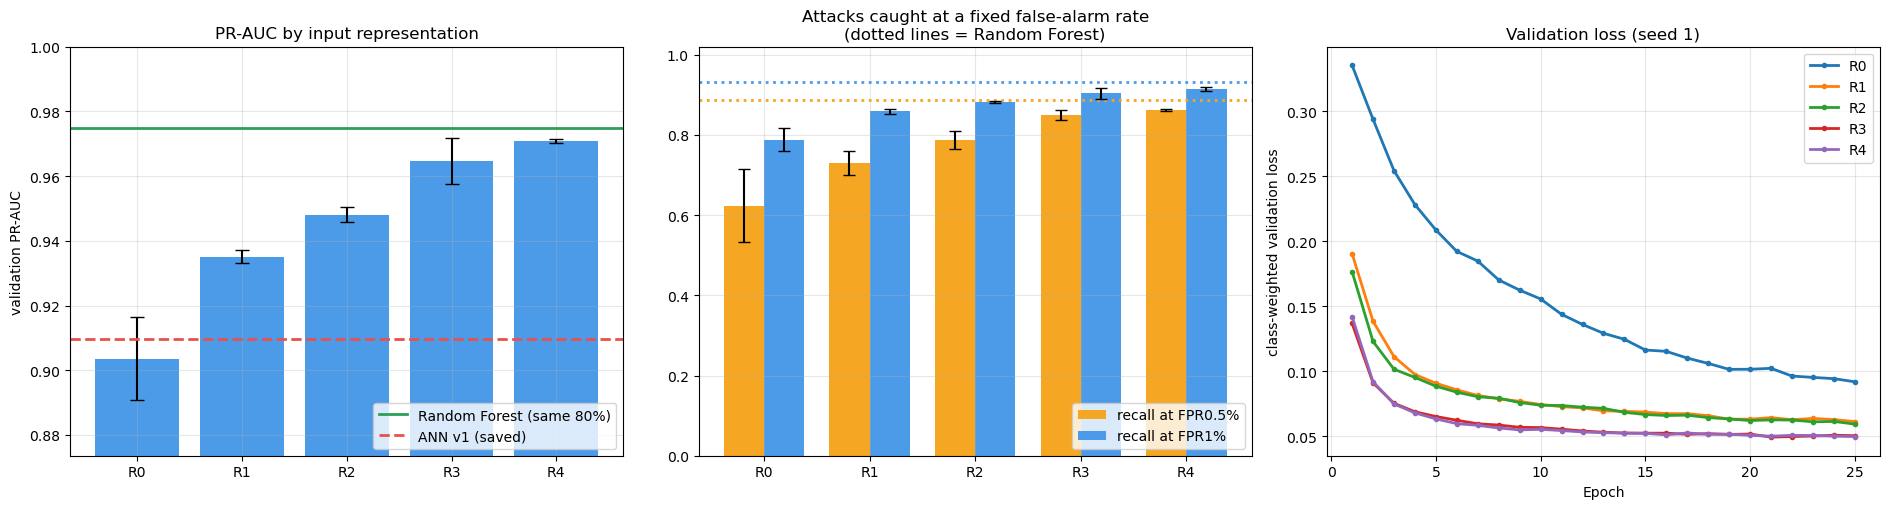

In [71]:
# =====================================================================
# ANN v2 - STEP 2 / CELL 4 : DOES A BETTER INPUT REPRESENTATION HELP?   (this cell TRAINS models)
# PURPOSE: train the SAME 64-32-1 network on R0 ... R4 (3 random seeds each) and compare them on the
#          VALIDATION set. A fresh Random Forest trained on the same 80% gives a fair yardstick.
# STATUS : NEW. Your ann_model, X_tr, X_val, class_weight_dict, CONFIG are only read.
#          The TEST set is not used anywhere in this cell.
# TIME   : roughly 10-20 minutes on a CPU (15 trainings + 1 Random Forest). One line per run is printed.
#          Tip: set QUICK = True first for a ~3 minute rehearsal.
# =====================================================================
import time, gc
from sklearn.base import clone
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, average_precision_score

QUICK  = False                      # True = 1 seed, 10 epochs (a fast rehearsal, ~2 minutes)
SEEDS  = [1] if QUICK else [1, 2, 3]
EPOCHS = 10 if QUICK else 25        # upper limit - EarlyStopping usually stops earlier
PATIENCE = 4


# ---------- 1. ANN v2 builder: same architecture as v1, but the SEED and the number of inputs are arguments ----------
# (your build_ann() always uses SEED = 42 and 10 inputs, so it cannot be used for multi-seed runs;
#  this function is reused by the next steps: optimizers, dropout, activations ..
CONFIG = {"hidden_units": [64, 32], "hidden_activation": "relu", "dropout": 0.2, "learning_rate": 0.001, "batch_size": 256}
def build_ann_v2(n_inputs, seed, hidden_units=CONFIG["hidden_units"], activation=CONFIG["hidden_activation"],
                 dropout=CONFIG["dropout"], learning_rate=CONFIG["learning_rate"], name="ann_v2"):
    keras.utils.set_random_seed(seed)
    model = keras.Sequential(name=name)
    model.add(layers.Input(shape=(n_inputs,), name="flow_features"))
    for i, units in enumerate(hidden_units, start=1):
        model.add(layers.Dense(units, activation=activation, name=f"hidden_{i}"))
        if dropout > 0:
            model.add(layers.Dropout(dropout, name=f"dropout_{i}"))
    model.add(layers.Dense(1, activation="sigmoid", name="output"))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
                  loss="binary_crossentropy", metrics=["accuracy"])
    return model


# ---------- 2. validation metrics (threshold-free ones + the operating point at 0.5) ----------
def val_metrics(y, p, thr=0.5):
    y = np.asarray(y).astype(int)
    fpr_, tpr_, _ = roc_curve(y, p)
    prec_, rec_, _ = precision_recall_curve(y, p)
    pred = p >= thr
    tp = int((pred & (y == 1)).sum());  fp = int((pred & (y == 0)).sum())
    fn = int((~pred & (y == 1)).sum()); tn = int((~pred & (y == 0)).sum())
    ok = rec_ >= 0.95
    prec = tp / max(tp + fp, 1); rec = tp / max(tp + fn, 1)
    return {"pr_auc": average_precision_score(y, p), "roc_auc": roc_auc_score(y, p),
            "recall@FPR0.5%": float(np.interp(0.005, fpr_, tpr_)),
            "recall@FPR1%":   float(np.interp(0.01,  fpr_, tpr_)),
            "precision@recall95%": float(prec_[ok].max()) if ok.any() else float("nan"),
            "precision@0.5": prec, "recall@0.5": rec, "fpr@0.5": fp / (fp + tn),
            "f1@0.5": 2 * prec * rec / max(prec + rec, 1e-12)}


# ---------- 3. reference points on the SAME validation rows ----------
print("Reference points (validation set)")
p_v1 = ann_model.predict(X_val, batch_size=2048, verbose=0).ravel()          # your saved ANN v1
ref_v1 = val_metrics(y_val, p_v1)

t0 = time.time()
rf_ref = clone(rf_model).set_params(n_jobs=-1)                               # same settings as YOUR forest ...
rf_ref.fit(X_tr_raw, y_tr)                                                   # ... but trained on the 80% only (no leakage)
ref_rf = val_metrics(y_val, rf_ref.predict_proba(X_val_raw)[:, 1])
print(f"  ANN v1 (saved)  PR-AUC {ref_v1['pr_auc']:.4f}   |   Random Forest (same 80%)  PR-AUC {ref_rf['pr_auc']:.4f}"
      f"   ({time.time() - t0:.0f}s)")


# ---------- 4. train every representation x seed ----------
runs, curves = [], {}
print(f"\nTraining {len(REPS)} representations x {len(SEEDS)} seeds (max {EPOCHS} epochs, patience {PATIENCE}) ...")
for key, rep in REPS.items():
    for seed in SEEDS:
        t0 = time.time()
        model = build_ann_v2(rep["X_tr"].shape[1], seed)
        hist = model.fit(rep["X_tr"], y_tr,
                         validation_data=(rep["X_val"], y_val, w_val),        # class-weighted, like the training loss
                         epochs=EPOCHS, batch_size=CONFIG["batch_size"], class_weight=class_weight_dict,
                         callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE,
                                                                  restore_best_weights=True)],
                         verbose=0)
        p = model(rep["X_val"], training=False).numpy().ravel()          # direct call: avoids retracing warnings in a loop
        m = val_metrics(y_val, p)
        m.update(rep=key, seed=seed, inputs=rep["X_tr"].shape[1], epochs=len(hist.history["loss"]),
                 best_val_loss=min(hist.history["val_loss"]), seconds=time.time() - t0)
        runs.append(m); curves[(key, seed)] = hist.history["val_loss"]
        print(f"  {key} seed {seed}:  PR-AUC {m['pr_auc']:.4f} | recall@1%FPR {m['recall@FPR1%']:.3f} | "
              f"{m['epochs']} epochs | {m['seconds']:.0f}s")
        keras.backend.clear_session(); gc.collect()

rep_runs_df = pd.DataFrame(runs)

# ---------- 5. summary: mean +/- std over seeds ----------
cols = ["pr_auc", "roc_auc", "recall@FPR0.5%", "recall@FPR1%", "precision@recall95%",
        "precision@0.5", "recall@0.5", "fpr@0.5", "f1@0.5"]
rep_summary = rep_runs_df.groupby("rep")[cols].mean()
rep_std     = rep_runs_df.groupby("rep")[cols].std().fillna(0)

show = rep_summary.copy().astype(object)
for c in cols:
    show[c] = [f"{rep_summary.loc[r, c]:.4f} ± {rep_std.loc[r, c]:.4f}" for r in rep_summary.index]
show.insert(0, "inputs", [REPS[r]["X_tr"].shape[1] for r in rep_summary.index])
show["epochs run"] = rep_runs_df.groupby("rep")["epochs"].mean().round(1)
ref_rows = pd.DataFrame({c: [f"{ref_v1[c]:.4f}", f"{ref_rf[c]:.4f}"] for c in cols},
                        index=["ANN v1 (saved)", "Random Forest (same 80%)"])
ref_rows.insert(0, "inputs", [10, 10]); ref_rows["epochs run"] = ["-", "-"]
print("\nValidation results: mean ± std over seeds (higher is better, except fpr@0.5)\n")
display(pd.concat([show, ref_rows]))

# ---------- 6. what did each idea add? ----------
print("\nGain of each step over the previous one (PR-AUC), compared with seed-to-seed noise:")
prev = None
for r in rep_summary.index:
    if prev is not None:
        delta = rep_summary.loc[r, "pr_auc"] - rep_summary.loc[prev, "pr_auc"]
        noise = max(rep_std.loc[r, "pr_auc"], rep_std.loc[prev, "pr_auc"])
        need = max(2 * noise, 0.003)                      # bigger than the noise AND at least 0.3 PR-AUC points
        verdict = "clear gain" if delta > need else ("clear loss" if delta < -need else "within noise / negligible")
        print(f"  {prev} -> {r}:  {delta:+.4f}   (noise ≈ {noise:.4f})  -> {verdict}    [{REP_LABELS[r].split('  ')[0].strip()}]")
    prev = r

BEST_REP = rep_summary["pr_auc"].idxmax()
base, best, rf = rep_summary.loc["R0", "pr_auc"], rep_summary.loc[BEST_REP, "pr_auc"], ref_rf["pr_auc"]
print(f"\nBest representation by PR-AUC: {BEST_REP}  ({best:.4f})   |   R0: {base:.4f}   |   Random Forest: {rf:.4f}")
if rf - base > 0.01:
    print(f"The better inputs close {(best - base) / (rf - base) * 100:.0f}% of the PR-AUC gap between R0 and the Random Forest.")
else:
    print("R0 and the Random Forest are already close on validation PR-AUC - there is no real gap to close here.")

# ---------- 7. plots ----------
fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))
x = np.arange(len(rep_summary)); labels = list(rep_summary.index)
axes[0].bar(x, rep_summary["pr_auc"], yerr=rep_std["pr_auc"], capsize=5, color="#4C9BE8")
axes[0].axhline(ref_rf["pr_auc"], color="#2E9E5B", lw=2, label="Random Forest (same 80%)")
axes[0].axhline(ref_v1["pr_auc"], color="#E8514C", lw=2, ls="--", label="ANN v1 (saved)")
axes[0].set_xticks(x); axes[0].set_xticklabels(labels); axes[0].set_ylabel("validation PR-AUC")
lo = min(rep_summary["pr_auc"].min(), ref_v1["pr_auc"]) - 0.03
axes[0].set_ylim(max(lo, 0), 1.0); axes[0].set_title("PR-AUC by input representation"); axes[0].legend(loc="lower right")

w = 0.38
for i, (c, col) in enumerate([("recall@FPR0.5%", "#F5A623"), ("recall@FPR1%", "#4C9BE8")]):
    axes[1].bar(x + (i - 0.5) * w, rep_summary[c], w, yerr=rep_std[c], capsize=4, color=col, label=c.replace("recall@", "recall at "))
    axes[1].axhline(ref_rf[c], color=col, ls=":", lw=2)
axes[1].set_xticks(x); axes[1].set_xticklabels(labels); axes[1].set_ylim(0, 1.02)
axes[1].set_title("Attacks caught at a fixed false-alarm rate\n(dotted lines = Random Forest)"); axes[1].legend(loc="lower right")

for key in REPS:
    v = curves[(key, SEEDS[0])]
    axes[2].plot(range(1, len(v) + 1), v, marker="o", ms=3, lw=2, label=key)
axes[2].set_xlabel("Epoch"); axes[2].set_ylabel("class-weighted validation loss")
axes[2].set_title(f"Validation loss (seed {SEEDS[0]})"); axes[2].legend()
for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()